<a href="https://colab.research.google.com/github/Yisihaq01/breast-histology-calibration/blob/main/Notebooks/03_breakhis_formal_development.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Formal Development-Only Model Selection

## CIS 631 — Breast Histopathology Calibration Research

This notebook implements the formal model-development stage of our breast histopathology calibration study.

The objective is to compare fine-tuned ResNet-18 and EfficientNet-B0 using the previously established patient-grouped three-fold Development partition.

### Experimental restrictions

- Only the **49 BreakHis Development patients** can be used for CNN model development and model selection.
- Only BreakHis **40× images** are used for primary model development.
- Existing patient assignments, Development folds, preprocessing parameters, and patch coordinates must remain unchanged.
- Calibration patients are reserved for fitting post-hoc calibrators after final CNN training.
- Test patients and external BACH/BRACS datasets are excluded from model development.
- Model selection will be based on Development-fold validation results.

The preprocessing parameters remain fixed:

| Parameter | Value |
|---|---|
| Source physical resolution | 0.49 µm/pixel |
| Target physical resolution | 0.50 µm/pixel |
| Patch size | 224 × 224 |
| Grid | 4 × 4 |
| Maximum patches per image | 16 |
| Optical density threshold | 0.08 |
| Saturation threshold | 0.05 |
| Minimum tissue fraction | 0.20 |

### Stage A: Data and fold verification

Before training, we reconstruct the complete Development patch manifest from previously saved patch manifests and verify that all three folds preserve patient-level separation.

No CNN training or held-out performance evaluation is performed during Stage A.


In [ ]:

# ============================================================
# Stage A — Environment and repository setup
# ============================================================

from pathlib import Path
import subprocess
import random

import numpy as np
import pandas as pd

from IPython.display import display

SEED = 631

random.seed(SEED)
np.random.seed(SEED)

REPO_ROOT = Path(
    "/content/breast-histology-calibration"
)

REPO_URL = (
    "https://github.com/Yisihaq01/"
    "breast-histology-calibration.git"
)

if not REPO_ROOT.exists():
    subprocess.run(
        [
            "git",
            "clone",
            REPO_URL,
            str(REPO_ROOT)
        ],
        check=True
    )
else:
    print(
        "Repository folder already exists."
    )

METADATA_DIR = REPO_ROOT / "Metadata"

RESULTS_DIR = (
    REPO_ROOT /
    "results" /
    "formal_development"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Repository:", REPO_ROOT)
print("Seed:", SEED)
print("Metadata directory:", METADATA_DIR)
print("Results directory:", RESULTS_DIR)


Repository: /content/breast-histology-calibration
Seed: 631
Metadata directory: /content/breast-histology-calibration/Metadata
Results directory: /content/breast-histology-calibration/results/formal_development


In [ ]:
# ============================================================
# Diagnose missing repository metadata
# ============================================================

from pathlib import Path
import subprocess

REPO_ROOT = Path(
    "/content/breast-histology-calibration"
)

def git_check(*args):
    result = subprocess.run(
        ["git", "-C", str(REPO_ROOT), *args],
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr)

print("1. Current branch:")
git_check("branch", "--show-current")

print("\n2. Available remote branches:")
git_check("branch", "-r")

print("\n3. Latest commit:")
git_check("log", "-1", "--oneline")

print("\n4. Tracked metadata files:")
git_check("ls-files", "metadata")

print("\n5. Local metadata directory:")

metadata_dir = REPO_ROOT / "metadata"

if metadata_dir.exists():
    for path in sorted(metadata_dir.iterdir()):
        print(path.name)
else:
    print("Metadata directory does not exist.")

print("\n6. Repository status:")
git_check("status", "--short", "--branch")

1. Current branch:
main


2. Available remote branches:
  origin/Calibration_analysis
  origin/HEAD -> origin/main
  origin/main


3. Latest commit:
ae6f0d2 Merge branch 'main' of https://github.com/Yisihaq01/breast-histology-calibration


4. Tracked metadata files:


5. Local metadata directory:
Metadata directory does not exist.

6. Repository status:
## main...origin/main



In [ ]:
# ============================================================
# Check which GitHub branches contain the frozen metadata
# ============================================================

import subprocess
from pathlib import Path

REPO_ROOT = Path(
    "/content/breast-histology-calibration"
)

required_names = [
    "breakhis_40x_final_metadata.csv",
    "breakhis_patient_split.csv",
    "breakhis_development_folds.csv",
    "baseline_train_patch_manifest.csv",
    "baseline_val_patch_manifest.csv",
]

branches = [
    "origin/main",
    "origin/Calibration_analysis"
]

for branch in branches:

    result = subprocess.run(
        [
            "git",
            "-C", str(REPO_ROOT),
            "ls-tree",
            "-r",
            "--name-only",
            branch
        ],
        capture_output=True,
        text=True,
        check=True
    )

    tracked_files = result.stdout.splitlines()

    print(f"\n===== {branch} =====")

    for filename in required_names:

        matches = [
            path for path in tracked_files
            if Path(path).name == filename
        ]

        if matches:
            print("FOUND:", matches[0])
        else:
            print("MISSING:", filename)

# Check if Git is ignoring the metadata directory
print("\n===== Git ignore check =====")

result = subprocess.run(
    [
        "git",
        "-C", str(REPO_ROOT),
        "check-ignore",
        "-v",
        "--no-index",
        "metadata/breakhis_patient_split.csv"
    ],
    capture_output=True,
    text=True
)

print(
    result.stdout.strip()
    or "No matching ignore rule found."
)


===== origin/main =====
FOUND: Metadata/breakhis_40x_final_metadata.csv
FOUND: Metadata/breakhis_patient_split.csv
FOUND: Metadata/breakhis_development_folds.csv
FOUND: Metadata/baseline_train_patch_manifest.csv
FOUND: Metadata/baseline_val_patch_manifest.csv

===== origin/Calibration_analysis =====
FOUND: Metadata/breakhis_40x_final_metadata.csv
FOUND: Metadata/breakhis_patient_split.csv
FOUND: Metadata/breakhis_development_folds.csv
FOUND: Metadata/baseline_train_patch_manifest.csv
FOUND: Metadata/baseline_val_patch_manifest.csv

===== Git ignore check =====
No matching ignore rule found.


In [ ]:
# ============================================================
# Verify corrected GitHub metadata directory
# ============================================================

from pathlib import Path

REPO_ROOT = Path(
    "/content/breast-histology-calibration"
)

METADATA_DIR = REPO_ROOT / "Metadata"

print("Metadata directory:", METADATA_DIR)
print("Directory exists:", METADATA_DIR.exists())

required_files = {
    "final_40x_metadata":
        METADATA_DIR / "breakhis_40x_final_metadata.csv",

    "patient_split":
        METADATA_DIR / "breakhis_patient_split.csv",

    "development_folds":
        METADATA_DIR / "breakhis_development_folds.csv",

    "training_patch_manifest":
        METADATA_DIR / "baseline_train_patch_manifest.csv",

    "validation_patch_manifest":
        METADATA_DIR / "baseline_val_patch_manifest.csv"
}

for name, filepath in required_files.items():
    print(
        f"{name}:",
        "FOUND" if filepath.exists() else "MISSING"
    )

assert all(
    path.exists()
    for path in required_files.values()
)

print(
    "\nPASS: All five frozen metadata files located."
)

Metadata directory: /content/breast-histology-calibration/Metadata
Directory exists: True
final_40x_metadata: FOUND
patient_split: FOUND
development_folds: FOUND
training_patch_manifest: FOUND
validation_patch_manifest: FOUND

PASS: All five frozen metadata files located.


In [ ]:

# ============================================================
# Stage A — Inspect frozen metadata structure
# ============================================================

import pandas as pd

for name, filepath in required_files.items():

    df = pd.read_csv(filepath)

    print("\n" + "=" * 55)
    print(name.upper())
    print("=" * 55)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    if name == "development_folds":
        print("\nFirst 5 fold assignments:")
        display(df.head(5))

    elif name == "patient_split":
        print("\nPatient split counts:")
        print(df["split"].value_counts())

    elif name in [
        "training_patch_manifest",
        "validation_patch_manifest"
    ]:
        print("\nFirst 2 patch records:")
        display(df.head(2))



FINAL_40X_METADATA
Rows: 1961
Columns: ['filename', 'relative_path', 'patient_id', 'diagnosis_code', 'diagnosis', 'original_subtype_code', 'original_subtype', 'subtype_code', 'subtype', 'magnification', 'image_number', 'split']

PATIENT_SPLIT
Rows: 81
Columns: ['patient_id', 'diagnosis_code', 'diagnosis', 'subtype_code', 'subtype', 'split']

Patient split counts:
split
development    49
calibration    16
test           16
Name: count, dtype: int64

DEVELOPMENT_FOLDS
Rows: 49
Columns: ['patient_id', 'diagnosis_code', 'diagnosis', 'subtype_code', 'subtype', 'split', 'development_fold']

First 5 fold assignments:


,patient_id,diagnosis_code,diagnosis,subtype_code,subtype,split,development_fold
0,14-29960CD,B,Benign,A,Adenosis,development,1
1,14-14134,B,Benign,F,Fibroadenoma,development,1
2,14-21998CD,B,Benign,F,Fibroadenoma,development,1
3,14-13200,B,Benign,TA,Tubular adenoma,development,1
4,14-3411F,B,Benign,TA,Tubular adenoma,development,1



TRAINING_PATCH_MANIFEST
Rows: 12034
Columns: ['patient_id', 'filename', 'relative_path', 'diagnosis', 'label', 'patch_index', 'x', 'y', 'tissue_fraction', 'used_fallback']

First 2 patch records:


,patient_id,filename,relative_path,diagnosis,label,patch_index,x,y,tissue_fraction,used_fallback
0,14-10147,SOB_M_MC-14-10147-40-009.png,BreaKHis_v1/BreaKHis_v1/histology_slides/breas...,Malignant,1,0,0,0,0.578823,False
1,14-10147,SOB_M_MC-14-10147-40-009.png,BreaKHis_v1/BreaKHis_v1/histology_slides/breas...,Malignant,1,1,154,0,0.518634,False



VALIDATION_PATCH_MANIFEST
Rows: 5861
Columns: ['patient_id', 'filename', 'relative_path', 'diagnosis', 'label', 'patch_index', 'x', 'y', 'tissue_fraction', 'used_fallback']

First 2 patch records:


,patient_id,filename,relative_path,diagnosis,label,patch_index,x,y,tissue_fraction,used_fallback
0,14-13200,SOB_B_TA-14-13200-40-012.png,BreaKHis_v1/BreaKHis_v1/histology_slides/breas...,Benign,0,0,0,0,0.928133,False
1,14-13200,SOB_B_TA-14-13200-40-012.png,BreaKHis_v1/BreaKHis_v1/histology_slides/breas...,Benign,0,1,154,0,0.830716,False


In [ ]:
# ============================================================
# Check which GitHub branches contain the frozen metadata
# ============================================================

import subprocess
from pathlib import Path

REPO_ROOT = Path(
    "/content/breast-histology-calibration"
)

required_names = [
    "breakhis_40x_final_metadata.csv",
    "breakhis_patient_split.csv",
    "breakhis_development_folds.csv",
    "baseline_train_patch_manifest.csv",
    "baseline_val_patch_manifest.csv",
]

branches = [
    "origin/main",
    "origin/Calibration_analysis"
]

for branch in branches:

    result = subprocess.run(
        [
            "git",
            "-C", str(REPO_ROOT),
            "ls-tree",
            "-r",
            "--name-only",
            branch
        ],
        capture_output=True,
        text=True,
        check=True
    )

    tracked_files = result.stdout.splitlines()

    print(f"\n===== {branch} =====")

    for filename in required_names:

        matches = [
            path for path in tracked_files
            if Path(path).name == filename
        ]

        if matches:
            print("FOUND:", matches[0])
        else:
            print("MISSING:", filename)

# Check if Git is ignoring the metadata directory
print("\n===== Git ignore check =====")

result = subprocess.run(
    [
        "git",
        "-C", str(REPO_ROOT),
        "check-ignore",
        "-v",
        "--no-index",
        "metadata/breakhis_patient_split.csv"
    ],
    capture_output=True,
    text=True
)

print(
    result.stdout.strip()
    or "No matching ignore rule found."
)


===== origin/main =====
FOUND: Metadata/breakhis_40x_final_metadata.csv
FOUND: Metadata/breakhis_patient_split.csv
FOUND: Metadata/breakhis_development_folds.csv
FOUND: Metadata/baseline_train_patch_manifest.csv
FOUND: Metadata/baseline_val_patch_manifest.csv

===== origin/Calibration_analysis =====
FOUND: Metadata/breakhis_40x_final_metadata.csv
FOUND: Metadata/breakhis_patient_split.csv
FOUND: Metadata/breakhis_development_folds.csv
FOUND: Metadata/baseline_train_patch_manifest.csv
FOUND: Metadata/baseline_val_patch_manifest.csv

===== Git ignore check =====
No matching ignore rule found.


In [ ]:

# ============================================================
# Load and verify frozen Development metadata
# ============================================================

import pandas as pd

image_metadata = pd.read_csv(
    required_files["final_40x_metadata"],
    dtype={"patient_id": str}
)

patient_split = pd.read_csv(
    required_files["patient_split"],
    dtype={"patient_id": str}
)

development_folds = pd.read_csv(
    required_files["development_folds"],
    dtype={"patient_id": str}
)

train_patches = pd.read_csv(
    required_files["training_patch_manifest"],
    dtype={"patient_id": str}
)

val_patches = pd.read_csv(
    required_files["validation_patch_manifest"],
    dtype={"patient_id": str}
)

# Standardize labels without changing stored files
for df in [image_metadata, patient_split, development_folds]:
    df["split"] = df["split"].str.strip().str.lower()

development_folds["development_fold"] = (
    development_folds["development_fold"].astype(int)
)

# Verify original data dimensions
assert len(image_metadata) == 1961
assert len(patient_split) == 81
assert len(development_folds) == 49

assert len(train_patches) == 12034
assert len(val_patches) == 5861

assert image_metadata["patient_id"].nunique() == 81
assert patient_split["patient_id"].nunique() == 81
assert development_folds["patient_id"].nunique() == 49

assert not image_metadata["filename"].duplicated().any()
assert not patient_split["patient_id"].duplicated().any()
assert not development_folds["patient_id"].duplicated().any()

assert image_metadata["magnification"].astype(str).eq("40").all()

# Frozen split membership
DEV_IDS = set(
    patient_split.loc[
        patient_split["split"] == "development",
        "patient_id"
    ]
)

CAL_IDS = set(
    patient_split.loc[
        patient_split["split"] == "calibration",
        "patient_id"
    ]
)

TEST_IDS = set(
    patient_split.loc[
        patient_split["split"] == "test",
        "patient_id"
    ]
)

assert len(DEV_IDS) == 49
assert len(CAL_IDS) == 16
assert len(TEST_IDS) == 16

assert DEV_IDS.isdisjoint(CAL_IDS)
assert DEV_IDS.isdisjoint(TEST_IDS)
assert CAL_IDS.isdisjoint(TEST_IDS)

assert (
    DEV_IDS | CAL_IDS | TEST_IDS
) == set(patient_split["patient_id"])

# Check image split agrees with authoritative patient split
split_lookup = patient_split.set_index("patient_id")["split"]

assert (
    image_metadata["split"]
    == image_metadata["patient_id"].map(split_lookup)
).all()

# Development subset
dev_images = image_metadata.loc[
    image_metadata["patient_id"].isin(DEV_IDS)
].copy()

assert len(dev_images) == 1133
assert dev_images["patient_id"].nunique() == 49

# Verify original Development folds
assert set(development_folds["patient_id"]) == DEV_IDS
assert development_folds["split"].eq("development").all()

fold_counts = (
    development_folds["development_fold"]
    .value_counts()
    .sort_index()
)

assert fold_counts.to_dict() == {
    1: 17,
    2: 16,
    3: 16
}

print("Development patients:", len(DEV_IDS))
print("Calibration patients:", len(CAL_IDS))
print("Test patients:", len(TEST_IDS))

print("\nDevelopment images:", len(dev_images))

print("\nDevelopment fold counts:")
display(fold_counts)

print("\nPASS: Frozen Development metadata verified.")


Development patients: 49
Calibration patients: 16
Test patients: 16

Development images: 1133

Development fold counts:


,count
development_fold,
1,17
2,16
3,16



PASS: Frozen Development metadata verified.


In [ ]:

# ============================================================
# Reconstruct Development patch manifest
# ============================================================

all_patches = pd.concat(
    [train_patches, val_patches],
    ignore_index=True
)

# Check total number of patches and membership
assert len(all_patches) == 17895

assert all_patches["patient_id"].nunique() == 49
assert all_patches["filename"].nunique() == 1133

assert set(all_patches["patient_id"]) == DEV_IDS
assert set(all_patches["filename"]) == set(dev_images["filename"])

# Check for repeated patch identities
assert not all_patches.duplicated(
    ["filename", "patch_index"]
).any()

# Build authoritative image lookup
image_lookup = dev_images.set_index("filename")

for column in [
    "patient_id",
    "diagnosis",
    "relative_path"
]:

    expected = all_patches["filename"].map(
        image_lookup[column]
    )

    assert expected.notna().all(), (
        f"Missing expected values for {column}"
    )

    assert (
        all_patches[column].astype(str).to_numpy()
        == expected.astype(str).to_numpy()
    ).all(), (
        f"Patch/image mismatch in {column}"
    )

# Verify binary labels
expected_labels = (
    all_patches["filename"]
    .map(image_lookup["diagnosis"])
    .eq("Malignant")
    .astype(int)
)

assert (
    all_patches["label"].astype(int).to_numpy()
    == expected_labels.to_numpy()
).all()

# Verify all patches use valid indices
assert all_patches["patch_index"].between(0, 15).all()
assert all_patches["tissue_fraction"].between(0, 1).all()

patches_per_image = (
    all_patches.groupby("filename").size()
)

assert patches_per_image.between(1, 16).all()

# Confirm that the old preliminary split used Fold 1
fold_lookup = development_folds.set_index(
    "patient_id"
)["development_fold"]

original_val_folds = set(
    val_patches["patient_id"].map(fold_lookup)
)

original_train_folds = set(
    train_patches["patient_id"].map(fold_lookup)
)

assert original_val_folds == {1}
assert original_train_folds == {2, 3}

assert set(train_patches["patient_id"]).isdisjoint(
    set(val_patches["patient_id"])
)

# Attach original frozen Development fold
all_patches["development_fold"] = (
    all_patches["patient_id"].map(fold_lookup)
)

assert all_patches["development_fold"].notna().all()

all_patches["development_fold"] = (
    all_patches["development_fold"].astype(int)
)

all_patches = all_patches.sort_values(
    [
        "development_fold",
        "patient_id",
        "filename",
        "patch_index"
    ]
).reset_index(drop=True)

print("Development patients:", all_patches["patient_id"].nunique())
print("Development images:", all_patches["filename"].nunique())
print("Development patches:", len(all_patches))

print("\nPatches per image:")
print(patches_per_image.describe())

print("\nPASS: Frozen Development patch manifest reconstructed.")


Development patients: 49
Development images: 1133
Development patches: 17895

Patches per image:
count    1133.000000
mean       15.794351
std         1.121223
min         1.000000
25%        16.000000
50%        16.000000
75%        16.000000
max        16.000000
dtype: float64

PASS: Frozen Development patch manifest reconstructed.


In [ ]:

# ============================================================
# Prepare patient-grouped three-fold CV
# ============================================================

cv_splits = {}
cv_summary_rows = []

for validation_fold in [1, 2, 3]:

    train_df = all_patches.loc[
        all_patches["development_fold"] != validation_fold
    ].copy()

    val_df = all_patches.loc[
        all_patches["development_fold"] == validation_fold
    ].copy()

    train_patients = set(train_df["patient_id"])
    val_patients = set(val_df["patient_id"])

    # No shared patients
    assert train_patients.isdisjoint(val_patients)

    # Together they cover all Development patients
    assert train_patients | val_patients == DEV_IDS

    # No held-out patients
    assert (
        train_patients | val_patients
    ).isdisjoint(CAL_IDS | TEST_IDS)

    # Save each fold in memory for later model training
    cv_splits[validation_fold] = {
        "train": train_df,
        "validation": val_df
    }

    cv_summary_rows.append({
        "validation_fold": validation_fold,
        "training_patients": len(train_patients),
        "validation_patients": len(val_patients),
        "training_images": train_df["filename"].nunique(),
        "validation_images": val_df["filename"].nunique(),
        "training_patches": len(train_df),
        "validation_patches": len(val_df)
    })

cv_summary = pd.DataFrame(cv_summary_rows)

display(cv_summary)

assert cv_summary["training_patients"].tolist() == [
    32, 33, 33
]

assert cv_summary["validation_patients"].tolist() == [
    17, 16, 16
]

assert cv_summary["validation_images"].sum() == 1133

assert cv_summary["validation_patches"].sum() == 17895

print(
    "\nPASS: All three patient-grouped Development "
    "folds are ready."
)


,validation_fold,training_patients,validation_patients,training_images,validation_images,training_patches,validation_patches
0,1,32,17,761,372,12034,5861
1,2,33,16,702,431,11085,6810
2,3,33,16,803,330,12671,5224



PASS: All three patient-grouped Development folds are ready.


In [ ]:

# ============================================================
# Save verified Development outputs
# ============================================================

from pathlib import Path

METADATA_DIR = REPO_ROOT / "Metadata"

RESULTS_DIR = (
    REPO_ROOT / "results" / "formal_development"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = (
    METADATA_DIR /
    "breakhis_development_all_patch_manifest.csv"
)

summary_path = (
    RESULTS_DIR /
    "development_cv_preflight_summary.csv"
)

all_patches.to_csv(manifest_path, index=False)
cv_summary.to_csv(summary_path, index=False)

# Reopen files to verify they were written correctly
saved_manifest = pd.read_csv(
    manifest_path,
    dtype={"patient_id": str}
)

saved_summary = pd.read_csv(summary_path)

assert len(saved_manifest) == 17895
assert saved_manifest["patient_id"].nunique() == 49

assert len(saved_summary) == 3

print("Saved files:")
print(manifest_path)
print(summary_path)

print("\nPASS: Stage A completed successfully.")


Saved files:
/content/breast-histology-calibration/Metadata/breakhis_development_all_patch_manifest.csv
/content/breast-histology-calibration/results/formal_development/development_cv_preflight_summary.csv

PASS: Stage A completed successfully.


# Stage B — Fine-Tuned ResNet-18

## GPU and Dataset Verification

This stage implements formal ResNet-18 model development using only the frozen 49-patient BreakHis Development cohort.

All three original Development folds will be used for model selection. Calibration, Test, BACH, and BRACS remain excluded.

In [ ]:

# ============================================================
# Verify GPU and PyTorch environment
# ============================================================

import torch
import torchvision
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    device = torch.device("cuda")

    print("GPU:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(f"GPU memory: {gpu_memory:.2f} GB")

else:
    device = torch.device("cpu")

    raise RuntimeError(
        "GPU is not available. "
        "Select T4 GPU in Colab before continuing."
    )

print("\nPASS: GPU environment is ready.")


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

PASS: GPU environment is ready.


In [ ]:

# ============================================================
# Load frozen Development manifest
# ============================================================

from pathlib import Path
import subprocess
import pandas as pd

REPO_ROOT = Path(
    "/content/breast-histology-calibration"
)

REPO_URL = (
    "https://github.com/Yisihaq01/"
    "breast-histology-calibration.git"
)

# Restore repository if the GPU runtime reset /content
if not REPO_ROOT.exists():

    subprocess.run(
        [
            "git",
            "clone",
            REPO_URL,
            str(REPO_ROOT)
        ],
        check=True
    )

METADATA_DIR = REPO_ROOT / "Metadata"

RESULTS_DIR = (
    REPO_ROOT /
    "results" /
    "formal_development"
)

manifest_path = (
    METADATA_DIR /
    "breakhis_development_all_patch_manifest.csv"
)

assert manifest_path.exists(), (
    "Frozen Development manifest is missing. "
    "Restore the committed Stage A file before continuing."
)

all_patches = pd.read_csv(
    manifest_path,
    dtype={"patient_id": str}
)

assert len(all_patches) == 17895

assert (
    all_patches["patient_id"].nunique() == 49
)

assert (
    all_patches["filename"].nunique() == 1133
)

assert set(
    all_patches["development_fold"].unique()
) == {1, 2, 3}

print("Repository:", REPO_ROOT)

print("\nDevelopment patients:",
      all_patches["patient_id"].nunique())

print("Development images:",
      all_patches["filename"].nunique())

print("Development patches:", len(all_patches))

print("\nPatients by fold:")

display(
    all_patches.groupby("development_fold")[
        "patient_id"
    ].nunique()
)

print(
    "\nPASS: Frozen Development manifest "
    "loaded successfully."
)


Repository: /content/breast-histology-calibration

Development patients: 49
Development images: 1133
Development patches: 17895

Patients by fold:


,patient_id
development_fold,
1,17
2,16
3,16



PASS: Frozen Development manifest loaded successfully.


In [ ]:

# ============================================================
# Locate original BreakHis dataset
# ============================================================

import importlib.util
import subprocess
import sys

if importlib.util.find_spec("kagglehub") is None:

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "kagglehub"
        ],
        check=True
    )

import kagglehub

# Reuse an existing dataset location when available
known_root = Path("/kaggle/input/breakhis")

if known_root.exists():

    DATASET_ROOT = known_root

else:

    DATASET_ROOT = Path(
        kagglehub.dataset_download(
            "ambarish/breakhis"
        )
    )

print("BreakHis dataset root:", DATASET_ROOT)
print("Dataset exists:", DATASET_ROOT.exists())

assert DATASET_ROOT.exists()

print("\nTop-level contents:")

for path in sorted(DATASET_ROOT.iterdir())[:15]:
    print("-", path.name)

print("\nPASS: BreakHis dataset located.")


Using Colab cache for faster access to the 'breakhis' dataset.
BreakHis dataset root: /kaggle/input/breakhis
Dataset exists: True

Top-level contents:
- BreaKHis_v1
- Folds.csv

PASS: BreakHis dataset located.


In [ ]:

# ============================================================
# Verify original image paths
# ============================================================

sample_rows = (
    all_patches[
        ["filename", "relative_path", "patient_id"]
    ]
    .drop_duplicates("filename")
    .sample(
        n=5,
        random_state=631
    )
)

print("Checking 5 frozen Development images:\n")

missing_images = []

for _, row in sample_rows.iterrows():

    image_path = (
        DATASET_ROOT /
        row["relative_path"]
    )

    if not image_path.exists():

        missing_images.append(str(image_path))

        print(
            "MISSING:",
            row["filename"]
        )

        continue

    with Image.open(image_path) as img:

        print(
            "FOUND:",
            row["filename"],
            "| Size:",
            img.size,
            "| Mode:",
            img.mode
        )

if missing_images:

    print("\nExample missing path:")
    print(missing_images[0])

    raise FileNotFoundError(
        "One or more frozen image paths could not be resolved. "
        "Check DATASET_ROOT before training."
    )

print(
    "\nPASS: Frozen Development image paths "
    "resolve correctly."
)


Checking 5 frozen Development images:

FOUND: SOB_M_DC-14-12312-40-007.png | Size: (700, 460) | Mode: RGB
FOUND: SOB_M_PC-14-15704-40-008.png | Size: (700, 460) | Mode: RGB
FOUND: SOB_M_MC-14-10147-40-004.png | Size: (700, 460) | Mode: RGB
FOUND: SOB_M_DC-14-13412-40-016.png | Size: (700, 460) | Mode: RGB
FOUND: SOB_M_DC-14-10926-40-004.png | Size: (700, 460) | Mode: RGB

PASS: Frozen Development image paths resolve correctly.


In [ ]:

# ============================================================
# Inspect original frozen preprocessing code
# ============================================================

import json
from pathlib import Path

# Find Notebook 01 in the cloned repository
notebook_candidates = [
    p for p in REPO_ROOT.rglob("*.ipynb")
    if "01_breakhis" in p.name.lower()
]

print("Matching notebooks:")

for path in notebook_candidates:
    print(path.relative_to(REPO_ROOT))

assert notebook_candidates, (
    "Notebook 01 was not found in the repository. "
    "Do not recreate preprocessing from memory."
)

original_notebook = notebook_candidates[0]

with open(
    original_notebook,
    "r",
    encoding="utf-8"
) as f:
    notebook_data = json.load(f)

keywords = [
    "0.49",
    "0.50",
    "lanczos",
    "resample",
    "physical_resolution",
    "target_mpp",
    "source_mpp",
    "resize_image",
    "patch_coordinates"
]

matching_cells = []

for index, cell in enumerate(
    notebook_data["cells"]
):

    if cell["cell_type"] != "code":
        continue

    source = "".join(
        cell.get("source", [])
    )

    source_lower = source.lower()

    if any(
        keyword in source_lower
        for keyword in keywords
    ):
        matching_cells.append(
            (index, source)
        )

print(
    "\nMatching preprocessing cells:",
    len(matching_cells)
)

for index, source in matching_cells[:8]:

    print("\n" + "=" * 65)
    print("NOTEBOOK 01 — CELL", index)
    print("=" * 65)

    print(source[:5000])


Matching notebooks:
Notebooks/01_breakhis_data_audit_and_split.ipynb
Notebooks/01_breakhis_audit.ipynb

Matching preprocessing cells: 8

NOTEBOOK 01 — CELL 57
print("Development images evaluated:",
      len(development_tissue))

print("\nTissue-fraction summary:")
print(
    development_tissue["tissue_fraction"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

NOTEBOOK 01 — CELL 63
# ============================================================
# Frozen preprocessing parameters
# ============================================================

SOURCE_MPP_BREAKHIS = 0.49
TARGET_MPP = 0.50

PATCH_SIZE = 224
GRID_SIZE = 4
MAX_PATCHES = 16

MIN_PATCH_TISSUE_FRACTION = 0.20

OD_THRESHOLD = 0.08
SATURATION_THRESHOLD = 0.05

NOTEBOOK 01 — CELL 64
# ============================================================
# Physical-scale norma

In [ ]:

# ============================================================
# Audit all source paths and patch coordinates
# ============================================================

from PIL import Image
from collections import Counter

# One record per source image
unique_images = (
    all_patches[
        ["filename", "relative_path", "patient_id"]
    ]
    .drop_duplicates("filename")
    .copy()
)

assert len(unique_images) == 1133

missing_paths = []
image_sizes = Counter()

for row in unique_images.itertuples(index=False):

    image_path = (
        DATASET_ROOT / row.relative_path
    )

    if not image_path.is_file():
        missing_paths.append(str(image_path))
        continue

    with Image.open(image_path) as img:
        image_sizes[img.size] += 1

print("Development images checked:", len(unique_images))
print("Missing image paths:", len(missing_paths))

print("\nOriginal image dimensions:")

for size, count in sorted(image_sizes.items()):
    print(f"{size}: {count} images")

assert not missing_paths, (
    f"Missing source images: {missing_paths[:5]}"
)

# Verify saved patch coordinate integrity
assert all_patches[
    ["x", "y", "patch_index"]
].notna().all().all()

for column in ["x", "y", "patch_index"]:

    values = all_patches[column]

    assert (values >= 0).all()

    assert (
        values == values.astype(int)
    ).all()

assert all_patches["patch_index"].between(0, 15).all()

assert not all_patches.duplicated(
    ["filename", "patch_index"]
).any()

print("\nFrozen patch-coordinate ranges:")

print(
    "X:",
    all_patches["x"].min(),
    "to",
    all_patches["x"].max()
)

print(
    "Y:",
    all_patches["y"].min(),
    "to",
    all_patches["y"].max()
)

print(
    "Patch index:",
    all_patches["patch_index"].min(),
    "to",
    all_patches["patch_index"].max()
)

fallback_count = (
    all_patches["used_fallback"]
    .astype(str)
    .str.lower()
    .eq("true")
    .sum()
)

print(
    "\nFallback patches:",
    fallback_count
)

print(
    "\nPASS: All Development image paths "
    "and saved patch coordinates verified."
)


Development images checked: 1133
Missing image paths: 0

Original image dimensions:
(700, 456): 21 images
(700, 460): 1112 images

Frozen patch-coordinate ranges:
X: 0 to 462
Y: 0 to 227
Patch index: 0 to 15

Fallback patches: 0

PASS: All Development image paths and saved patch coordinates verified.


In [ ]:

# ============================================================
# Frozen preprocessing and transformations
# Reproduced from Notebook 01
# ============================================================

import random

import torch
from PIL import Image

from torchvision import transforms
from torchvision.transforms import functional as TF


# Frozen preprocessing parameters
SOURCE_MPP_BREAKHIS = 0.49
TARGET_MPP = 0.50

PATCH_SIZE = 224


def resample_to_target_mpp(
    image,
    source_mpp=SOURCE_MPP_BREAKHIS,
    target_mpp=TARGET_MPP
):
    """
    Resample the source image to 0.50 micrometers/pixel.
    Preserve the original Notebook 01 implementation.
    """

    image = image.convert("RGB")

    scale = source_mpp / target_mpp

    new_width = round(image.width * scale)
    new_height = round(image.height * scale)

    return image.resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS
    )


class RandomRightAngleRotation:

    def __call__(self, image):

        angle = random.choice(
            [0, 90, 180, 270]
        )

        return TF.rotate(
            image,
            angle
        )


# Training: geometric augmentation only
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    RandomRightAngleRotation(),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation: no random augmentation
val_transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Verify original physical-resolution behavior
example_size = (700, 460)

example_image = Image.new(
    "RGB",
    example_size
)

resampled_example = resample_to_target_mpp(
    example_image
)

assert resampled_example.size == (686, 451)

print("Original image:", example_size)
print("Resampled image:", resampled_example.size)

print("\nTraining transformations:")
print(train_transform)

print("\nValidation transformations:")
print(val_transform)

print(
    "\nPASS: Frozen preprocessing "
    "and transformations restored."
)


Original image: (700, 460)
Resampled image: (686, 451)

Training transformations:
Compose(
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transformations:
Compose(
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

PASS: Frozen preprocessing and transformations restored.


In [ ]:

# ============================================================
# BreakHis patch Dataset
# ============================================================

from pathlib import Path

from torch.utils.data import Dataset, DataLoader


class BreakHisPatchDataset(Dataset):

    def __init__(
        self,
        manifest,
        dataset_root,
        transform=None
    ):

        self.manifest = (
            manifest
            .reset_index(drop=True)
            .copy()
        )

        self.dataset_root = Path(
            dataset_root
        )

        self.transform = transform

        required_columns = {
            "relative_path",
            "patient_id",
            "filename",
            "label",
            "patch_index",
            "x",
            "y"
        }

        missing_columns = (
            required_columns
            - set(self.manifest.columns)
        )

        if missing_columns:
            raise ValueError(
                f"Missing manifest columns: "
                f"{missing_columns}"
            )

        if not set(
            self.manifest["label"].unique()
        ).issubset({0, 1}):
            raise ValueError(
                "Dataset labels must be binary."
            )

    def __len__(self):

        return len(self.manifest)

    def __getitem__(self, index):

        row = self.manifest.iloc[index]

        image_path = (
            self.dataset_root /
            row["relative_path"]
        )

        # Load original-resolution source image
        with Image.open(image_path) as source:
            image = resample_to_target_mpp(
                source
            )

        # Use frozen patch coordinates
        x = int(row["x"])
        y = int(row["y"])

        # Prevent accidental padded/out-of-bounds crops
        if (
            x < 0
            or y < 0
            or x + PATCH_SIZE > image.width
            or y + PATCH_SIZE > image.height
        ):
            raise ValueError(
                "Invalid frozen crop coordinates: "
                f"{row['filename']}, x={x}, y={y}, "
                f"resampled_size={image.size}"
            )

        patch = image.crop(
            (
                x,
                y,
                x + PATCH_SIZE,
                y + PATCH_SIZE
            )
        )

        if self.transform is not None:
            patch = self.transform(patch)

        label = torch.tensor(
            float(row["label"]),
            dtype=torch.float32
        )

        return {
            "image": patch,
            "label": label,
            "patient_id": str(row["patient_id"]),
            "filename": str(row["filename"]),
            "patch_index": int(row["patch_index"])
        }


print("PASS: BreakHisPatchDataset defined.")


PASS: BreakHisPatchDataset defined.


In [ ]:

# ============================================================
# Prepare Fold 1 DataLoaders
# ============================================================

import numpy as np
import random
import torch

from torch.utils.data import DataLoader


VALIDATION_FOLD = 1
BATCH_SIZE = 32
NUM_WORKERS = 2

# Frozen patient-grouped assignments
fold_train_df = (
    all_patches[
        all_patches["development_fold"]
        != VALIDATION_FOLD
    ]
    .copy()
)

fold_val_df = (
    all_patches[
        all_patches["development_fold"]
        == VALIDATION_FOLD
    ]
    .copy()
)

# Patient-level leakage checks
train_patient_ids = set(
    fold_train_df["patient_id"]
)

val_patient_ids = set(
    fold_val_df["patient_id"]
)

assert train_patient_ids.isdisjoint(
    val_patient_ids
)

assert len(train_patient_ids) == 32
assert len(val_patient_ids) == 17

assert len(fold_train_df) == 12034
assert len(fold_val_df) == 5861


# Construct datasets
train_dataset = BreakHisPatchDataset(
    manifest=fold_train_df,
    dataset_root=DATASET_ROOT,
    transform=train_transform
)

val_dataset = BreakHisPatchDataset(
    manifest=fold_val_df,
    dataset_root=DATASET_ROOT,
    transform=val_transform
)


# Seed independent DataLoader worker processes
def seed_worker(worker_id):

    worker_seed = (
        torch.initial_seed() % (2 ** 32)
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


loader_generator = torch.Generator()
loader_generator.manual_seed(631)


# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=loader_generator
)


# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


print("Fold:", VALIDATION_FOLD)

print(
    "Training patients:",
    len(train_patient_ids)
)

print(
    "Validation patients:",
    len(val_patient_ids)
)

print(
    "\nTraining patches:",
    len(train_dataset)
)

print(
    "Validation patches:",
    len(val_dataset)
)

print(
    "\nTraining batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "\nPASS: Fold 1 DataLoaders constructed."
)


Fold: 1
Training patients: 32
Validation patients: 17

Training patches: 12034
Validation patches: 5861

Training batches: 377
Validation batches: 184

PASS: Fold 1 DataLoaders constructed.


In [ ]:

# ============================================================
# Test training and validation batches
# ============================================================

train_batch = next(
    iter(train_loader)
)

val_batch = next(
    iter(val_loader)
)


def verify_batch(batch, name):

    images = batch["image"]
    labels = batch["label"]

    print(f"\n{name} batch:")

    print("Image tensor:", images.shape)
    print("Label tensor:", labels.shape)

    print(
        "Distinct patients:",
        len(set(batch["patient_id"]))
    )

    print(
        "Distinct source images:",
        len(set(batch["filename"]))
    )

    print(
        "Labels:",
        torch.unique(labels).tolist()
    )

    # N x 3 x 224 x 224
    assert images.ndim == 4
    assert images.shape[1:] == (3, 224, 224)

    assert labels.ndim == 1
    assert labels.shape[0] == images.shape[0]

    assert torch.isfinite(images).all()
    assert torch.isfinite(labels).all()

    assert set(
        torch.unique(labels).tolist()
    ).issubset({0.0, 1.0})

    assert len(batch["patient_id"]) == len(labels)
    assert len(batch["filename"]) == len(labels)

    print(f"PASS: {name} batch verified.")


verify_batch(
    train_batch,
    "Training"
)

verify_batch(
    val_batch,
    "Validation"
)


# Transfer one batch to GPU
gpu_images = train_batch["image"].to(
    device,
    non_blocking=True
)

gpu_labels = train_batch["label"].to(
    device,
    non_blocking=True
)

assert gpu_images.is_cuda
assert gpu_labels.is_cuda

print("\nGPU tensor shape:", gpu_images.shape)

print(
    "GPU device:",
    gpu_images.device
)

print(
    "\nPASS: Training and validation "
    "DataLoaders are ready for ResNet-18."
)



Training batch:
Image tensor: torch.Size([32, 3, 224, 224])
Label tensor: torch.Size([32])
Distinct patients: 20
Distinct source images: 32
Labels: [0.0, 1.0]
PASS: Training batch verified.

Validation batch:
Image tensor: torch.Size([32, 3, 224, 224])
Label tensor: torch.Size([32])
Distinct patients: 1
Distinct source images: 2
Labels: [0.0]
PASS: Validation batch verified.

GPU tensor shape: torch.Size([32, 3, 224, 224])
GPU device: cuda:0

PASS: Training and validation DataLoaders are ready for ResNet-18.


In [ ]:

# ============================================================
# Formal ResNet-18 training configuration
# ============================================================

import random
import numpy as np
import torch

SEED = 631

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_all_seeds(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

TRAIN_CONFIG = {
    "architecture": "resnet18",
    "pretrained_weights": "IMAGENET1K_V1",
    "finetune_layers": ["layer4", "fc"],
    "freeze_batchnorm_statistics": True,
    "batch_size": 32,
    "epochs": 5,
    "lr_layer4": 1e-4,
    "lr_fc": 5e-4,
    "weight_decay": 1e-4,
    "seed": 631,
    "selection_metric": "image_auroc",
    "validation_folds": [1, 2, 3]
}

print("Formal training configuration:\n")

for key, value in TRAIN_CONFIG.items():
    print(f"{key}: {value}")

print("\nPASS: Training configuration defined.")


Formal training configuration:

architecture: resnet18
pretrained_weights: IMAGENET1K_V1
finetune_layers: ['layer4', 'fc']
freeze_batchnorm_statistics: True
batch_size: 32
epochs: 5
lr_layer4: 0.0001
lr_fc: 0.0005
weight_decay: 0.0001
seed: 631
selection_metric: image_auroc
validation_folds: [1, 2, 3]

PASS: Training configuration defined.


In [ ]:

# ============================================================
# Build fine-tuned ResNet-18
# ============================================================

import torch.nn as nn

from torchvision.models import (
    resnet18,
    ResNet18_Weights
)


def build_resnet18_finetuned(seed=631):

    set_all_seeds(seed)

    model = resnet18(
        weights=ResNet18_Weights.IMAGENET1K_V1
    )

    # Freeze the entire pretrained backbone initially
    for parameter in model.parameters():
        parameter.requires_grad = False

    # Fine-tune the last residual block
    for parameter in model.layer4.parameters():
        parameter.requires_grad = True

    # Replace the ImageNet classification layer
    in_features = model.fc.in_features

    model.fc = nn.Linear(
        in_features,
        1
    )

    return model


def set_finetuning_train_mode(model):
    """
    Enable training while preventing BatchNorm running
    statistics from updating.
    """

    model.train()

    for module in model.modules():
        if isinstance(
            module,
            nn.modules.batchnorm._BatchNorm
        ):
            module.eval()


model = build_resnet18_finetuned(
    seed=SEED
).to(device)

set_finetuning_train_mode(model)

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_parameters = (
    total_parameters - trainable_parameters
)

print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Frozen parameters:", f"{frozen_parameters:,}")

print(
    "\nTrainable percentage:",
    f"{100 * trainable_parameters / total_parameters:.2f}%"
)

assert trainable_parameters > 513
assert trainable_parameters < total_parameters

assert model.fc.out_features == 1

print("\nPASS: Fine-tuned ResNet-18 initialized.")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


Total parameters: 11,177,025
Trainable parameters: 8,394,241
Frozen parameters: 2,782,784

Trainable percentage: 75.10%

PASS: Fine-tuned ResNet-18 initialized.


In [ ]:

# ============================================================
# Loss function and optimizer
# ============================================================

train_label_counts = (
    fold_train_df["label"]
    .astype(int)
    .value_counts()
)

n_benign = int(train_label_counts.get(0, 0))
n_malignant = int(train_label_counts.get(1, 0))

assert n_benign > 0
assert n_malignant > 0

pos_weight_value = n_benign / n_malignant

pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": TRAIN_CONFIG["lr_layer4"]
        },
        {
            "params": model.fc.parameters(),
            "lr": TRAIN_CONFIG["lr_fc"]
        }
    ],
    weight_decay=TRAIN_CONFIG["weight_decay"]
)

print("Fold 1 training class counts:")
print("Benign patches:", n_benign)
print("Malignant patches:", n_malignant)

print(
    "\nPositive class weight:",
    round(pos_weight_value, 6)
)

print("\nOptimizer:", type(optimizer).__name__)
print("Layer4 LR:", optimizer.param_groups[0]["lr"])
print("FC LR:", optimizer.param_groups[1]["lr"])

print("\nPASS: Training loss and optimizer configured.")


Fold 1 training class counts:
Benign patches: 3301
Malignant patches: 8733

Positive class weight: 0.377992

Optimizer: AdamW
Layer4 LR: 0.0001
FC LR: 0.0005

PASS: Training loss and optimizer configured.


In [ ]:

# ============================================================
# ResNet-18 forward/backward smoke test
# ============================================================

import torch.nn as nn

set_finetuning_train_mode(model)

batch = next(iter(train_loader))

images = batch["image"].to(
    device,
    non_blocking=True
)

labels = batch["label"].to(
    device,
    non_blocking=True
)

# Save BatchNorm running statistics before the test
bn_before = {
    name: module.running_mean.detach().clone()
    for name, module in model.named_modules()
    if isinstance(module, nn.BatchNorm2d)
}

optimizer.zero_grad(set_to_none=True)

# Mixed precision reduces GPU memory use
with torch.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    logits = model(images).flatten()
    loss = criterion(logits, labels)

assert logits.shape == labels.shape
assert torch.isfinite(logits).all()
assert torch.isfinite(loss)

# Backpropagate, without optimizer.step()
loss.backward()

# Check trainable parameters received gradients
layer4_has_grad = any(
    p.grad is not None
    for p in model.layer4.parameters()
    if p.requires_grad
)

fc_has_grad = any(
    p.grad is not None
    for p in model.fc.parameters()
    if p.requires_grad
)

assert layer4_has_grad
assert fc_has_grad

# Check frozen parameters did not receive gradients
frozen_grads = [
    name
    for name, parameter in model.named_parameters()
    if not parameter.requires_grad
    and parameter.grad is not None
]

assert not frozen_grads

# Check BatchNorm statistics have not changed
for name, module in model.named_modules():
    if isinstance(module, nn.BatchNorm2d):
        assert torch.equal(
            bn_before[name],
            module.running_mean
        )

print("Input shape:", images.shape)
print("Output logits shape:", logits.shape)
print("Loss:", float(loss.item()))

print("\nLayer4 gradients:", layer4_has_grad)
print("FC gradients:", fc_has_grad)
print("Frozen-layer gradients:", len(frozen_grads))

print(
    "BatchNorm running statistics:",
    "unchanged"
)

optimizer.zero_grad(set_to_none=True)

del batch, images, labels, logits, loss

print(
    "\nPASS: ResNet-18 forward/backward smoke test."
)


Input shape: torch.Size([32, 3, 224, 224])
Output logits shape: torch.Size([32])
Loss: 0.3471906781196594

Layer4 gradients: True
FC gradients: True
Frozen-layer gradients: 0
BatchNorm running statistics: unchanged

PASS: ResNet-18 forward/backward smoke test.


In [ ]:

# ============================================================
# Image-level validation metrics
# ============================================================

import numpy as np
import pandas as pd

from scipy.special import expit
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss
)


def calculate_ece(y_true, probabilities, n_bins=10):
    """
    Equal-width expected calibration error for
    predicted probability of malignancy.
    """

    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)

    edges = np.linspace(0.0, 1.0, n_bins + 1)

    bin_ids = np.searchsorted(
        edges, probabilities, side="right"
    ) - 1

    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0

    for bin_id in range(n_bins):

        mask = bin_ids == bin_id

        if not np.any(mask):
            continue

        observed = np.mean(y_true[mask])
        predicted = np.mean(probabilities[mask])

        ece += (
            np.mean(mask) *
            abs(observed - predicted)
        )

    return float(ece)


def calculate_image_metrics(y_true, probabilities):

    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)

    assert set(np.unique(y_true)) == {0, 1}
    assert np.isfinite(probabilities).all()
    assert np.all((probabilities >= 0) & (probabilities <= 1))

    predicted_labels = (probabilities >= 0.5).astype(int)

    probabilities_safe = np.clip(
        probabilities, 1e-7, 1 - 1e-7
    )

    return {
        "auroc": float(roc_auc_score(y_true, probabilities)),
        "auprc": float(average_precision_score(
            y_true, probabilities
        )),
        "balanced_accuracy": float(balanced_accuracy_score(
            y_true, predicted_labels
        )),
        "ece_10": calculate_ece(
            y_true, probabilities, n_bins=10
        ),
        "brier": float(brier_score_loss(
            y_true, probabilities
        )),
        "nll": float(log_loss(
            y_true, probabilities_safe, labels=[0, 1]
        ))
    }


def aggregate_patch_predictions(patch_predictions):
    """
    Aggregate patch-level logits into source-image
    predictions without treating patches as independent.
    """

    assert not patch_predictions.duplicated(
        ["filename", "patch_index"]
    ).any()

    assert (
        patch_predictions.groupby("filename")["label"]
        .nunique().max() == 1
    )

    assert (
        patch_predictions.groupby("filename")["patient_id"]
        .nunique().max() == 1
    )

    patch_predictions = patch_predictions.copy()

    patch_predictions["patch_probability"] = expit(
        patch_predictions["patch_logit"].to_numpy()
    )

    image_predictions = (
        patch_predictions.groupby("filename", as_index=False)
        .agg(
            patient_id=("patient_id", "first"),
            label=("label", "first"),
            image_logit=("patch_logit", "mean"),
            mean_patch_probability=("patch_probability", "mean"),
            n_patches=("patch_index", "size")
        )
    )

    # Primary frozen aggregation
    image_predictions["probability"] = expit(
        image_predictions["image_logit"].to_numpy()
    )

    image_predictions["prediction"] = (
        image_predictions["probability"] >= 0.5
    ).astype(int)

    return image_predictions


print("PASS: Image-level aggregation and metrics defined.")


PASS: Image-level aggregation and metrics defined.


In [ ]:

# ============================================================
# Training and validation functions
# ============================================================

import torch
from tqdm.auto import tqdm


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device
):

    set_finetuning_train_mode(model)

    total_loss = 0.0
    total_examples = 0

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for batch in progress:

        images = batch["image"].to(
            device, non_blocking=True
        )

        labels = batch["label"].to(
            device, non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(images).flatten()
            loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(
                "Non-finite training loss encountered."
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = len(labels)

        total_loss += float(loss.item()) * batch_size
        total_examples += batch_size

        progress.set_postfix(
            loss=f"{total_loss / total_examples:.4f}"
        )

    return total_loss / total_examples


@torch.inference_mode()
def validate_one_epoch(model, loader, device):

    model.eval()

    rows = []

    for batch in tqdm(
        loader,
        desc="Validation",
        leave=False
    ):

        images = batch["image"].to(
            device, non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(images).flatten()

        logits_cpu = (
            logits.float().cpu().numpy()
        )

        labels_cpu = (
            batch["label"].numpy()
        )

        patch_indices = (
            batch["patch_index"].tolist()
        )

        for i in range(len(logits_cpu)):

            rows.append({
                "filename": batch["filename"][i],
                "patient_id": batch["patient_id"][i],
                "label": int(labels_cpu[i]),
                "patch_index": int(patch_indices[i]),
                "patch_logit": float(logits_cpu[i])
            })

    patch_predictions = pd.DataFrame(rows)

    image_predictions = aggregate_patch_predictions(
        patch_predictions
    )

    metrics = calculate_image_metrics(
        image_predictions["label"],
        image_predictions["probability"]
    )

    metrics["n_images"] = int(len(image_predictions))
    metrics["n_patients"] = int(
        image_predictions["patient_id"].nunique()
    )

    return metrics, patch_predictions, image_predictions


print("PASS: Training and validation functions defined.")


PASS: Training and validation functions defined.


In [ ]:

# ============================================================
# Formal ResNet-18 Fold 1 training
# ============================================================

import gc
import json
from pathlib import Path

import torch
import torch.nn as nn


FOLD = 1
FOLD_SEED = SEED + FOLD

FOLD_RESULTS_DIR = (
    RESULTS_DIR / "resnet18" / "fold_1"
)

FOLD_RESULTS_DIR.mkdir(
    parents=True, exist_ok=True
)

CHECKPOINT_DIR = Path(
    "/content/cis631_model_checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True, exist_ok=True
)

checkpoint_path = (
    CHECKPOINT_DIR / "resnet18_fold1_best.pt"
)

history_path = (
    FOLD_RESULTS_DIR / "training_history.csv"
)

patch_predictions_path = (
    FOLD_RESULTS_DIR / "best_validation_patch_predictions.csv"
)

image_predictions_path = (
    FOLD_RESULTS_DIR / "best_validation_image_predictions.csv"
)

summary_path = (
    FOLD_RESULTS_DIR / "best_validation_summary.json"
)


# Reinitialize everything for the formal Fold 1 run.
# The earlier smoke test did not update weights, but we
# still start with a fresh model for reproducibility.

del model, optimizer, criterion
gc.collect()
torch.cuda.empty_cache()

set_all_seeds(FOLD_SEED)

model = build_resnet18_finetuned(
    seed=FOLD_SEED
).to(device)

train_loader.generator.manual_seed(FOLD_SEED)


# Training-only class weighting
n_benign = int(
    (fold_train_df["label"] == 0).sum()
)

n_malignant = int(
    (fold_train_df["label"] == 1).sum()
)

pos_weight_value = n_benign / n_malignant

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight_value],
        dtype=torch.float32,
        device=device
    )
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": TRAIN_CONFIG["lr_layer4"]
        },
        {
            "params": model.fc.parameters(),
            "lr": TRAIN_CONFIG["lr_fc"]
        }
    ],
    weight_decay=TRAIN_CONFIG["weight_decay"]
)

scaler = torch.amp.GradScaler("cuda")


# Verify validation cohort before training
assert len(fold_val_df) == 5861
assert fold_val_df["filename"].nunique() == 372
assert fold_val_df["patient_id"].nunique() == 17

best_auc = -float("inf")
best_epoch = None
history_rows = []


print("=" * 60)
print("FORMAL RESNET-18 — DEVELOPMENT FOLD 1")
print("=" * 60)
print("Training patients:", 32)
print("Validation patients:", 17)
print("Epochs:", TRAIN_CONFIG["epochs"])
print("Positive class weight:", round(pos_weight_value, 6))
print("Device:", device)
print("=" * 60)


for epoch in range(1, TRAIN_CONFIG["epochs"] + 1):

    print(
        f"\nEpoch {epoch}/{TRAIN_CONFIG['epochs']}"
    )

    training_loss = train_one_epoch(
        model=model,
        loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        scaler=scaler,
        device=device
    )

    (
        validation_metrics,
        patch_predictions,
        image_predictions
    ) = validate_one_epoch(
        model=model,
        loader=val_loader,
        device=device
    )

    assert validation_metrics["n_images"] == 372
    assert validation_metrics["n_patients"] == 17
    assert len(patch_predictions) == 5861

    epoch_result = {
        "epoch": epoch,
        "training_loss": training_loss,
        **validation_metrics
    }

    history_rows.append(epoch_result)

    print(f"Training loss: {training_loss:.4f}")
    print(f"Image AUROC:   {validation_metrics['auroc']:.4f}")
    print(f"Image AUPRC:   {validation_metrics['auprc']:.4f}")
    print(f"Balanced acc.: {validation_metrics['balanced_accuracy']:.4f}")
    print(f"ECE (10 bins): {validation_metrics['ece_10']:.4f}")
    print(f"Brier score:   {validation_metrics['brier']:.4f}")
    print(f"NLL:           {validation_metrics['nll']:.4f}")

    # Selection criterion: image-level AUROC.
    # Strict > keeps the earlier epoch in an exact tie.
    if validation_metrics["auroc"] > best_auc:

        best_auc = validation_metrics["auroc"]
        best_epoch = epoch

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "validation_fold": FOLD,
                "seed": FOLD_SEED,
                "training_config": TRAIN_CONFIG,
                "validation_metrics": validation_metrics
            },
            checkpoint_path
        )

        patch_predictions.to_csv(
            patch_predictions_path,
            index=False
        )

        image_predictions.to_csv(
            image_predictions_path,
            index=False
        )

        print(
            f"NEW BEST CHECKPOINT — Epoch {epoch}"
        )

    pd.DataFrame(history_rows).to_csv(
        history_path,
        index=False
    )


best_history_row = next(
    row for row in history_rows
    if row["epoch"] == best_epoch
)

summary = {
    "architecture": "resnet18",
    "validation_fold": FOLD,
    "best_epoch": best_epoch,
    "best_validation_auroc": best_auc,
    "n_training_patients": 32,
    "n_validation_patients": 17,
    "n_validation_images": 372,
    "selection_metric": "image_auroc",
    "checkpoint_saved_separately": str(checkpoint_path),
    "training_config": TRAIN_CONFIG,
    "best_epoch_metrics": best_history_row
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)


print("\n" + "=" * 60)
print("FOLD 1 TRAINING COMPLETE")
print("=" * 60)
print("Best epoch:", best_epoch)
print(f"Best AUROC: {best_auc:.6f}")

print("\nSaved:")
print(history_path)
print(patch_predictions_path)
print(image_predictions_path)
print(summary_path)
print(checkpoint_path)

print("\nPASS: Formal ResNet-18 Fold 1 completed.")


FORMAL RESNET-18 — DEVELOPMENT FOLD 1
Training patients: 32
Validation patients: 17
Epochs: 5
Positive class weight: 0.377992
Device: cuda

Epoch 1/5


Training:   0%|          | 0/377 [00:00<?, ?it/s]

Validation:   0%|          | 0/184 [00:00<?, ?it/s]

Training loss: 0.0757
Image AUROC:   0.9857
Image AUPRC:   0.9934
Balanced acc.: 0.9612
ECE (10 bins): 0.0423
Brier score:   0.0399
NLL:           0.1432
NEW BEST CHECKPOINT — Epoch 1

Epoch 2/5


Training:   0%|          | 0/377 [00:00<?, ?it/s]

...

Training loss: 0.0159
Image AUROC:   0.9890
Image AUPRC:   0.9949
Balanced acc.: 0.9432
ECE (10 bins): 0.0428
Brier score:   0.0420
NLL:           0.1501

Epoch 5/5


Training:   0%|          | 0/377 [00:00<?, ?it/s]

Validation:   0%|          | 0/184 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7de5a9194d60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7de5a9194d60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Training loss: 0.0103
Image AUROC:   0.9925
Image AUPRC:   0.9967
Balanced acc.: 0.9405
ECE (10 bins): 0.0747
Brier score:   0.0632
NLL:           0.2568
NEW BEST CHECKPOINT — Epoch 5

FOLD 1 TRAINING COMPLETE
Best epoch: 5
Best AUROC: 0.992493

Saved:
/content/breast-histology-calibration/results/formal_development/resnet18/fold_1/training_history.csv
/content/breast-histology-calibration/results/formal_development/resnet18/fold_1/best_validation_patch_predictions.csv
/content/breast-histology-calibration/results/formal_development/resnet18/fold_1/best_validation_image_predictions.csv
/content/breast-histology-calibration/results/formal_development/resnet18/fold_1/best_validation_summary.json
/content/cis631_model_checkpoints/resnet18_fold1_best.pt

PASS: Formal ResNet-18 Fold 1 completed.


In [ ]:

# ============================================================
# Inspect Fold 1 training results
# ============================================================

history_df = pd.read_csv(history_path)

display(
    history_df[
        [
            "epoch",
            "training_loss",
            "auroc",
            "auprc",
            "balanced_accuracy",
            "ece_10",
            "brier",
            "nll"
        ]
    ]
)

print("Best epoch:", best_epoch)
print("Best image-level AUROC:", round(best_auc, 6))

best_image_predictions = pd.read_csv(
    image_predictions_path
)

best_patch_predictions = pd.read_csv(
    patch_predictions_path
)

assert len(best_image_predictions) == 372
assert len(best_patch_predictions) == 5861

assert best_image_predictions["patient_id"].nunique() == 17

assert checkpoint_path.exists()

print("\nBest checkpoint size (MB):",
      round(checkpoint_path.stat().st_size / (1024**2), 2))

print("\nPASS: Fold 1 outputs verified.")


,epoch,training_loss,auroc,auprc,balanced_accuracy,ece_10,brier,nll
0,1,0.075701,0.985651,0.993445,0.961205,0.042321,0.039914,0.143225
1,2,0.024872,0.991962,0.996049,0.969359,0.021038,0.026373,0.101626
2,3,0.020577,0.986681,0.993847,0.823862,0.220611,0.187349,0.937155
3,4,0.015884,0.989039,0.994938,0.943169,0.042784,0.041961,0.150082
4,5,0.010348,0.992493,0.996657,0.940462,0.074696,0.063208,0.256791


Best epoch: 5
Best image-level AUROC: 0.992493

Best checkpoint size (MB): 42.71

PASS: Fold 1 outputs verified.


In [ ]:

# ============================================================
# Verify saved Fold 1 artifacts
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
import torch

# Confirm every file exists
artifact_paths = [
    history_path,
    patch_predictions_path,
    image_predictions_path,
    summary_path,
    checkpoint_path
]

for path in artifact_paths:
    assert path.is_file(), f"Missing artifact: {path}"
    print(
        path.name,
        "|",
        round(path.stat().st_size / (1024 ** 2), 3),
        "MB"
    )

# Reopen saved results
saved_history = pd.read_csv(history_path)

saved_patches = pd.read_csv(
    patch_predictions_path,
    dtype={"patient_id": str}
)

saved_images = pd.read_csv(
    image_predictions_path,
    dtype={"patient_id": str}
)

with open(summary_path, "r") as f:
    saved_summary = json.load(f)

# Verify expected patient and image counts
assert len(saved_history) == 5
assert len(saved_patches) == 5861
assert len(saved_images) == 372
assert saved_images["patient_id"].nunique() == 17

# Verify patient membership
assert set(saved_images["patient_id"]) == val_patient_ids

# Verify checkpoint selection
assert saved_summary["best_epoch"] == 5
assert saved_summary["validation_fold"] == 1

selected_row = saved_history.loc[
    saved_history["epoch"] == 5
].iloc[0]

assert np.isclose(
    selected_row["auroc"],
    saved_summary["best_validation_auroc"]
)

assert np.isclose(
    saved_history["auroc"].max(),
    selected_row["auroc"]
)

# Recalculate metrics from saved predictions
recomputed = calculate_image_metrics(
    saved_images["label"],
    saved_images["probability"]
)

for metric in [
    "auroc", "auprc",
    "balanced_accuracy", "ece_10",
    "brier", "nll"
]:
    assert np.isclose(
        recomputed[metric],
        float(selected_row[metric]),
        atol=1e-6
    ), f"Mismatch in {metric}"

# Inspect checkpoint
saved_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert saved_checkpoint["epoch"] == 5
assert saved_checkpoint["validation_fold"] == 1

# Calculate checkpoint hash for backup verification
sha256 = hashlib.sha256()

with open(checkpoint_path, "rb") as f:
    for chunk in iter(
        lambda: f.read(1024 * 1024),
        b""
    ):
        sha256.update(chunk)

checkpoint_hash = sha256.hexdigest()

print("\nBest epoch:", saved_summary["best_epoch"])
print("Best AUROC:", recomputed["auroc"])
print("Checkpoint SHA256:", checkpoint_hash)

print("\nPASS: Fold 1 artifacts verified.")


training_history.csv | 0.001 MB
best_validation_patch_predictions.csv | 0.296 MB
best_validation_image_predictions.csv | 0.036 MB
best_validation_summary.json | 0.001 MB
resnet18_fold1_best.pt | 42.715 MB

Best epoch: 5
Best AUROC: 0.9924934400637725
Checkpoint SHA256: 3aa81e0623d92f05f3fa0b484aca5235ed80122ba79a4e79aabb6b93d06ee559

PASS: Fold 1 artifacts verified.



## Formal ResNet-18 — Fold 1 Results

### Experimental Setup

The first formal experiment used an ImageNet-pretrained ResNet-18 with partial fine-tuning of `layer4` and the final classification layer.

The model was trained using 32 Development patients and validated using 17 separate Development patients. No Calibration or Test patients were used.

Training lasted five epochs, with the best checkpoint selected according to image-level AUROC.

### Results

| Metric | Selected Epoch 5 |
|---|---:|
| AUROC | 0.992493 |
| AUPRC | 0.996657 |
| Balanced Accuracy | 0.940462 |
| ECE (10 bins) | 0.074696 |
| Brier Score | 0.063208 |
| Negative Log-Likelihood | 0.256791 |

### Preliminary Interpretation

The model achieved strong discrimination on Development Fold 1. However, calibration performance varied considerably between epochs.

Epoch 2 had a slightly lower AUROC (0.991962) but better calibration metrics, including ECE (0.021038), Brier score (0.026373), and NLL (0.101626).

Epoch 3 showed an even larger calibration deterioration despite retaining high discrimination.

These observations support the importance of evaluating discrimination and calibration separately. However, they are preliminary Development-validation findings, not final evidence of external transportability.

Epoch 5 remains the selected checkpoint because image-level AUROC was the predefined selection criterion.

### Reproducibility

The selected Epoch 5 model checkpoint, patch-level predictions, image-level predictions, training history, and experimental configuration were saved.

Model checkpoint SHA-256:

`3aa81e0623d92f05f3fa0b484aca5235ed80122ba79a4e79aabb6b93d06ee559`

The model checkpoint is backed up separately from the GitHub repository.


In [ ]:

# ============================================================
# Back up Fold 1 model checkpoint
# ============================================================

from google.colab import files

assert checkpoint_path.exists()

print("Downloading:", checkpoint_path.name)
print("SHA256:", checkpoint_hash)

files.download(str(checkpoint_path))


Downloading: resnet18_fold1_best.pt
SHA256: 3aa81e0623d92f05f3fa0b484aca5235ed80122ba79a4e79aabb6b93d06ee559


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## Formal ResNet-18 — Development Fold 2

### Objective

This experiment evaluates the fine-tuned ResNet-18 on the second patient-grouped Development validation fold.

### Data Partition

- Training: Development Folds 1 and 3
- Validation: Development Fold 2
- Training patients: 33
- Validation patients: 16
- Training images: 702
- Validation images: 431
- Training patches: 11,085
- Validation patches: 6,810

### Experimental Controls

The ResNet-18 architecture, pretrained weights, fine-tuning layers, optimizer, learning rates, weight decay, batch size, number of epochs, and preprocessing are unchanged from Fold 1.

A fresh model is initialized for Fold 2. No weights are transferred from the Fold 1 trained model.

Class weighting is calculated using Fold 2 training data only.

### Model Selection and Evaluation

The model is trained for five epochs. After each epoch, patch-level logits are aggregated into source-image predictions using the mean-logit method.

Image-level AUROC is the predefined checkpoint-selection metric. AUPRC, balanced accuracy, ECE, Brier score, and NLL are also recorded.

Calibration, Test, BACH, and BRACS data remain excluded.


In [ ]:

# ============================================================
# Prepare formal Fold 2 datasets and DataLoaders
# ============================================================

import torch
import numpy as np
import random

from torch.utils.data import DataLoader

FOLD = 2
FOLD_SEED = SEED + FOLD

BATCH_SIZE = TRAIN_CONFIG["batch_size"]

# Reuse workers throughout training to reduce
# repeated multiprocessing startup/cleanup.
NUM_WORKERS_FORMAL = 2

fold_train_df = all_patches.loc[
    all_patches["development_fold"] != FOLD
].copy()

fold_val_df = all_patches.loc[
    all_patches["development_fold"] == FOLD
].copy()

train_patients = set(fold_train_df["patient_id"])
val_patients = set(fold_val_df["patient_id"])

# Verify frozen Fold 2 assignments
assert train_patients.isdisjoint(val_patients)

assert train_patients | val_patients == set(
    all_patches["patient_id"]
)

assert len(train_patients) == 33
assert len(val_patients) == 16

assert fold_train_df["filename"].nunique() == 702
assert fold_val_df["filename"].nunique() == 431

assert len(fold_train_df) == 11085
assert len(fold_val_df) == 6810

assert set(fold_val_df["development_fold"]) == {2}
assert set(fold_train_df["development_fold"]) == {1, 3}


def seed_formal_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


train_dataset = BreakHisPatchDataset(
    manifest=fold_train_df,
    dataset_root=DATASET_ROOT,
    transform=train_transform
)

val_dataset = BreakHisPatchDataset(
    manifest=fold_val_df,
    dataset_root=DATASET_ROOT,
    transform=val_transform
)

train_generator = torch.Generator()
train_generator.manual_seed(FOLD_SEED)

val_generator = torch.Generator()
val_generator.manual_seed(FOLD_SEED + 1000)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS_FORMAL,
    persistent_workers=(NUM_WORKERS_FORMAL > 0),
    pin_memory=True,
    worker_init_fn=seed_formal_worker,
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS_FORMAL,
    persistent_workers=(NUM_WORKERS_FORMAL > 0),
    pin_memory=True,
    worker_init_fn=seed_formal_worker,
    generator=val_generator
)

print("FORMAL RESNET-18 FOLD 2")
print("=" * 50)

print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))

print("Training images:", fold_train_df["filename"].nunique())
print("Validation images:", fold_val_df["filename"].nunique())

print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\nPASS: Fold 2 DataLoaders ready.")


FORMAL RESNET-18 FOLD 2
Training patients: 33
Validation patients: 16
Training images: 702
Validation images: 431
Training patches: 11085
Validation patches: 6810
Training batches: 347
Validation batches: 213

PASS: Fold 2 DataLoaders ready.


In [ ]:

# ============================================================
# Reusable formal ResNet-18 fold training
# ============================================================

import gc
import json

import torch
import torch.nn as nn

from pathlib import Path


def run_resnet18_fold(
    fold,
    train_df,
    val_df,
    train_loader,
    val_loader
):

    fold_seed = SEED + fold

    set_all_seeds(fold_seed)

    fold_results_dir = (
        RESULTS_DIR /
        "resnet18" /
        f"fold_{fold}"
    )

    fold_results_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_dir = Path(
        "/content/cis631_model_checkpoints"
    )

    checkpoint_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_file = (
        checkpoint_dir /
        f"resnet18_fold{fold}_best.pt"
    )

    history_file = (
        fold_results_dir /
        "training_history.csv"
    )

    patch_file = (
        fold_results_dir /
        "best_validation_patch_predictions.csv"
    )

    image_file = (
        fold_results_dir /
        "best_validation_image_predictions.csv"
    )

    summary_file = (
        fold_results_dir /
        "best_validation_summary.json"
    )

    # Prevent an accidental rerun from overwriting
    # a previously saved experiment.
    existing = [
        p for p in [
            checkpoint_file,
            history_file,
            patch_file,
            image_file,
            summary_file
        ]
        if p.exists()
    ]

    if existing:
        raise FileExistsError(
            "Fold outputs already exist. "
            "Back up and review them before rerunning:\n"
            + "\n".join(str(p) for p in existing)
        )

    # Check fold separation
    training_patients = set(train_df["patient_id"])
    validation_patients = set(val_df["patient_id"])

    assert training_patients.isdisjoint(
        validation_patients
    )

    assert validation_patients == set(
        development_folds.loc[
            development_folds["development_fold"] == fold,
            "patient_id"
        ]
    )

    # Initialize a fresh model for this fold
    model = build_resnet18_finetuned(
        seed=fold_seed
    ).to(device)

    # Class weighting from training patches only
    labels = train_df["label"].astype(int)

    n_benign = int((labels == 0).sum())
    n_malignant = int((labels == 1).sum())

    assert n_benign > 0
    assert n_malignant > 0

    pos_weight_value = (
        n_benign / n_malignant
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            [pos_weight_value],
            dtype=torch.float32,
            device=device
        )
    )

    optimizer = torch.optim.AdamW(
        [
            {
                "params": model.layer4.parameters(),
                "lr": TRAIN_CONFIG["lr_layer4"]
            },
            {
                "params": model.fc.parameters(),
                "lr": TRAIN_CONFIG["lr_fc"]
            }
        ],
        weight_decay=TRAIN_CONFIG["weight_decay"]
    )

    scaler = torch.amp.GradScaler("cuda")

    best_auc = -float("inf")
    best_epoch = None
    best_metrics = None

    history_rows = []

    print("\n" + "=" * 60)
    print(f"RESNET-18 — FORMAL DEVELOPMENT FOLD {fold}")
    print("=" * 60)

    print("Training patients:", len(training_patients))
    print("Validation patients:", len(validation_patients))
    print("Training patches:", len(train_df))
    print("Validation patches:", len(val_df))
    print("Positive class weight:", round(pos_weight_value, 6))
    print("Epochs:", TRAIN_CONFIG["epochs"])
    print("=" * 60)

    for epoch in range(
        1,
        TRAIN_CONFIG["epochs"] + 1
    ):

        print(
            f"\nFold {fold} — "
            f"Epoch {epoch}/{TRAIN_CONFIG['epochs']}"
        )

        training_loss = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            device=device
        )

        (
            validation_metrics,
            patch_predictions,
            image_predictions
        ) = validate_one_epoch(
            model=model,
            loader=val_loader,
            device=device
        )

        # Verify evaluation population
        assert len(patch_predictions) == len(val_df)

        assert len(image_predictions) == (
            val_df["filename"].nunique()
        )

        assert (
            image_predictions["patient_id"].nunique()
            == len(validation_patients)
        )

        assert set(
            image_predictions["patient_id"]
        ) == validation_patients

        epoch_result = {
            "epoch": epoch,
            "training_loss": training_loss,
            **validation_metrics
        }

        history_rows.append(epoch_result)

        print(f"Train loss: {training_loss:.5f}")
        print(f"AUROC:      {validation_metrics['auroc']:.6f}")
        print(f"AUPRC:      {validation_metrics['auprc']:.6f}")
        print(f"Balanced:   {validation_metrics['balanced_accuracy']:.6f}")
        print(f"ECE:        {validation_metrics['ece_10']:.6f}")
        print(f"Brier:      {validation_metrics['brier']:.6f}")
        print(f"NLL:        {validation_metrics['nll']:.6f}")

        # Select checkpoint by the predefined AUROC rule
        if validation_metrics["auroc"] > best_auc:

            best_auc = float(
                validation_metrics["auroc"]
            )

            best_epoch = epoch
            best_metrics = epoch_result.copy()

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "epoch": epoch,
                    "validation_fold": fold,
                    "seed": fold_seed,
                    "training_config": TRAIN_CONFIG,
                    "validation_metrics": validation_metrics
                },
                checkpoint_file
            )

            patch_predictions.to_csv(
                patch_file,
                index=False
            )

            image_predictions.to_csv(
                image_file,
                index=False
            )

            print(
                f"NEW BEST CHECKPOINT: Epoch {epoch}"
            )

        # Save running history after every epoch
        pd.DataFrame(
            history_rows
        ).to_csv(
            history_file,
            index=False
        )

    summary = {
        "architecture": "resnet18",
        "validation_fold": fold,
        "best_epoch": best_epoch,
        "best_validation_auroc": best_auc,
        "selection_metric": "image_auroc",
        "training_patients": len(training_patients),
        "validation_patients": len(validation_patients),
        "training_images": int(
            train_df["filename"].nunique()
        ),
        "validation_images": int(
            val_df["filename"].nunique()
        ),
        "training_patches": len(train_df),
        "validation_patches": len(val_df),
        "positive_class_weight": float(pos_weight_value),
        "checkpoint_path": str(checkpoint_file),
        "training_config": TRAIN_CONFIG,
        "best_epoch_metrics": best_metrics
    }

    with open(summary_file, "w") as f:
        json.dump(summary, f, indent=2)

    del model, optimizer, criterion, scaler
    gc.collect()
    torch.cuda.empty_cache()

    print("\n" + "=" * 60)
    print(f"FOLD {fold} COMPLETE")
    print("=" * 60)
    print("Best epoch:", best_epoch)
    print("Best AUROC:", round(best_auc, 6))

    return {
        "summary": summary,
        "history_path": history_file,
        "patch_path": patch_file,
        "image_path": image_file,
        "summary_path": summary_file,
        "checkpoint_path": checkpoint_file
    }


print("PASS: Reusable ResNet-18 training function defined.")


PASS: Reusable ResNet-18 training function defined.


In [ ]:

# ============================================================
# Train formal ResNet-18 Fold 2
# ============================================================

fold2_results = run_resnet18_fold(
    fold=2,
    train_df=fold_train_df,
    val_df=fold_val_df,
    train_loader=train_loader,
    val_loader=val_loader
)

print("\nPASS: Formal ResNet-18 Fold 2 training complete.")



RESNET-18 — FORMAL DEVELOPMENT FOLD 2
Training patients: 33
Validation patients: 16
Training patches: 11085
Validation patches: 6810
Positive class weight: 0.389794
Epochs: 5

Fold 2 — Epoch 1/5


Training:   0%|          | 0/347 [00:00<?, ?it/s]

Validation:   0%|          | 0/213 [00:00<?, ?it/s]

Train loss: 0.05542
AUROC:      0.941691
AUPRC:      0.976552
Balanced:   0.849839
ECE:        0.082834
Brier:      0.099506
NLL:        0.394914
NEW BEST CHECKPOINT: Epoch 1

Fold 2 — Epoch 2/5


Training:   0%|          | 0/347 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/213 [00:00<?, ?it/s]

Train loss: 0.00335
AUROC:      0.956628
AUPRC:      0.982234
Balanced:   0.842383
ECE:        0.099174
Brier:      0.103134
NLL:        0.532513
NEW BEST CHECKPOINT: Epoch 4

Fold 2 — Epoch 5/5


Training:   0%|          | 0/347 [00:00<?, ?it/s]

Validation:   0%|          | 0/213 [00:00<?, ?it/s]

Train loss: 0.00712
AUROC:      0.956628
AUPRC:      0.982722
Balanced:   0.874943
ECE:        0.083344
Brier:      0.091100
NLL:        0.475265

FOLD 2 COMPLETE
Best epoch: 4
Best AUROC: 0.956628

PASS: Formal ResNet-18 Fold 2 training complete.


In [ ]:

# ============================================================
# Verify Fold 2 training outputs
# ============================================================

import hashlib

history_df = pd.read_csv(
    fold2_results["history_path"]
)

image_df = pd.read_csv(
    fold2_results["image_path"],
    dtype={"patient_id": str}
)

patch_df = pd.read_csv(
    fold2_results["patch_path"],
    dtype={"patient_id": str}
)

summary = fold2_results["summary"]

assert len(history_df) == 5
assert len(image_df) == 431
assert len(patch_df) == 6810
assert image_df["patient_id"].nunique() == 16

assert summary["validation_fold"] == 2

# Verify selected epoch and AUROC
best_row = history_df.loc[
    history_df["epoch"] == summary["best_epoch"]
].iloc[0]

assert np.isclose(
    best_row["auroc"],
    history_df["auroc"].max()
)

assert np.isclose(
    best_row["auroc"],
    summary["best_validation_auroc"]
)

# Recompute all metrics from saved predictions
recomputed = calculate_image_metrics(
    image_df["label"],
    image_df["probability"]
)

for metric in [
    "auroc", "auprc",
    "balanced_accuracy", "ece_10",
    "brier", "nll"
]:
    assert np.isclose(
        recomputed[metric],
        best_row[metric],
        atol=1e-6
    ), f"Metric mismatch: {metric}"

checkpoint_path_fold2 = (
    fold2_results["checkpoint_path"]
)

assert checkpoint_path_fold2.is_file()

checkpoint = torch.load(
    checkpoint_path_fold2,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["epoch"] == summary["best_epoch"]
assert checkpoint["validation_fold"] == 2

# Calculate checkpoint hash
hasher = hashlib.sha256()

with open(checkpoint_path_fold2, "rb") as f:
    for chunk in iter(
        lambda: f.read(1024 * 1024),
        b""
    ):
        hasher.update(chunk)

fold2_sha256 = hasher.hexdigest()

print("FOLD 2 EPOCH RESULTS\n")

display(
    history_df[
        [
            "epoch",
            "training_loss",
            "auroc",
            "auprc",
            "balanced_accuracy",
            "ece_10",
            "brier",
            "nll"
        ]
    ]
)

print("\nSelected epoch:", summary["best_epoch"])
print("Selected AUROC:", summary["best_validation_auroc"])

print("\nCheckpoint size (MB):",
      round(checkpoint_path_fold2.stat().st_size / 1024**2, 2))

print("Checkpoint SHA256:", fold2_sha256)

print("\nPASS: Fold 2 artifacts verified.")


FOLD 2 EPOCH RESULTS



,epoch,training_loss,auroc,auprc,balanced_accuracy,ece_10,brier,nll
0,1,0.055417,0.941691,0.976552,0.849839,0.082834,0.099506,0.394914
1,2,0.015123,0.947368,0.979033,0.837349,0.098105,0.104970,0.463433
2,3,0.013397,0.955568,0.981902,0.850709,0.094839,0.101543,0.388965
3,4,0.003349,0.956628,0.982234,0.842383,0.099174,0.103134,0.532513
4,5,0.007116,0.956628,0.982722,0.874943,0.083344,0.091100,0.475265



Selected epoch: 4
Selected AUROC: 0.9566281475500833

Checkpoint size (MB): 42.71
Checkpoint SHA256: 7cac9c1b304d00e58798e3dbe5a65170e7c56780b998961714dc4c18158e15bd

PASS: Fold 2 artifacts verified.


In [ ]:

# ============================================================
# Inspect Fold 2 AUROC selection precision
# ============================================================

history = pd.read_csv(
    fold2_results["history_path"]
)

epoch4_auc = float(
    history.loc[
        history["epoch"] == 4,
        "auroc"
    ].iloc[0]
)

epoch5_auc = float(
    history.loc[
        history["epoch"] == 5,
        "auroc"
    ].iloc[0]
)

print(f"Epoch 4 AUROC: {epoch4_auc:.12f}")
print(f"Epoch 5 AUROC: {epoch5_auc:.12f}")

print(
    f"Difference (Epoch 4 - Epoch 5): "
    f"{epoch4_auc - epoch5_auc:.12f}"
)

selected_epoch = int(
    history.loc[
        history["auroc"].idxmax(),
        "epoch"
    ]
)

assert selected_epoch == 4
assert fold2_results["summary"]["best_epoch"] == 4

print("\nPASS: Fold 2 checkpoint selection verified.")


Epoch 4 AUROC: 0.956628147550
Epoch 5 AUROC: 0.956628147550
Difference (Epoch 4 - Epoch 5): 0.000000000000

PASS: Fold 2 checkpoint selection verified.



### Checkpoint Selection and Calibration Interpretation

Epochs 4 and 5 achieved identical image-level AUROC values (0.956628147550 at the reported precision).

The predefined checkpoint-selection procedure retains the earliest epoch when AUROC is tied. Therefore, Epoch 4 was selected.

Although discrimination was identical according to AUROC, probability reliability differed:

| Metric | Epoch 4 | Epoch 5 |
|---|---:|---:|
| AUROC | 0.956628 | 0.956628 |
| Balanced Accuracy | 0.842383 | 0.874943 |
| ECE | 0.099174 | 0.083344 |
| Brier Score | 0.103134 | 0.091100 |
| NLL | 0.532513 | 0.475265 |

Epoch 5 showed better calibration and threshold-based classification metrics, despite having the same AUROC.

This illustrates why discrimination and calibration must be evaluated separately. It also highlights that AUROC-based checkpoint selection does not necessarily identify the checkpoint with the best calibrated probabilities.

These findings come from Development validation and should not be interpreted as final Test performance or evidence of external transportability.

The selected Fold 2 checkpoint remains Epoch 4, consistent with the predefined selection procedure.



## Formal ResNet-18 — Development Fold 3

### Objective

This experiment completes the three-fold patient-grouped cross-validation procedure for the fine-tuned ResNet-18.

The purpose is to evaluate discrimination and probability calibration on the remaining Development patients who were not included in the previous validation folds.

### Data Partition

- Training: Development Folds 1 and 2
- Validation: Development Fold 3
- Training patients: 33
- Validation patients: 16
- Training images: 803
- Validation images: 330
- Training patches: 12,671
- Validation patches: 5,224

### Experimental Configuration

The experiment uses the same configuration as Folds 1 and 2:

- ImageNet-pretrained ResNet-18
- Fine-tuning of `layer4` and `fc`
- Frozen BatchNorm running statistics
- AdamW optimizer
- Learning rate of 0.0001 for `layer4`
- Learning rate of 0.0005 for `fc`
- Weight decay of 0.0001
- Batch size of 32
- Five training epochs
- Training-only class weighting
- Frozen 224×224 tissue-patch preprocessing
- Image-level mean-logit aggregation

A fresh model is initialized for Fold 3. Trained weights from Folds 1 and 2 are not reused.

### Model Selection

The checkpoint with the highest image-level validation AUROC is selected. If two epochs have identical AUROC, the earlier epoch is retained.

Additional metrics include AUPRC, balanced accuracy, ECE, Brier score, and negative log-likelihood.

Only Development patients are used. Calibration, Test, BACH, and BRACS remain excluded.

### Expected Outputs

The experiment will save:

1. Five-epoch training history.
2. Selected validation patch predictions.
3. Selected validation image predictions.
4. Best-checkpoint summary.
5. Model checkpoint, backed up separately from GitHub.


In [ ]:

# ============================================================
# Prepare formal ResNet-18 Fold 3 DataLoaders
# ============================================================

import gc
import random
import numpy as np
import torch

from torch.utils.data import DataLoader

FOLD = 3
FOLD_SEED = SEED + FOLD

BATCH_SIZE = TRAIN_CONFIG["batch_size"]
NUM_WORKERS_FORMAL = 2

# Release the previous fold's loaders, if still present
for loader_name in ["train_loader", "val_loader"]:
    if loader_name in globals():
        del globals()[loader_name]

gc.collect()

# Frozen Development Fold 3 partition
fold_train_df = all_patches.loc[
    all_patches["development_fold"] != FOLD
].copy()

fold_val_df = all_patches.loc[
    all_patches["development_fold"] == FOLD
].copy()

train_patients = set(
    fold_train_df["patient_id"]
)

val_patients = set(
    fold_val_df["patient_id"]
)

# ------------------------------------------------------------
# Patient-level and data integrity checks
# ------------------------------------------------------------

assert train_patients.isdisjoint(val_patients)

assert (
    train_patients | val_patients
) == set(all_patches["patient_id"])

assert len(train_patients) == 33
assert len(val_patients) == 16

assert fold_train_df["filename"].nunique() == 803
assert fold_val_df["filename"].nunique() == 330

assert len(fold_train_df) == 12671
assert len(fold_val_df) == 5224

assert set(
    fold_train_df["development_fold"]
) == {1, 2}

assert set(
    fold_val_df["development_fold"]
) == {3}

# ------------------------------------------------------------
# Construct datasets
# ------------------------------------------------------------

train_dataset = BreakHisPatchDataset(
    manifest=fold_train_df,
    dataset_root=DATASET_ROOT,
    transform=train_transform
)

val_dataset = BreakHisPatchDataset(
    manifest=fold_val_df,
    dataset_root=DATASET_ROOT,
    transform=val_transform
)

# ------------------------------------------------------------
# Reproducible worker initialization
# ------------------------------------------------------------

def seed_formal_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_generator = torch.Generator()
train_generator.manual_seed(FOLD_SEED)

val_generator = torch.Generator()
val_generator.manual_seed(FOLD_SEED + 1000)

# ------------------------------------------------------------
# Training and validation loaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS_FORMAL,
    persistent_workers=True,
    pin_memory=True,
    worker_init_fn=seed_formal_worker,
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS_FORMAL,
    persistent_workers=True,
    pin_memory=True,
    worker_init_fn=seed_formal_worker,
    generator=val_generator
)

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("=" * 55)
print("FORMAL RESNET-18 — FOLD 3")
print("=" * 55)

print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))

print("\nTraining images:",
      fold_train_df["filename"].nunique())

print("Validation images:",
      fold_val_df["filename"].nunique())

print("\nTraining patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\nPASS: Fold 3 DataLoaders ready.")


FORMAL RESNET-18 — FOLD 3
Training patients: 33
Validation patients: 16

Training images: 803
Validation images: 330

Training patches: 12671
Validation patches: 5224

Training batches: 396
Validation batches: 164

PASS: Fold 3 DataLoaders ready.


In [ ]:

# ============================================================
# Train formal ResNet-18 Fold 3
# ============================================================

fold3_results = run_resnet18_fold(
    fold=3,
    train_df=fold_train_df,
    val_df=fold_val_df,
    train_loader=train_loader,
    val_loader=val_loader
)

print(
    "\nPASS: Formal ResNet-18 "
    "Fold 3 training complete."
)



RESNET-18 — FORMAL DEVELOPMENT FOLD 3
Training patients: 33
Validation patients: 16
Training patches: 12671
Validation patches: 5224
Positive class weight: 0.452264
Epochs: 5

Fold 3 — Epoch 1/5


Training:   0%|          | 0/396 [00:00<?, ?it/s]

Validation:   0%|          | 0/164 [00:00<?, ?it/s]

Train loss: 0.09411
AUROC:      0.998255
AUPRC:      0.999463
Balanced:   0.975155
ECE:        0.021482
Brier:      0.016407
NLL:        0.051638
NEW BEST CHECKPOINT: Epoch 1

Fold 3 — Epoch 2/5


Training:   0%|          | 0/396 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/164 [00:00<?, ?it/s]

Train loss: 0.02675
AUROC:      0.996766
AUPRC:      0.999045
Balanced:   0.970638
ECE:        0.020614
Brier:      0.020171
NLL:        0.073616

Fold 3 — Epoch 5/5


Training:   0%|          | 0/396 [00:00<?, ?it/s]

Validation:   0%|          | 0/164 [00:00<?, ?it/s]

Train loss: 0.01693
AUROC:      0.990709
AUPRC:      0.997029
Balanced:   0.941841
ECE:        0.039206
Brier:      0.037140
NLL:        0.116393

FOLD 3 COMPLETE
Best epoch: 2
Best AUROC: 0.998768

PASS: Formal ResNet-18 Fold 3 training complete.


In [ ]:

# ============================================================
# Verify Fold 3 results and checkpoint
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# Load saved results
# ------------------------------------------------------------

history_df = pd.read_csv(
    fold3_results["history_path"]
)

image_df = pd.read_csv(
    fold3_results["image_path"],
    dtype={"patient_id": str}
)

patch_df = pd.read_csv(
    fold3_results["patch_path"],
    dtype={"patient_id": str}
)

summary = fold3_results["summary"]

# ------------------------------------------------------------
# Verify data sizes and patient separation
# ------------------------------------------------------------

assert len(history_df) == 5
assert len(image_df) == 330
assert len(patch_df) == 5224

assert image_df["patient_id"].nunique() == 16
assert set(image_df["patient_id"]) == val_patients

assert summary["validation_fold"] == 3

# ------------------------------------------------------------
# Verify best epoch selection
# ------------------------------------------------------------

best_epoch = summary["best_epoch"]

best_row = history_df.loc[
    history_df["epoch"] == best_epoch
].iloc[0]

assert np.isclose(
    best_row["auroc"],
    history_df["auroc"].max()
)

assert np.isclose(
    best_row["auroc"],
    summary["best_validation_auroc"]
)

# Earliest epoch must win an exact AUROC tie
earliest_best_epoch = int(
    history_df.loc[
        history_df["auroc"].idxmax(),
        "epoch"
    ]
)

assert best_epoch == earliest_best_epoch

# ------------------------------------------------------------
# Independently recalculate saved metrics
# ------------------------------------------------------------

recomputed = calculate_image_metrics(
    image_df["label"],
    image_df["probability"]
)

for metric in [
    "auroc",
    "auprc",
    "balanced_accuracy",
    "ece_10",
    "brier",
    "nll"
]:

    assert np.isclose(
        recomputed[metric],
        best_row[metric],
        atol=1e-6
    ), f"Metric mismatch: {metric}"

# ------------------------------------------------------------
# Verify selected checkpoint
# ------------------------------------------------------------

checkpoint_path_fold3 = (
    fold3_results["checkpoint_path"]
)

assert checkpoint_path_fold3.is_file()

checkpoint = torch.load(
    checkpoint_path_fold3,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["epoch"] == best_epoch
assert checkpoint["validation_fold"] == 3

# Calculate reproducibility hash
sha256 = hashlib.sha256()

with open(checkpoint_path_fold3, "rb") as f:

    for chunk in iter(
        lambda: f.read(1024 * 1024),
        b""
    ):
        sha256.update(chunk)

fold3_sha256 = sha256.hexdigest()

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("FORMAL RESNET-18 — FOLD 3 EPOCH RESULTS\n")

display(
    history_df[
        [
            "epoch",
            "training_loss",
            "auroc",
            "auprc",
            "balanced_accuracy",
            "ece_10",
            "brier",
            "nll"
        ]
    ]
)

print("\nSelected epoch:", best_epoch)

print(
    "Selected AUROC:",
    summary["best_validation_auroc"]
)

print(
    "\nCheckpoint size (MB):",
    round(
        checkpoint_path_fold3.stat().st_size
        / (1024 ** 2),
        2
    )
)

print("Checkpoint SHA256:", fold3_sha256)

print("\nPASS: Fold 3 artifacts verified.")


FORMAL RESNET-18 — FOLD 3 EPOCH RESULTS



,epoch,training_loss,auroc,auprc,balanced_accuracy,ece_10,brier,nll
0,1,0.094113,0.998255,0.999463,0.975155,0.021482,0.016407,0.051638
1,2,0.032275,0.998768,0.999624,0.975720,0.037631,0.019652,0.065168
2,3,0.019837,0.990247,0.996768,0.931112,0.079476,0.064948,0.215774
3,4,0.026745,0.996766,0.999045,0.970638,0.020614,0.020171,0.073616
4,5,0.016933,0.990709,0.997029,0.941841,0.039206,0.037140,0.116393



Selected epoch: 2
Selected AUROC: 0.9987680303885837

Checkpoint size (MB): 42.71
Checkpoint SHA256: 776da560c52dd163ea4725030a4fc096bafdd23972080a54d5100cfb4c254b36

PASS: Fold 3 artifacts verified.



## Formal ResNet-18 — Fold 3 Results and Interpretation

### Experimental Setup

The third formal experiment completed the patient-grouped three-fold cross-validation procedure for ResNet-18.

The model was initialized independently from ImageNet-pretrained weights and used the same fine-tuning configuration as Folds 1 and 2.

- Training: Development Folds 1 and 2
- Validation: Development Fold 3
- Training patients: 33
- Validation patients: 16
- Training images: 803
- Validation images: 330
- Training patches: 12,671
- Validation patches: 5,224
- Training-only positive class weight: 0.452264
- Training epochs: 5

The backbone's earlier layers were frozen, while `layer4` and `fc` were trainable. BatchNorm running statistics were frozen.

No Calibration, Test, BACH, or BRACS data were used.

### Selected Checkpoint

Epoch 2 was selected because it achieved the highest image-level validation AUROC.

| Metric | Selected Epoch 2 |
|---|---:|
| AUROC | 0.998768 |
| AUPRC | 0.999624 |
| Balanced accuracy | 0.975720 |
| ECE (10 bins) | 0.037631 |
| Brier score | 0.019652 |
| Negative log-likelihood | 0.065168 |

### Preliminary Interpretation

Fold 3 achieved strong discrimination on its Development validation patients.

However, discrimination and calibration varied across training epochs.

Epoch 1 had an AUROC of 0.998255, ECE of 0.021482, Brier score of 0.016407, and NLL of 0.051638.

Epoch 2 improved AUROC to 0.998768 but had slightly worse calibration metrics.

Epoch 2 remained the selected checkpoint because AUROC was the predefined model-selection criterion.

This observation further demonstrates that higher discrimination does not necessarily correspond to better probability calibration.

The findings are limited to Development validation and do not establish external calibration transportability.

### Reproducibility

The experiment saved its five-epoch training history, selected validation patch predictions, selected validation image predictions, model configuration, and best checkpoint.

Selected checkpoint SHA-256:

`776da560c52dd163ea4725030a4fc096bafdd23972080a54d5100cfb4c254b36`

The checkpoint is backed up separately from the GitHub repository.



# Stage 4 — Three-Fold ResNet-18 Analysis

## Objective

This stage combines and analyzes the saved predictions from all three formal ResNet-18 Development folds.

All three models have already been trained, validated, and verified. No additional CNN training is required for this analysis.

## Analysis Plan

1. Restore the three saved fold results.
2. Verify complete Development patient and image coverage.
3. Compare discrimination and calibration across folds.
4. Combine out-of-fold image predictions.
5. Calculate pooled discrimination and calibration metrics.
6. Generate reliability diagrams.
7. Compare mean-logit and mean-probability aggregation.
8. Estimate uncertainty using patient-level bootstrap confidence intervals.

## Data Boundaries

All analysis uses Development-only, out-of-fold predictions.

Calibration, Test, BACH, and BRACS data remain excluded.

The results are intended for model development and methodological assessment, not final Test performance estimation.


In [2]:

# ============================================================
# Restore saved formal ResNet-18 results
# ============================================================

from pathlib import Path
import subprocess
import pandas as pd
import numpy as np

REPO_URL = (
    "https://github.com/Yisihaq01/"
    "breast-histology-calibration.git"
)

REPO_ROOT = Path(
    "/content/breast-histology-calibration"
)

# Restore the repository after a Colab runtime reset.
if not (REPO_ROOT / ".git").exists():

    print("Cloning GitHub repository...")

    subprocess.run(
        ["git", "clone", "--depth", "1",
         REPO_URL, str(REPO_ROOT)],
        check=True
    )

else:

    print("Repository already exists. Updating...")

    subprocess.run(
        ["git", "-C", str(REPO_ROOT),
         "pull", "--ff-only"],
        check=True
    )

RESULTS_DIR = (
    REPO_ROOT /
    "results" /
    "formal_development"
)

# Load the three saved experiments.
fold_results = {}

expected_images = {
    1: 372,
    2: 431,
    3: 330
}

expected_patches = {
    1: 5861,
    2: 6810,
    3: 5224
}

expected_patients = {
    1: 17,
    2: 16,
    3: 16
}

for fold in [1, 2, 3]:

    fold_dir = (
        RESULTS_DIR /
        "resnet18" /
        f"fold_{fold}"
    )

    assert fold_dir.exists(), (
        f"Missing results directory: {fold_dir}"
    )

    history = pd.read_csv(
        fold_dir / "training_history.csv"
    )

    images = pd.read_csv(
        fold_dir / "best_validation_image_predictions.csv",
        dtype={"patient_id": str}
    )

    patches = pd.read_csv(
        fold_dir / "best_validation_patch_predictions.csv",
        dtype={"patient_id": str}
    )

    assert len(history) == 5
    assert len(images) == expected_images[fold]
    assert len(patches) == expected_patches[fold]

    assert (
        images["patient_id"].nunique()
        == expected_patients[fold]
    )

    assert images["filename"].is_unique

    fold_results[fold] = {
        "history": history,
        "images": images,
        "patches": patches
    }

    print(
        f"Fold {fold}: "
        f"{len(images)} images, "
        f"{images['patient_id'].nunique()} patients, "
        f"{len(patches)} patches — PASS"
    )

# Combine all out-of-fold image predictions.
oof_images = pd.concat(
    [
        fold_results[f]["images"].assign(
            validation_fold=f
        )
        for f in [1, 2, 3]
    ],
    ignore_index=True
)

# Verify patient and image coverage.
assert len(oof_images) == 1133
assert oof_images["filename"].is_unique
assert oof_images["patient_id"].nunique() == 49

# Each patient must appear in only one validation fold.
assert (
    oof_images.groupby("patient_id")[
        "validation_fold"
    ].nunique().eq(1).all()
)

print("\n" + "=" * 55)
print("THREE-FOLD DEVELOPMENT COVERAGE")
print("=" * 55)

print("Total images:", len(oof_images))
print("Unique patients:", oof_images["patient_id"].nunique())
print("Validation folds:", sorted(oof_images["validation_fold"].unique()))

print("\nPASS: All three folds restored successfully.")
print("PASS: All 1,133 Development images represented.")
print("PASS: All 49 Development patients represented.")
print("PASS: No patient overlap between validation folds.")


Cloning GitHub repository...
Fold 1: 372 images, 17 patients, 5861 patches — PASS
Fold 2: 431 images, 16 patients, 6810 patches — PASS
Fold 3: 330 images, 16 patients, 5224 patches — PASS

THREE-FOLD DEVELOPMENT COVERAGE
Total images: 1133
Unique patients: 49
Validation folds: [np.int64(1), np.int64(2), np.int64(3)]

PASS: All three folds restored successfully.
PASS: All 1,133 Development images represented.
PASS: All 49 Development patients represented.
PASS: No patient overlap between validation folds.



## 4.1 — Three-Fold ResNet-18 Performance Comparison

### Objective

Compare the performance of the AUROC-selected checkpoint from each formal ResNet-18 Development fold.

Each model was independently initialized from ImageNet-pretrained weights and evaluated on its held-out Development patients.

### Evaluation Metrics

**Discrimination**
- AUROC
- AUPRC
- Balanced accuracy

**Probability quality and calibration**
- Expected Calibration Error (ECE, 10 bins)
- Brier score
- Negative log-likelihood (NLL)

### Analysis Procedure

1. Load the saved five-epoch training history for each fold.
2. Identify the selected checkpoint using the predefined image-level AUROC criterion.
3. Compare all metrics at those selected checkpoints.
4. Calculate the descriptive mean and standard deviation across three folds.
5. Save the cross-fold comparison as a reproducible CSV.

The earlier epoch is retained when AUROC values tie.

### Interpretation Boundaries

These results come exclusively from Development validation. They do not measure final Test performance or external transportability.

The fold-level mean is not equivalent to evaluating the complete combined out-of-fold dataset. Pooled out-of-fold metrics will be calculated separately in the next analysis.


In [3]:

# ============================================================
# Formal ResNet-18 three-fold comparison
# ============================================================

from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Create analysis output directory
# ------------------------------------------------------------

analysis_dir = (
    RESULTS_DIR /
    "resnet18" /
    "cross_fold_analysis"
)

analysis_dir.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Extract AUROC-selected checkpoint from each fold
# ------------------------------------------------------------

comparison_rows = []

expected_best_epochs = {
    1: 5,
    2: 4,
    3: 2
}

for fold in [1, 2, 3]:

    history = fold_results[fold]["history"].copy()
    images = fold_results[fold]["images"]
    patches = fold_results[fold]["patches"]

    assert len(history) == 5

    required_metrics = [
        "auroc",
        "auprc",
        "balanced_accuracy",
        "ece_10",
        "brier",
        "nll"
    ]

    assert set(required_metrics).issubset(
        history.columns
    )

    # idxmax() returns the first maximum,
    # preserving the predefined earliest-epoch
    # tie-breaking procedure.
    selected_row = history.loc[
        history["auroc"].idxmax()
    ]

    selected_epoch = int(
        selected_row["epoch"]
    )

    assert selected_epoch == (
        expected_best_epochs[fold]
    )

    result = {
        "fold": fold,
        "selected_epoch": selected_epoch,
        "patients": images["patient_id"].nunique(),
        "images": len(images),
        "patches": len(patches)
    }

    for metric in required_metrics:
        result[metric] = float(
            selected_row[metric]
        )

    comparison_rows.append(result)

# ------------------------------------------------------------
# 3. Create fold comparison
# ------------------------------------------------------------

fold_comparison = pd.DataFrame(
    comparison_rows
).sort_values("fold").reset_index(drop=True)

metric_columns = [
    "auroc",
    "auprc",
    "balanced_accuracy",
    "ece_10",
    "brier",
    "nll"
]

print("=" * 65)
print("RESNET-18 — SELECTED DEVELOPMENT FOLD RESULTS")
print("=" * 65)

display(
    fold_comparison.round(6)
)

# ------------------------------------------------------------
# 4. Descriptive mean and standard deviation
# ------------------------------------------------------------

fold_metric_summary = pd.DataFrame({
    "metric": metric_columns,
    "mean": [
        fold_comparison[m].mean()
        for m in metric_columns
    ],
    "std": [
        fold_comparison[m].std(ddof=1)
        for m in metric_columns
    ],
    "min": [
        fold_comparison[m].min()
        for m in metric_columns
    ],
    "max": [
        fold_comparison[m].max()
        for m in metric_columns
    ]
})

print("\n" + "=" * 65)
print("THREE-FOLD DESCRIPTIVE SUMMARY")
print("=" * 65)

display(
    fold_metric_summary.round(6)
)

# ------------------------------------------------------------
# 5. Check expected coverage
# ------------------------------------------------------------

assert fold_comparison["patients"].sum() == 49
assert fold_comparison["images"].sum() == 1133
assert fold_comparison["patches"].sum() == 17895

assert fold_comparison["fold"].tolist() == [
    1, 2, 3
]

# ------------------------------------------------------------
# 6. Save reproducible outputs
# ------------------------------------------------------------

comparison_path = (
    analysis_dir /
    "resnet18_three_fold_comparison.csv"
)

summary_path = (
    analysis_dir /
    "resnet18_three_fold_metric_summary.csv"
)

fold_comparison.to_csv(
    comparison_path,
    index=False
)

fold_metric_summary.to_csv(
    summary_path,
    index=False
)

assert comparison_path.is_file()
assert summary_path.is_file()

print("\nSaved:")
print(comparison_path)
print(summary_path)

print("\nPASS: Three-fold comparison verified.")
print("PASS: Selected epochs match saved experiments.")
print("PASS: All 49 patients and 1,133 images represented.")


RESNET-18 — SELECTED DEVELOPMENT FOLD RESULTS


,fold,selected_epoch,patients,images,patches,auroc,auprc,balanced_accuracy,ece_10,brier,nll
0,1,5,17,372,5861,0.992493,0.996657,0.940462,0.074696,0.063208,0.256791
1,2,4,16,431,6810,0.956628,0.982234,0.842383,0.099174,0.103134,0.532513
2,3,2,16,330,5224,0.998768,0.999624,0.975720,0.037631,0.019652,0.065168



THREE-FOLD DESCRIPTIVE SUMMARY


,metric,mean,std,min,max
0,auroc,0.982630,0.022736,0.956628,0.998768
1,auprc,0.992838,0.009302,0.982234,0.999624
2,balanced_accuracy,0.919522,0.069091,0.842383,0.975720
3,ece_10,0.070500,0.030985,0.037631,0.099174
4,brier,0.061998,0.041754,0.019652,0.103134
5,nll,0.284824,0.234930,0.065168,0.532513



Saved:
/content/breast-histology-calibration/results/formal_development/resnet18/cross_fold_analysis/resnet18_three_fold_comparison.csv
/content/breast-histology-calibration/results/formal_development/resnet18/cross_fold_analysis/resnet18_three_fold_metric_summary.csv

PASS: Three-fold comparison verified.
PASS: Selected epochs match saved experiments.
PASS: All 49 patients and 1,133 images represented.



## 4.2 — Combined Out-of-Fold Predictions

### Objective

Construct a single out-of-fold prediction dataset from the three formal ResNet-18 Development folds.

Each Development patient contributes predictions from a model trained without that patient.

### Analysis Procedure

1. Combine selected validation image predictions from Folds 1, 2, and 3.
2. Verify that all 1,133 Development images are represented.
3. Confirm that all 49 patients appear in exactly one validation fold.
4. Compare the combined predictions against the frozen Development patch manifest.
5. Verify labels, patient identifiers, and fold assignments.
6. Save the combined dataset for subsequent performance and calibration analyses.

### Important Distinction

Fold-average metrics summarize performance separately across three validation cohorts.

Pooled out-of-fold metrics instead evaluate the combined predictions from all 1,133 Development images.

These statistics are not interchangeable. In particular, pooled AUROC also compares probabilities produced by different independently trained models.

The combined out-of-fold dataset will be used only for Development analysis, not final calibration fitting or Test evaluation.


In [4]:

# ============================================================
# Construct and audit combined OOF predictions
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. Load frozen Development manifest
# ------------------------------------------------------------

manifest_path = (
    REPO_ROOT /
    "Metadata" /
    "breakhis_development_all_patch_manifest.csv"
)

assert manifest_path.is_file(), (
    f"Missing Development manifest: {manifest_path}"
)

manifest = pd.read_csv(
    manifest_path,
    dtype={"patient_id": str}
)

assert len(manifest) == 17895
assert manifest["filename"].nunique() == 1133
assert manifest["patient_id"].nunique() == 49

# ------------------------------------------------------------
# 2. Build combined out-of-fold predictions
# ------------------------------------------------------------

oof_df = pd.concat(
    [
        fold_results[fold]["images"].assign(
            validation_fold=fold
        )
        for fold in [1, 2, 3]
    ],
    ignore_index=True
)

oof_df["patient_id"] = (
    oof_df["patient_id"].astype(str)
)

oof_df["label"] = (
    oof_df["label"].astype(int)
)

oof_df["validation_fold"] = (
    oof_df["validation_fold"].astype(int)
)

# ------------------------------------------------------------
# 3. Verify prediction integrity
# ------------------------------------------------------------

assert len(oof_df) == 1133
assert oof_df["filename"].is_unique
assert oof_df["patient_id"].nunique() == 49

assert set(oof_df["label"]) == {0, 1}

assert set(oof_df["validation_fold"]) == {
    1, 2, 3
}

assert oof_df["probability"].notna().all()

assert np.isfinite(
    oof_df["probability"].to_numpy()
).all()

assert oof_df["probability"].between(
    0, 1
).all()

# No patient can belong to multiple validation folds
assert (
    oof_df.groupby("patient_id")[
        "validation_fold"
    ].nunique() == 1
).all()

# ------------------------------------------------------------
# 4. Create image-level reference from manifest
# ------------------------------------------------------------

# Verify that image-level metadata is internally consistent
for column in [
    "patient_id",
    "label",
    "development_fold"
]:
    assert (
        manifest.groupby("filename")[column]
        .nunique() == 1
    ).all(), f"Inconsistent {column} in manifest"

reference = (
    manifest.groupby("filename", as_index=False)
    .agg(
        reference_patient=("patient_id", "first"),
        reference_label=("label", "first"),
        reference_fold=("development_fold", "first"),
        reference_patch_count=("filename", "size")
    )
)

reference["reference_label"] = (
    reference["reference_label"].astype(int)
)

reference["reference_fold"] = (
    reference["reference_fold"].astype(int)
)

# ------------------------------------------------------------
# 5. Verify predictions against frozen metadata
# ------------------------------------------------------------

audit = oof_df.merge(
    reference,
    on="filename",
    how="outer",
    validate="one_to_one",
    indicator=True
)

assert len(audit) == 1133

assert (
    audit["_merge"] == "both"
).all()

assert (
    audit["patient_id"] ==
    audit["reference_patient"]
).all()

assert (
    audit["label"] ==
    audit["reference_label"]
).all()

assert (
    audit["validation_fold"] ==
    audit["reference_fold"]
).all()

# ------------------------------------------------------------
# 6. Verify patch counts for each fold
# ------------------------------------------------------------

expected_patches = {
    1: 5861,
    2: 6810,
    3: 5224
}

for fold, expected in expected_patches.items():

    observed = audit.loc[
        audit["validation_fold"] == fold,
        "reference_patch_count"
    ].sum()

    assert observed == expected, (
        f"Fold {fold}: patch count mismatch"
    )

# ------------------------------------------------------------
# 7. Sort and save
# ------------------------------------------------------------

oof_df = oof_df.sort_values(
    ["validation_fold", "patient_id", "filename"]
).reset_index(drop=True)

analysis_dir = (
    RESULTS_DIR /
    "resnet18" /
    "cross_fold_analysis"
)

analysis_dir.mkdir(
    parents=True,
    exist_ok=True
)

oof_path = (
    analysis_dir /
    "resnet18_combined_oof_predictions.csv"
)

oof_df.to_csv(
    oof_path,
    index=False
)

# ------------------------------------------------------------
# 8. Display summary
# ------------------------------------------------------------

coverage = (
    oof_df.groupby("validation_fold")
    .agg(
        patients=("patient_id", "nunique"),
        images=("filename", "size"),
        benign=("label", lambda s: (s == 0).sum()),
        malignant=("label", lambda s: (s == 1).sum())
    )
    .reset_index()
)

print("=" * 65)
print("COMBINED RESNET-18 OUT-OF-FOLD COVERAGE")
print("=" * 65)

display(coverage)

print("\nTotal Development images:", len(oof_df))
print("Total Development patients:", oof_df["patient_id"].nunique())

print("Benign images:", int((oof_df["label"] == 0).sum()))
print("Malignant images:", int((oof_df["label"] == 1).sum()))

print("\nSaved:", oof_path)

print("\nPASS: All 1,133 OOF images verified.")
print("PASS: All 49 Development patients verified.")
print("PASS: Labels, patients, and fold assignments match frozen manifest.")
print("PASS: No patient leakage or duplicate image predictions.")


COMBINED RESNET-18 OUT-OF-FOLD COVERAGE


,validation_fold,patients,images,benign,malignant
0,1,17,372,119,253
1,2,16,431,133,298
2,3,16,330,77,253



Total Development images: 1133
Total Development patients: 49
Benign images: 329
Malignant images: 804

Saved: /content/breast-histology-calibration/results/formal_development/resnet18/cross_fold_analysis/resnet18_combined_oof_predictions.csv

PASS: All 1,133 OOF images verified.
PASS: All 49 Development patients verified.
PASS: Labels, patients, and fold assignments match frozen manifest.
PASS: No patient leakage or duplicate image predictions.



## 4.3 — Pooled Out-of-Fold Performance

### Objective

Evaluate the combined out-of-fold predictions from all 1,133 Development images and 49 patients.

Each image was evaluated by a ResNet-18 model that had not been trained on that image's patient.

### Metrics

Discrimination:
- AUROC
- AUPRC (average precision)
- Balanced accuracy at a 0.50 probability threshold

Probability quality:
- Expected Calibration Error (ECE; 10 bins)
- Brier score
- Negative log-likelihood (NLL)

### Validation

Before interpreting pooled metrics, we independently recalculate the saved fold-level results to check that our metric definitions are consistent with those used during formal training.

### Important Limitations

The pooled predictions originate from three separately trained CNNs. Their probability scales may differ.

In addition, checkpoint selection used the same Development validation folds.

Therefore, these results are useful Development diagnostics, not an independent estimate of final Test performance.

The separate Calibration partition will not be used during this analysis.


In [5]:

# ============================================================
# Pooled OOF metrics and metric-definition audit
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss
)

from IPython.display import display

# ------------------------------------------------------------
# 1. Define reproducible evaluation metrics
# ------------------------------------------------------------

def compute_ece(y_true, probabilities, n_bins=10,
                mode="positive"):

    y_true = np.asarray(y_true, dtype=int)
    p = np.asarray(probabilities, dtype=float)

    predicted = (p >= 0.5).astype(int)

    if mode == "positive":
        # Probability of the malignant class
        confidence = p
        outcomes = y_true

    elif mode == "predicted_class":
        # Confidence in the predicted class
        confidence = np.maximum(p, 1.0 - p)
        outcomes = (predicted == y_true).astype(int)

    else:
        raise ValueError(f"Unknown ECE mode: {mode}")

    edges = np.linspace(0.0, 1.0, n_bins + 1)

    bin_indices = np.searchsorted(
        edges[1:-1],
        confidence,
        side="right"
    )

    ece = 0.0

    for b in range(n_bins):
        mask = bin_indices == b

        if not mask.any():
            continue

        bin_confidence = confidence[mask].mean()
        bin_outcome = outcomes[mask].mean()

        ece += mask.mean() * abs(
            bin_confidence - bin_outcome
        )

    return float(ece)


def compute_nll(y_true, probabilities, eps=1e-12):

    y = np.asarray(y_true, dtype=float)

    p = np.clip(
        np.asarray(probabilities, dtype=float),
        eps,
        1.0 - eps
    )

    return float(
        -np.mean(
            y * np.log(p) +
            (1.0 - y) * np.log1p(-p)
        )
    )


def calculate_oof_metrics(df):

    y = df["label"].to_numpy(dtype=int)
    p = df["probability"].to_numpy(dtype=float)

    assert len(np.unique(y)) == 2
    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()

    predicted = (p >= 0.5).astype(int)

    return {
        "images": len(df),
        "patients": df["patient_id"].nunique(),
        "auroc": roc_auc_score(y, p),
        "auprc": average_precision_score(y, p),
        "balanced_accuracy": balanced_accuracy_score(
            y, predicted
        ),
        "brier": brier_score_loss(y, p),
        "ece_positive": compute_ece(
            y, p, mode="positive"
        ),
        "ece_predicted_class": compute_ece(
            y, p, mode="predicted_class"
        ),
        "nll_1e12": compute_nll(y, p, 1e-12),
        "nll_1e7": compute_nll(y, p, 1e-7)
    }


# ------------------------------------------------------------
# 2. Independently recompute each saved fold
# ------------------------------------------------------------

audit_rows = []

for fold in [1, 2, 3]:

    metrics = calculate_oof_metrics(
        fold_results[fold]["images"]
    )

    audit_rows.append({
        "fold": fold,
        **metrics
    })

fold_metric_audit = pd.DataFrame(audit_rows)

print("=" * 65)
print("INDEPENDENT FOLD METRIC RECOMPUTATION")
print("=" * 65)

display(
    fold_metric_audit.round(6)
)

# ------------------------------------------------------------
# 3. Verify discrimination and Brier score exactly
# ------------------------------------------------------------

saved = fold_comparison.set_index("fold")
recomputed = fold_metric_audit.set_index("fold")

core_metrics = [
    "auroc",
    "auprc",
    "balanced_accuracy",
    "brier"
]

for metric in core_metrics:

    assert np.allclose(
        saved[metric].to_numpy(),
        recomputed[metric].to_numpy(),
        rtol=0,
        atol=1e-6
    ), f"Saved and recomputed {metric} differ."

print("\nPASS: Discrimination and Brier metrics reproduced.")

# ------------------------------------------------------------
# 4. Determine which ECE definition reproduces
#    the original formal training results
# ------------------------------------------------------------

ece_differences = {
    "positive": float(
        np.max(np.abs(
            recomputed["ece_positive"].to_numpy()
            - saved["ece_10"].to_numpy()
        ))
    ),
    "predicted_class": float(
        np.max(np.abs(
            recomputed["ece_predicted_class"].to_numpy()
            - saved["ece_10"].to_numpy()
        ))
    )
}

print("\nECE definition audit:")
for name, difference in ece_differences.items():
    print(f"{name}: maximum difference = {difference:.8f}")

matched_ece = [
    name for name, difference in ece_differences.items()
    if difference < 1e-6
]

# ------------------------------------------------------------
# 5. Audit NLL numerical clipping convention
# ------------------------------------------------------------

nll_differences = {
    "1e-12": float(
        np.max(np.abs(
            recomputed["nll_1e12"].to_numpy()
            - saved["nll"].to_numpy()
        ))
    ),
    "1e-7": float(
        np.max(np.abs(
            recomputed["nll_1e7"].to_numpy()
            - saved["nll"].to_numpy()
        ))
    )
}

print("\nNLL clipping audit:")
for name, difference in nll_differences.items():
    print(f"{name}: maximum difference = {difference:.8f}")

matched_nll = [
    name for name, difference in nll_differences.items()
    if difference < 1e-6
]

# ------------------------------------------------------------
# 6. Compute pooled OOF metrics
# ------------------------------------------------------------

assert len(oof_df) == 1133
assert oof_df["patient_id"].nunique() == 49

pooled_metrics = calculate_oof_metrics(oof_df)

print("\n" + "=" * 65)
print("POOLED RESNET-18 DEVELOPMENT OOF METRICS")
print("=" * 65)

for key in [
    "images",
    "patients",
    "auroc",
    "auprc",
    "balanced_accuracy",
    "brier",
    "ece_positive",
    "ece_predicted_class",
    "nll_1e12",
    "nll_1e7"
]:
    value = pooled_metrics[key]

    if isinstance(value, (int, np.integer)):
        print(f"{key:23s}: {value}")
    else:
        print(f"{key:23s}: {value:.6f}")

# ------------------------------------------------------------
# 7. Preserve metric audit before finalizing
# ------------------------------------------------------------

audit_path = (
    analysis_dir /
    "resnet18_fold_metric_recalculation_audit.csv"
)

fold_metric_audit.to_csv(
    audit_path,
    index=False
)

print("\nSaved audit:", audit_path)

if matched_ece:
    print("ECE definition matched:", matched_ece)
else:
    print(
        "REVIEW REQUIRED: Neither tested ECE definition "
        "exactly matches the original training results."
    )

if matched_nll:
    print("NLL clipping matched:", matched_nll)
else:
    print(
        "REVIEW REQUIRED: NLL numerical convention "
        "does not exactly match saved results."
    )

print("\nPASS: Pooled discrimination metrics calculated.")
print("Metric-definition audit completed.")


INDEPENDENT FOLD METRIC RECOMPUTATION


,fold,images,patients,auroc,auprc,balanced_accuracy,brier,ece_positive,ece_predicted_class,nll_1e12,nll_1e7
0,1,372,17,0.992493,0.996657,0.940462,0.063208,0.074696,0.051264,0.256791,0.256791
1,2,431,16,0.956628,0.982234,0.842383,0.103134,0.099174,0.093575,0.532513,0.532513
2,3,330,16,0.998768,0.999624,0.975720,0.019652,0.037631,0.022809,0.065168,0.065168



PASS: Discrimination and Brier metrics reproduced.

ECE definition audit:
positive: maximum difference = 0.00000000
predicted_class: maximum difference = 0.02343168

NLL clipping audit:
1e-12: maximum difference = 0.00000004
1e-7: maximum difference = 0.00000000

POOLED RESNET-18 DEVELOPMENT OOF METRICS
images                 : 1133
patients               : 49
auroc                  : 0.967696
auprc                  : 0.985327
balanced_accuracy      : 0.911361
brier                  : 0.065710
ece_positive           : 0.056472
ece_predicted_class    : 0.051453
nll_1e12               : 0.305865
nll_1e7                : 0.305865

Saved audit: /content/breast-histology-calibration/results/formal_development/resnet18/cross_fold_analysis/resnet18_fold_metric_recalculation_audit.csv
ECE definition matched: ['positive']
NLL clipping matched: ['1e-12', '1e-7']

PASS: Pooled discrimination metrics calculated.
Metric-definition audit completed.



## 4.4 — Pooled ResNet-18 Results

### Dataset

The pooled out-of-fold dataset contains 1,133 Development images from 49 patients:

- Benign: 329 images
- Malignant: 804 images
- Validation folds: 3

Every image was predicted by a model that excluded its patient from training.

### Pooled Results

| Metric | Value |
|---|---:|
| AUROC | 0.967696 |
| AUPRC | 0.985327 |
| Balanced accuracy | 0.911361 |
| ECE (10 equal-width bins) | 0.056472 |
| Brier score | 0.065710 |
| Negative log-likelihood | 0.305865 |

### Interpretation

The pooled predictions show strong discrimination across the Development cohort.

However, calibration and probability-quality metrics provide additional information not captured by AUROC alone.

The pooled ECE is lower than the unweighted mean of the three fold-level ECE values. This does not necessarily mean that pooling improves calibration. Positive and negative calibration errors from different groups can partially cancel when predictions are combined.

Similarly, pooled AUROC and the mean fold-level AUROC are not interchangeable because the pooled calculation compares predictions generated by three independently trained models.

### Metric Definition Audit

The original training metrics were successfully reproduced using positive-class ECE with 10 equal-width bins.

Both tested NLL clipping conventions agreed with the saved values within numerical tolerance. Clipping at 1e-7 produced the closer numerical match.

These are descriptive Development-validation results. They do not constitute final Test results or demonstrate calibration transfer under distribution shift.


In [6]:

# ============================================================
# Save pooled ResNet-18 OOF metrics
# ============================================================

import json
import numpy as np
import pandas as pd

assert len(oof_df) == 1133
assert oof_df["patient_id"].nunique() == 49

assert matched_ece == ["positive"]
assert "1e-7" in matched_nll

pooled_summary = {
    "architecture": "resnet18",
    "evaluation": "development_out_of_fold",
    "images": int(pooled_metrics["images"]),
    "patients": int(pooled_metrics["patients"]),
    "benign_images": int((oof_df["label"] == 0).sum()),
    "malignant_images": int((oof_df["label"] == 1).sum()),
    "auroc": float(pooled_metrics["auroc"]),
    "auprc": float(pooled_metrics["auprc"]),
    "balanced_accuracy": float(
        pooled_metrics["balanced_accuracy"]
    ),
    "ece_10": float(
        pooled_metrics["ece_positive"]
    ),
    "brier": float(pooled_metrics["brier"]),
    "nll": float(pooled_metrics["nll_1e7"]),
    "ece_definition": "positive_class_equal_width_10",
    "nll_clipping": 1e-7,
    "checkpoint_selection": "highest_development_validation_auroc",
    "checkpoint_tie_rule": "earliest_epoch",
    "held_out_test_used": False,
    "calibration_partition_used": False
}

pooled_csv_path = (
    analysis_dir /
    "resnet18_pooled_oof_metrics.csv"
)

pooled_json_path = (
    analysis_dir /
    "resnet18_pooled_oof_summary.json"
)

pd.DataFrame([pooled_summary]).to_csv(
    pooled_csv_path,
    index=False
)

with open(pooled_json_path, "w") as f:
    json.dump(pooled_summary, f, indent=2)

print("RESNET-18 — POOLED DEVELOPMENT OOF METRICS")
print("=" * 55)

display(
    pd.DataFrame([pooled_summary])[
        [
            "images",
            "patients",
            "auroc",
            "auprc",
            "balanced_accuracy",
            "ece_10",
            "brier",
            "nll"
        ]
    ].round(6)
)

assert pooled_csv_path.is_file()
assert pooled_json_path.is_file()

print("\nPASS: Pooled OOF results saved.")


RESNET-18 — POOLED DEVELOPMENT OOF METRICS


,images,patients,auroc,auprc,balanced_accuracy,ece_10,brier,nll
0,1133,49,0.967696,0.985327,0.911361,0.056472,0.06571,0.305865



PASS: Pooled OOF results saved.



## 4.5 — Reliability Diagram Analysis

### Objective

Visualize the agreement between predicted malignant probabilities and observed malignant proportions.

A well-calibrated classifier should assign probabilities consistent with the actual frequency of the positive class.

For example, among images receiving probabilities near 0.80, approximately 80% should be malignant.

### Method

We divide predicted probabilities into 10 equal-width bins.

For each nonempty bin, we calculate:

- Number of images
- Mean predicted malignant probability
- Observed proportion of malignant images
- Absolute calibration gap

The reliability diagram plots mean predicted probability on the horizontal axis and observed malignant proportion on the vertical axis.

Perfect calibration corresponds to the diagonal line.

### Evaluation Scope

We will create a pooled reliability diagram and a comparison of the three individual Development folds.

The diagrams are descriptive. Bins with relatively few images may have unstable observed proportions.

Because pooled predictions come from three different CNNs, a well-aligned pooled curve can conceal calibration differences between the individual folds.


POOLED RELIABILITY TABLE


,bin,bin_lower,bin_upper,count,mean_probability,observed_malignancy_rate,absolute_gap,ece_contribution
0,1,0.0,0.1,297,0.007261,0.080808,0.073547,0.019279
1,2,0.1,0.2,21,0.131413,0.619048,0.487635,0.009038
2,3,0.2,0.3,13,0.238501,0.615385,0.376883,0.004324
3,4,0.3,0.4,10,0.333913,0.500000,0.166087,0.001466
4,5,0.4,0.5,10,0.432921,0.700000,0.267079,0.002357
5,6,0.5,0.6,7,0.553570,0.428571,0.124999,0.000772
6,7,0.6,0.7,6,0.646821,0.666667,0.019846,0.000105
7,8,0.7,0.8,15,0.758063,0.866667,0.108604,0.001438
8,9,0.8,0.9,34,0.850154,0.882353,0.032199,0.000966
9,10,0.9,1.0,720,0.994374,0.968056,0.026319,0.016725


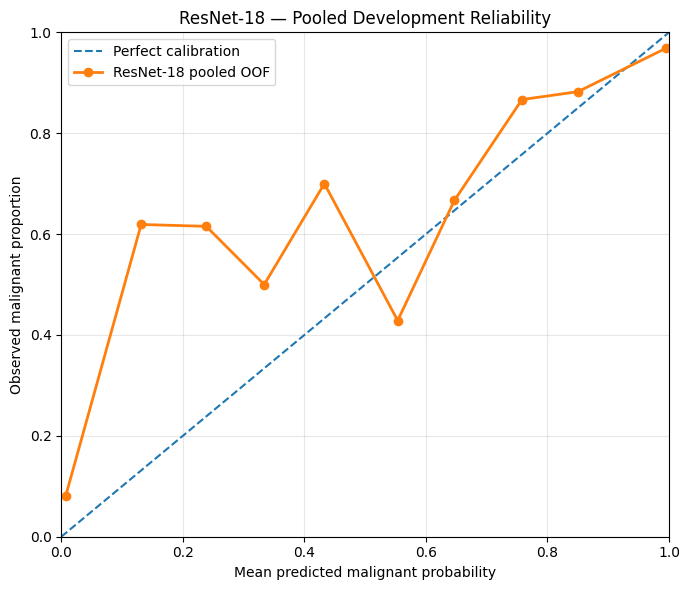

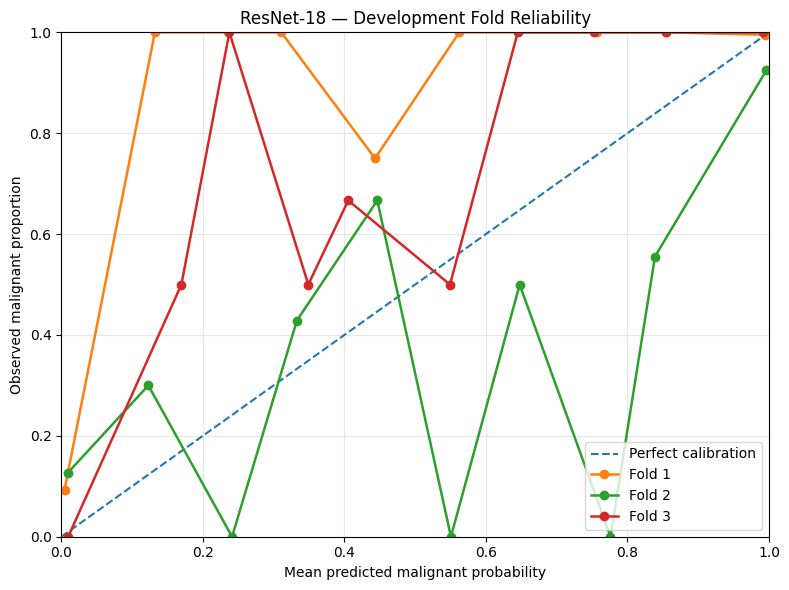


Saved:
/content/breast-histology-calibration/results/formal_development/resnet18/cross_fold_analysis/resnet18_pooled_reliability_bins.csv
/content/breast-histology-calibration/results/formal_development/resnet18/cross_fold_analysis/resnet18_fold_reliability_bins.csv
/content/breast-histology-calibration/results/formal_development/resnet18/cross_fold_analysis/resnet18_pooled_reliability.png
/content/breast-histology-calibration/results/formal_development/resnet18/cross_fold_analysis/resnet18_fold_reliability_comparison.png

PASS: Pooled reliability diagram generated.
PASS: Three-fold reliability comparison generated.
PASS: ECE reproduced from reliability bins.


In [7]:

# ============================================================
# ResNet-18 reliability diagrams
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

def make_reliability_table(df, n_bins=10):

    y = df["label"].to_numpy(dtype=int)
    p = df["probability"].to_numpy(dtype=float)

    assert len(y) > 0
    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()

    edges = np.linspace(0, 1, n_bins + 1)

    bin_ids = np.searchsorted(
        edges[1:-1],
        p,
        side="right"
    )

    rows = []

    for b in range(n_bins):

        mask = bin_ids == b
        count = int(mask.sum())

        if count > 0:
            mean_probability = float(p[mask].mean())
            observed_rate = float(y[mask].mean())
            absolute_gap = abs(
                mean_probability - observed_rate
            )
        else:
            mean_probability = np.nan
            observed_rate = np.nan
            absolute_gap = np.nan

        rows.append({
            "bin": b + 1,
            "bin_lower": float(edges[b]),
            "bin_upper": float(edges[b + 1]),
            "count": count,
            "mean_probability": mean_probability,
            "observed_malignancy_rate": observed_rate,
            "absolute_gap": absolute_gap,
            "ece_contribution": (
                count / len(df) * absolute_gap
                if count else 0.0
            )
        })

    result = pd.DataFrame(rows)

    assert result["count"].sum() == len(df)

    return result


# ------------------------------------------------------------
# 1. Compute pooled reliability table
# ------------------------------------------------------------

pooled_reliability = make_reliability_table(
    oof_df
)

assert np.isclose(
    pooled_reliability["ece_contribution"].sum(),
    pooled_metrics["ece_positive"],
    atol=1e-10
)

pooled_reliability_path = (
    analysis_dir /
    "resnet18_pooled_reliability_bins.csv"
)

pooled_reliability.to_csv(
    pooled_reliability_path,
    index=False
)

print("POOLED RELIABILITY TABLE")
display(pooled_reliability.round(6))


# ------------------------------------------------------------
# 2. Pooled reliability diagram
# ------------------------------------------------------------

valid = pooled_reliability.loc[
    pooled_reliability["count"] > 0
]

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.plot(
    valid["mean_probability"],
    valid["observed_malignancy_rate"],
    marker="o",
    linewidth=2,
    label="ResNet-18 pooled OOF"
)

ax.set(
    xlabel="Mean predicted malignant probability",
    ylabel="Observed malignant proportion",
    title="ResNet-18 — Pooled Development Reliability",
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

pooled_fig_path = (
    analysis_dir /
    "resnet18_pooled_reliability.png"
)

fig.savefig(
    pooled_fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 3. Individual fold reliability tables
# ------------------------------------------------------------

fold_reliability_tables = []

for fold in [1, 2, 3]:

    fold_df = oof_df.loc[
        oof_df["validation_fold"] == fold
    ]

    table = make_reliability_table(fold_df)
    table.insert(0, "fold", fold)

    expected_ece = float(
        fold_comparison.loc[
            fold_comparison["fold"] == fold,
            "ece_10"
        ].iloc[0]
    )

    assert np.isclose(
        table["ece_contribution"].sum(),
        expected_ece,
        atol=1e-6
    )

    fold_reliability_tables.append(table)

fold_reliability = pd.concat(
    fold_reliability_tables,
    ignore_index=True
)

fold_reliability_path = (
    analysis_dir /
    "resnet18_fold_reliability_bins.csv"
)

fold_reliability.to_csv(
    fold_reliability_path,
    index=False
)


# ------------------------------------------------------------
# 4. Compare reliability across the three folds
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

for fold in [1, 2, 3]:

    subset = fold_reliability.loc[
        (fold_reliability["fold"] == fold) &
        (fold_reliability["count"] > 0)
    ]

    ax.plot(
        subset["mean_probability"],
        subset["observed_malignancy_rate"],
        marker="o",
        linewidth=1.8,
        label=f"Fold {fold}"
    )

ax.set(
    xlabel="Mean predicted malignant probability",
    ylabel="Observed malignant proportion",
    title="ResNet-18 — Development Fold Reliability",
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

fold_fig_path = (
    analysis_dir /
    "resnet18_fold_reliability_comparison.png"
)

fig.savefig(
    fold_fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 5. Verify outputs
# ------------------------------------------------------------

for path in [
    pooled_reliability_path,
    fold_reliability_path,
    pooled_fig_path,
    fold_fig_path
]:
    assert path.is_file(), f"Missing output: {path}"

print("\nSaved:")
print(pooled_reliability_path)
print(fold_reliability_path)
print(pooled_fig_path)
print(fold_fig_path)

print("\nPASS: Pooled reliability diagram generated.")
print("PASS: Three-fold reliability comparison generated.")
print("PASS: ECE reproduced from reliability bins.")



## 4.6 — Adaptive Expected Calibration Error

### Objective

Evaluate calibration using equal-frequency probability bins as a sensitivity analysis.

The primary ECE calculation uses 10 equal-width bins. However, the observed numbers of images differ substantially across these bins.

Adaptive ECE uses 10 approximately equal-sized groups of predicted probabilities.

### Method

1. Sort images by their predicted malignant probability.
2. Divide the sorted predictions into 10 approximately equal-sized bins.
3. Calculate the mean predicted probability and observed malignant proportion within each bin.
4. Calculate the weighted absolute difference between these quantities.
5. Compare adaptive ECE against the original equal-width ECE.

### Interpretation

Adaptive ECE is a supplementary diagnostic, not a replacement for the predefined primary ECE measure.

The binning methods may produce different ECE values because they group predictions differently.

Neither method independently establishes calibration validity. Patient clustering, small samples, and predictions generated by different fold-specific CNNs must also be considered.

All calculations use Development-only out-of-fold predictions.


POOLED RESNET-18 — ADAPTIVE RELIABILITY


,bin,count,minimum_probability,maximum_probability,mean_probability,observed_malignancy_rate,absolute_gap,ece_contribution
0,1,114,0.000000,0.000014,0.000003,0.008772,0.008769,0.000882
1,2,114,0.000015,0.006012,0.001257,0.061404,0.060146,0.006052
2,3,114,0.006121,0.402746,0.101885,0.377193,0.275308,0.027701
3,4,113,0.403894,0.962234,0.808482,0.831858,0.023377,0.002331
4,5,113,0.962327,0.997989,0.988020,0.911504,0.076516,0.007631
5,6,113,0.998015,0.999777,0.999237,0.964602,0.034636,0.003454
6,7,113,0.999785,0.999978,0.999914,0.964602,0.035312,0.003522
7,8,113,0.999978,0.999999,0.999993,0.991150,0.008843,0.000882
8,9,113,0.999999,1.000000,1.000000,1.000000,0.000000,0.000000
9,10,113,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000



Equal-width ECE: 0.056472
Adaptive ECE: 0.052456

EQUAL-WIDTH VS ADAPTIVE ECE


,fold,patients,images,equal_width_ece,adaptive_ece
0,1,17,372,0.074696,0.079137
1,2,16,431,0.099174,0.077761
2,3,16,330,0.037631,0.035072
3,pooled,49,1133,0.056472,0.052456


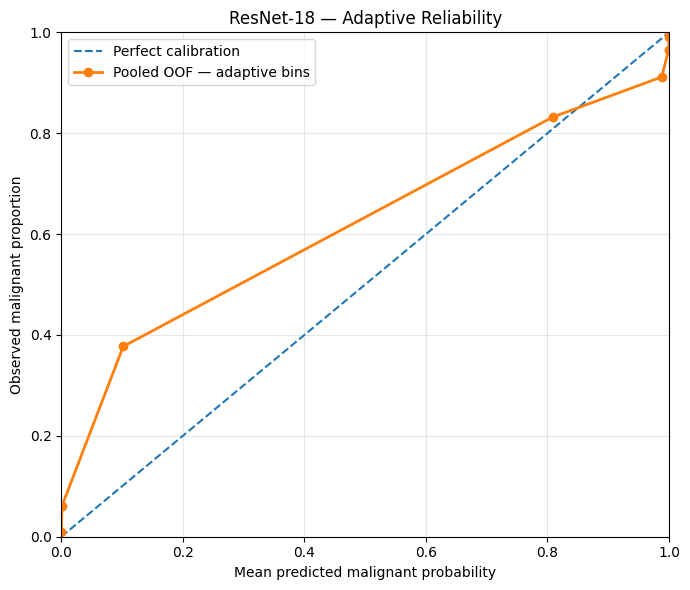


PASS: Adaptive ECE calculated.
PASS: All 1,133 Development images represented.
PASS: Adaptive reliability figure and tables saved.


In [7]:

# ============================================================
# Adaptive ECE for pooled and individual folds
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def adaptive_reliability_table(df, n_bins=10):

    y = df["label"].to_numpy(dtype=int)
    p = df["probability"].to_numpy(dtype=float)

    assert len(df) >= n_bins
    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()

    # Stable sorting makes bin assignment reproducible.
    # Equal predictions can fall in adjacent bins.
    sorted_indices = np.argsort(p, kind="stable")

    groups = np.array_split(
        sorted_indices,
        n_bins
    )

    rows = []

    for bin_number, indices in enumerate(groups, start=1):

        bin_y = y[indices]
        bin_p = p[indices]

        mean_p = float(bin_p.mean())
        observed = float(bin_y.mean())

        gap = abs(mean_p - observed)

        rows.append({
            "bin": bin_number,
            "count": len(indices),
            "minimum_probability": float(bin_p.min()),
            "maximum_probability": float(bin_p.max()),
            "mean_probability": mean_p,
            "observed_malignancy_rate": observed,
            "absolute_gap": gap,
            "ece_contribution": (
                len(indices) / len(df) * gap
            )
        })

    result = pd.DataFrame(rows)

    assert result["count"].sum() == len(df)

    return result


# ------------------------------------------------------------
# 1. Calculate pooled adaptive ECE
# ------------------------------------------------------------

pooled_adaptive = adaptive_reliability_table(
    oof_df,
    n_bins=10
)

pooled_adaptive_ece = float(
    pooled_adaptive["ece_contribution"].sum()
)

print("=" * 60)
print("POOLED RESNET-18 — ADAPTIVE RELIABILITY")
print("=" * 60)

display(pooled_adaptive.round(6))

print(
    "\nEqual-width ECE:",
    round(pooled_metrics["ece_positive"], 6)
)

print(
    "Adaptive ECE:",
    round(pooled_adaptive_ece, 6)
)


# ------------------------------------------------------------
# 2. Calculate adaptive ECE for each fold
# ------------------------------------------------------------

adaptive_rows = []

for fold in [1, 2, 3]:

    fold_df = oof_df.loc[
        oof_df["validation_fold"] == fold
    ]

    table = adaptive_reliability_table(fold_df)

    adaptive_rows.append({
        "fold": fold,
        "patients": fold_df["patient_id"].nunique(),
        "images": len(fold_df),
        "equal_width_ece": float(
            fold_comparison.loc[
                fold_comparison["fold"] == fold,
                "ece_10"
            ].iloc[0]
        ),
        "adaptive_ece": float(
            table["ece_contribution"].sum()
        )
    })

adaptive_summary = pd.DataFrame(adaptive_rows)

adaptive_summary = pd.concat(
    [
        adaptive_summary,
        pd.DataFrame([{
            "fold": "pooled",
            "patients": 49,
            "images": 1133,
            "equal_width_ece": float(
                pooled_metrics["ece_positive"]
            ),
            "adaptive_ece": pooled_adaptive_ece
        }])
    ],
    ignore_index=True
)

print("\n" + "=" * 60)
print("EQUAL-WIDTH VS ADAPTIVE ECE")
print("=" * 60)

display(adaptive_summary.round(6))


# ------------------------------------------------------------
# 3. Save analysis
# ------------------------------------------------------------

adaptive_bins_path = (
    analysis_dir /
    "resnet18_pooled_adaptive_reliability_bins.csv"
)

adaptive_summary_path = (
    analysis_dir /
    "resnet18_adaptive_ece_summary.csv"
)

pooled_adaptive.to_csv(
    adaptive_bins_path,
    index=False
)

adaptive_summary.to_csv(
    adaptive_summary_path,
    index=False
)


# ------------------------------------------------------------
# 4. Plot adaptive reliability diagram
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.plot(
    pooled_adaptive["mean_probability"],
    pooled_adaptive["observed_malignancy_rate"],
    marker="o",
    linewidth=2,
    label="Pooled OOF — adaptive bins"
)

ax.set(
    xlabel="Mean predicted malignant probability",
    ylabel="Observed malignant proportion",
    title="ResNet-18 — Adaptive Reliability",
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

adaptive_fig_path = (
    analysis_dir /
    "resnet18_pooled_adaptive_reliability.png"
)

fig.savefig(
    adaptive_fig_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 5. Verify
# ------------------------------------------------------------

assert len(pooled_adaptive) == 10
assert pooled_adaptive["count"].sum() == 1133

assert (
    pooled_adaptive["count"].max()
    - pooled_adaptive["count"].min()
) <= 1

assert adaptive_summary["adaptive_ece"].between(
    0, 1
).all()

for path in [
    adaptive_bins_path,
    adaptive_summary_path,
    adaptive_fig_path
]:
    assert path.is_file()

print("\nPASS: Adaptive ECE calculated.")
print("PASS: All 1,133 Development images represented.")
print("PASS: Adaptive reliability figure and tables saved.")



## 4.7 — Calibration Intercept and Slope

### Objective

Assess systematic bias and the extremity of predicted malignancy probabilities using logistic calibration diagnostics.

### Interpretation

**Calibration-in-the-large intercept**

This is estimated while fixing the calibration slope at 1.

- Ideal value: 0
- Positive: the model tends to underestimate malignancy risk overall
- Negative: the model tends to overestimate malignancy risk overall

**Calibration slope**

This is estimated by regressing the observed binary outcomes on the logit of the predicted probability.

- Ideal value: 1
- Less than 1: predictions may be too extreme
- Greater than 1: predictions may not be extreme enough

A separate intercept is also estimated in the freely fitted logistic calibration model.

### Numerical Considerations

Probabilities are clipped to [1e-7, 1 - 1e-7] before applying the logit transformation.

We will count extreme predictions and repeat the calculations using a second clipping threshold as a sensitivity check.

### Research Boundaries

These are descriptive calibration diagnostics computed from Development out-of-fold predictions.

The fitted diagnostic regression is not the final Platt-scaling calibrator.

Final temperature scaling and Platt scaling will be fitted only using the designated BreakHis Calibration partition, after the final CNN is frozen.


In [8]:

# ============================================================
# Calibration slope and intercept diagnostics
# ============================================================

import numpy as np
import pandas as pd

from scipy.optimize import minimize, minimize_scalar
from scipy.special import expit

from IPython.display import display


def calculate_calibration_diagnostics(
    df,
    eps=1e-7
):
    y = df["label"].to_numpy(dtype=float)
    raw_p = df["probability"].to_numpy(dtype=float)

    assert len(y) > 0
    assert set(np.unique(y)) == {0.0, 1.0}
    assert np.isfinite(raw_p).all()
    assert ((raw_p >= 0) & (raw_p <= 1)).all()

    # Record how often the original probabilities
    # are exactly at the numerical boundaries.
    exact_zero = int((raw_p == 0).sum())
    exact_one = int((raw_p == 1).sum())

    near_zero = int((raw_p < 0.01).sum())
    near_one = int((raw_p > 0.99).sum())

    # Stable logit calculation
    p = np.clip(raw_p, eps, 1.0 - eps)
    logit_p = np.log(p) - np.log1p(-p)

    # --------------------------------------------------------
    # 1. Calibration-in-the-large
    # Fix slope = 1 and estimate intercept
    # --------------------------------------------------------

    def intercept_only_loss(intercept):
        z = intercept + logit_p
        return float(
            np.mean(np.logaddexp(0, z) - y * z)
        )

    citl_fit = minimize_scalar(
        intercept_only_loss,
        bounds=(-20, 20),
        method="bounded",
        options={"xatol": 1e-10}
    )

    assert citl_fit.success

    # --------------------------------------------------------
    # 2. Freely fitted intercept and slope
    # --------------------------------------------------------

    X = np.column_stack([
        np.ones(len(logit_p)),
        logit_p
    ])

    def loss_and_gradient(parameters):

        z = X @ parameters

        loss = np.mean(
            np.logaddexp(0, z) - y * z
        )

        gradient = (
            X.T @ (expit(z) - y)
        ) / len(y)

        return float(loss), gradient

    fit = minimize(
        loss_and_gradient,
        x0=np.array([0.0, 1.0]),
        method="L-BFGS-B",
        jac=True,
        options={
            "maxiter": 2000,
            "ftol": 1e-12
        }
    )

    assert fit.success, fit.message

    free_intercept, slope = fit.x

    return {
        "images": len(df),
        "patients": df["patient_id"].nunique(),
        "calibration_in_large_intercept": float(citl_fit.x),
        "free_calibration_intercept": float(free_intercept),
        "calibration_slope": float(slope),
        "exact_zero_probabilities": exact_zero,
        "exact_one_probabilities": exact_one,
        "probabilities_below_0_01": near_zero,
        "probabilities_above_0_99": near_one,
        "clipping_epsilon": eps
    }


# ------------------------------------------------------------
# 1. Pooled and per-fold calculations
# ------------------------------------------------------------

diagnostic_rows = []

for name, df in [
    ("fold_1", oof_df[oof_df["validation_fold"] == 1]),
    ("fold_2", oof_df[oof_df["validation_fold"] == 2]),
    ("fold_3", oof_df[oof_df["validation_fold"] == 3]),
    ("pooled", oof_df)
]:

    result = calculate_calibration_diagnostics(
        df,
        eps=1e-7
    )

    result["dataset"] = name
    diagnostic_rows.append(result)

calibration_diagnostics = pd.DataFrame(
    diagnostic_rows
)

print("=" * 65)
print("RESNET-18 — CALIBRATION INTERCEPT AND SLOPE")
print("=" * 65)

display(
    calibration_diagnostics[
        [
            "dataset",
            "images",
            "patients",
            "calibration_in_large_intercept",
            "free_calibration_intercept",
            "calibration_slope"
        ]
    ].round(6)
)

print("\nEXTREME PROBABILITY COUNTS")

display(
    calibration_diagnostics[
        [
            "dataset",
            "exact_zero_probabilities",
            "exact_one_probabilities",
            "probabilities_below_0_01",
            "probabilities_above_0_99"
        ]
    ]
)


# ------------------------------------------------------------
# 2. Clipping sensitivity analysis
# ------------------------------------------------------------

pooled_eps_1e6 = calculate_calibration_diagnostics(
    oof_df,
    eps=1e-6
)

pooled_eps_1e7 = calculate_calibration_diagnostics(
    oof_df,
    eps=1e-7
)

sensitivity = pd.DataFrame([
    {
        "epsilon": 1e-6,
        **pooled_eps_1e6
    },
    {
        "epsilon": 1e-7,
        **pooled_eps_1e7
    }
])

print("\nCLIPPING SENSITIVITY — POOLED OOF")

display(
    sensitivity[
        [
            "epsilon",
            "calibration_in_large_intercept",
            "free_calibration_intercept",
            "calibration_slope"
        ]
    ]
)


# ------------------------------------------------------------
# 3. Save reproducible outputs
# ------------------------------------------------------------

diagnostics_path = (
    analysis_dir /
    "resnet18_calibration_slope_intercept.csv"
)

sensitivity_path = (
    analysis_dir /
    "resnet18_calibration_clipping_sensitivity.csv"
)

calibration_diagnostics.to_csv(
    diagnostics_path,
    index=False
)

sensitivity.to_csv(
    sensitivity_path,
    index=False
)

# ------------------------------------------------------------
# 4. Verify
# ------------------------------------------------------------

assert len(calibration_diagnostics) == 4

assert (
    calibration_diagnostics.loc[
        calibration_diagnostics["dataset"] == "pooled",
        "images"
    ].iloc[0] == 1133
)

assert np.isfinite(
    calibration_diagnostics[
        [
            "calibration_in_large_intercept",
            "free_calibration_intercept",
            "calibration_slope"
        ]
    ].to_numpy()
).all()

assert diagnostics_path.is_file()
assert sensitivity_path.is_file()

print("\nPASS: Calibration intercept and slope calculated.")
print("PASS: Extreme probabilities audited.")
print("PASS: Numerical clipping sensitivity saved.")


RESNET-18 — CALIBRATION INTERCEPT AND SLOPE


,dataset,images,patients,calibration_in_large_intercept,free_calibration_intercept,calibration_slope
0,fold_1,372,17,4.246862,2.682547,0.627462
1,fold_2,431,16,-1.565791,-0.382090,0.273730
2,fold_3,330,16,1.423114,2.338993,1.724079
3,pooled,1133,49,0.992163,0.581665,0.398363



EXTREME PROBABILITY COUNTS


,dataset,exact_zero_probabilities,exact_one_probabilities,probabilities_below_0_01,probabilities_above_0_99
0,fold_1,0,0,115,181
1,fold_2,0,0,76,272
2,fold_3,0,0,50,181
3,pooled,0,0,241,634



CLIPPING SENSITIVITY — POOLED OOF


,epsilon,calibration_in_large_intercept,free_calibration_intercept,calibration_slope
0,1.000000e-06,0.992161,0.583824,0.402264
1,1.000000e-07,0.992163,0.581665,0.398363



PASS: Calibration intercept and slope calculated.
PASS: Extreme probabilities audited.
PASS: Numerical clipping sensitivity saved.



## 4.8 — Brier Score Decomposition

### Objective

Examine the components contributing to probability prediction error in the formal ResNet-18 Development predictions.

### Method

We use the same 10 equal-width probability bins as the primary ECE analysis.

For each bin, we calculate the mean predicted malignancy probability, observed malignancy proportion, and within-bin variation.

The decomposition contains:

- **Reliability:** Squared differences between bin-average predictions and observed malignant proportions.
- **Resolution:** Variation in observed malignant proportions across bins relative to overall prevalence.
- **Uncertainty:** Baseline outcome variation determined by malignant prevalence.
- **Within-bin correction:** The difference between the original Brier score and the three-component grouped approximation.

The grouped decomposition is:

Brier (grouped) = Reliability - Resolution + Uncertainty

For the original, ungrouped predictions:

Brier (original) = Reliability - Resolution + Uncertainty + Within-bin correction

### Interpretation

Lower reliability error is desirable, whereas higher resolution is desirable.

The uncertainty component depends on class prevalence and is not directly a measure of model quality.

The within-bin correction is retained because the individual probabilities within each bin are not identical.

### Evaluation Scope

All calculations use Development-only out-of-fold predictions. Calibration and Test partitions remain untouched.

This decomposition is descriptive and does not establish how the final model will perform under distribution shift.


In [9]:

# ============================================================
# Cell 58 — Brier score decomposition
# Development-only OOF predictions
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss
from IPython.display import display


def decompose_brier(df, n_bins=10):

    y = df["label"].to_numpy(dtype=float)
    p = df["probability"].to_numpy(dtype=float)

    assert len(y) > 0
    assert set(np.unique(y)) == {0.0, 1.0}
    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()

    n = len(y)
    prevalence = float(y.mean())

    # Same equal-width bin assignment used for ECE
    edges = np.linspace(0.0, 1.0, n_bins + 1)

    bin_ids = np.searchsorted(
        edges[1:-1],
        p,
        side="right"
    )

    reliability = 0.0
    resolution = 0.0
    within_bin_correction = 0.0

    bin_rows = []

    for b in range(n_bins):

        mask = bin_ids == b
        count = int(mask.sum())

        if count == 0:
            bin_rows.append({
                "bin": b + 1,
                "count": 0,
                "mean_probability": np.nan,
                "observed_malignancy_rate": np.nan,
                "reliability_contribution": 0.0,
                "resolution_contribution": 0.0,
                "within_bin_correction": 0.0
            })
            continue

        bin_p = p[mask]
        bin_y = y[mask]

        weight = count / n

        mean_p = float(bin_p.mean())
        observed = float(bin_y.mean())

        # Binned Murphy decomposition components
        rel = weight * (mean_p - observed) ** 2

        res = weight * (
            observed - prevalence
        ) ** 2

        # Exact correction for variation within bins
        var_p = float(
            np.mean((bin_p - mean_p) ** 2)
        )

        cov_py = float(
            np.mean(
                (bin_p - mean_p) *
                (bin_y - observed)
            )
        )

        correction = weight * (
            var_p - 2.0 * cov_py
        )

        reliability += rel
        resolution += res
        within_bin_correction += correction

        bin_rows.append({
            "bin": b + 1,
            "count": count,
            "mean_probability": mean_p,
            "observed_malignancy_rate": observed,
            "reliability_contribution": rel,
            "resolution_contribution": res,
            "within_bin_correction": correction
        })

    uncertainty = prevalence * (
        1.0 - prevalence
    )

    grouped_brier = (
        reliability - resolution + uncertainty
    )

    reconstructed_brier = (
        grouped_brier + within_bin_correction
    )

    original_brier = float(
        brier_score_loss(y, p)
    )

    assert np.isclose(
        original_brier,
        reconstructed_brier,
        rtol=0,
        atol=1e-10
    ), "Brier decomposition did not reconcile."

    summary = {
        "images": n,
        "patients": df["patient_id"].nunique(),
        "malignant_prevalence": prevalence,
        "reliability": reliability,
        "resolution": resolution,
        "uncertainty": uncertainty,
        "grouped_brier": grouped_brier,
        "within_bin_correction": within_bin_correction,
        "reconstructed_brier": reconstructed_brier,
        "original_brier": original_brier,
        "reconstruction_error": (
            original_brier - reconstructed_brier
        )
    }

    return summary, pd.DataFrame(bin_rows)


# ------------------------------------------------------------
# 1. Analyze each fold and pooled predictions
# ------------------------------------------------------------

datasets = {
    "fold_1": oof_df.loc[
        oof_df["validation_fold"] == 1
    ],
    "fold_2": oof_df.loc[
        oof_df["validation_fold"] == 2
    ],
    "fold_3": oof_df.loc[
        oof_df["validation_fold"] == 3
    ],
    "pooled": oof_df
}

summary_rows = []
all_bin_tables = []

for name, data in datasets.items():

    summary, bin_table = decompose_brier(
        data,
        n_bins=10
    )

    summary["dataset"] = name
    bin_table.insert(0, "dataset", name)

    summary_rows.append(summary)
    all_bin_tables.append(bin_table)

brier_decomposition = pd.DataFrame(
    summary_rows
)

brier_bins = pd.concat(
    all_bin_tables,
    ignore_index=True
)

# ------------------------------------------------------------
# 2. Verify against saved fold metrics
# ------------------------------------------------------------

for fold in [1, 2, 3]:

    expected = float(
        fold_comparison.loc[
            fold_comparison["fold"] == fold,
            "brier"
        ].iloc[0]
    )

    observed = float(
        brier_decomposition.loc[
            brier_decomposition["dataset"] == f"fold_{fold}",
            "original_brier"
        ].iloc[0]
    )

    assert np.isclose(
        observed, expected, atol=1e-6
    )

pooled_brier = float(
    brier_decomposition.loc[
        brier_decomposition["dataset"] == "pooled",
        "original_brier"
    ].iloc[0]
)

assert np.isclose(
    pooled_brier,
    pooled_metrics["brier"],
    atol=1e-10
)

# ------------------------------------------------------------
# 3. Display results
# ------------------------------------------------------------

print("=" * 70)
print("RESNET-18 — BRIER SCORE DECOMPOSITION")
print("=" * 70)

display(
    brier_decomposition[
        [
            "dataset",
            "malignant_prevalence",
            "reliability",
            "resolution",
            "uncertainty",
            "within_bin_correction",
            "original_brier",
            "reconstruction_error"
        ]
    ].round(6)
)

print("\nPOOLED BRIER — BIN-LEVEL CONTRIBUTIONS")

display(
    brier_bins.loc[
        brier_bins["dataset"] == "pooled"
    ].round(6)
)

# ------------------------------------------------------------
# 4. Save reproducible outputs
# ------------------------------------------------------------

decomposition_path = (
    analysis_dir /
    "resnet18_brier_decomposition.csv"
)

bins_path = (
    analysis_dir /
    "resnet18_brier_decomposition_bins.csv"
)

brier_decomposition.to_csv(
    decomposition_path,
    index=False
)

brier_bins.to_csv(
    bins_path,
    index=False
)

# ------------------------------------------------------------
# 5. Final verification
# ------------------------------------------------------------

assert len(brier_decomposition) == 4

assert np.allclose(
    brier_decomposition["reconstruction_error"],
    0.0,
    atol=1e-10
)

assert decomposition_path.is_file()
assert bins_path.is_file()

print("\nPASS: Brier decomposition completed.")
print("PASS: Original Brier scores reproduced.")
print("PASS: Decomposition reconciles with original scores.")
print("PASS: Results saved.")


RESNET-18 — BRIER SCORE DECOMPOSITION


,dataset,malignant_prevalence,reliability,resolution,uncertainty,within_bin_correction,original_brier,reconstruction_error
0,fold_1,0.680108,0.030698,0.183613,0.217561,-0.001439,0.063208,-0.0
1,fold_2,0.691415,0.015181,0.123951,0.213360,-0.001457,0.103134,0.0
2,fold_3,0.766667,0.013085,0.172323,0.178889,0.000002,0.019652,-0.0
3,pooled,0.709620,0.009054,0.148455,0.206059,-0.000948,0.065710,0.0



POOLED BRIER — BIN-LEVEL CONTRIBUTIONS


,dataset,bin,count,mean_probability,observed_malignancy_rate,reliability_contribution,resolution_contribution,within_bin_correction
30,pooled,1,297,0.007261,0.080808,0.001418,0.103650,-0.000617
31,pooled,2,21,0.131413,0.619048,0.004407,0.000152,-0.000017
32,pooled,3,13,0.238501,0.615385,0.001630,0.000102,0.000035
33,pooled,4,10,0.333913,0.500000,0.000243,0.000388,-0.000002
34,pooled,5,10,0.432921,0.700000,0.000630,0.000001,0.000037
35,pooled,6,7,0.553570,0.428571,0.000097,0.000488,-0.000022
36,pooled,7,6,0.646821,0.666667,0.000002,0.000010,-0.000019
37,pooled,8,15,0.758063,0.866667,0.000156,0.000327,0.000074
38,pooled,9,34,0.850154,0.882353,0.000031,0.000895,-0.000148
39,pooled,10,720,0.994374,0.968056,0.000440,0.042443,-0.000271



PASS: Brier decomposition completed.
PASS: Original Brier scores reproduced.
PASS: Decomposition reconciles with original scores.
PASS: Results saved.



## 4.9 — Interpretation of Brier Score Decomposition

### Results

The Brier decomposition reconciled exactly with the original probability prediction errors for all three Development folds and the pooled out-of-fold dataset.

| Dataset | Reliability | Resolution | Original Brier |
|---|---:|---:|---:|
| Fold 1 | 0.030698 | 0.183613 | 0.063208 |
| Fold 2 | 0.015181 | 0.123951 | 0.103134 |
| Fold 3 | 0.013085 | 0.172323 | 0.019652 |
| Pooled | 0.009054 | 0.148455 | 0.065710 |

### Interpretation

Fold 2 had the highest Brier score but a lower binned reliability component than Fold 1. Its substantially lower resolution component contributed to the difference in overall probability prediction error.

This demonstrates that the Brier score should not be interpreted as a calibration-only measure. It reflects both the quality of predicted probabilities and their ability to distinguish groups with different outcome frequencies.

The pooled reliability component was smaller than the individual-fold components. However, pooling predictions from independently trained CNNs can conceal calibration errors that differ across folds.

These findings complement the ECE results, reliability diagrams, and calibration slope analysis.

### Limitations

The decomposition uses 10 equal-width probability bins. A within-bin correction was included to reconcile the grouped components with the original Brier scores.

The components depend on the binning procedure, and several intermediate probability bins contain few images.

All results are descriptive Development-validation findings. They do not establish final Test calibration or external transportability.



## 4.10 — Mean-Logit Versus Mean-Probability Aggregation

### Objective

Determine whether the patch-to-image aggregation procedure affects discrimination and probability reliability.

### Primary Method

For each image, average its patch logits and apply sigmoid:

P(malignant) = sigmoid(mean(patch logits))

### Alternative Method

Apply sigmoid to each patch logit before averaging:

P(malignant) = mean(sigmoid(patch logits))

### Experimental Controls

- Use the same three AUROC-selected ResNet-18 checkpoints.
- Use the same Development validation images and patches.
- Do not retrain the CNNs.
- Do not change patch coordinates or preprocessing.
- Do not use Calibration, Test, BACH, or BRACS data.

### Evaluation

Compare AUROC, AUPRC, balanced accuracy, ECE, Brier score, and NLL for each aggregation method.

Evaluate each fold individually and the combined out-of-fold predictions.

### Interpretation

This is a Development-only methodological ablation.

Differences in performance will indicate sensitivity to patch aggregation. They will not establish final Test performance.

The predefined mean-logit method remains the primary aggregation procedure; the mean-probability method is a sensitivity analysis.


In [10]:

# ============================================================
# Audit patch aggregation data availability
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

print("=" * 65)
print("RESNET-18 — AGGREGATION ABLATION PREFLIGHT")
print("=" * 65)

for fold in [1, 2, 3]:

    images = fold_results[fold]["images"]
    patches = fold_results[fold]["patches"]

    print(f"\nFOLD {fold}")
    print("-" * 45)

    print("Image prediction columns:")
    print(images.columns.tolist())

    print("\nPatch prediction columns:")
    print(patches.columns.tolist())

    print("\nImage-level example:")
    display(images.head(2))

    print("\nPatch-level example:")
    display(patches.head(2))

    assert len(images) == {
        1: 372,
        2: 431,
        3: 330
    }[fold]

    assert len(patches) == {
        1: 5861,
        2: 6810,
        3: 5224
    }[fold]

    assert images["filename"].is_unique

    assert images["probability"].between(
        0, 1
    ).all()

    print(f"\nPASS: Fold {fold} prediction files accessible.")

print("\n" + "=" * 65)
print("AGGREGATION DATA AVAILABILITY")
print("=" * 65)

for fold in [1, 2, 3]:

    images = fold_results[fold]["images"]

    print(
        f"Fold {fold}: "
        f"mean_patch_probability available = "
        f"{'mean_patch_probability' in images.columns}"
    )

print("\nPASS: Aggregation preflight completed.")


RESNET-18 — AGGREGATION ABLATION PREFLIGHT

FOLD 1
---------------------------------------------
Image prediction columns:
['filename', 'patient_id', 'label', 'image_logit', 'mean_patch_probability', 'n_patches', 'probability', 'prediction']

Patch prediction columns:
['filename', 'patient_id', 'label', 'patch_index', 'patch_logit']

Image-level example:


,filename,patient_id,label,image_logit,mean_patch_probability,n_patches,probability,prediction
0,SOB_B_A-14-29960CD-40-001.png,14-29960CD,0,-16.786621,0.000001,16,5.124637e-08,0
1,SOB_B_A-14-29960CD-40-002.png,14-29960CD,0,-13.147705,0.000361,16,1.949950e-06,0



Patch-level example:


,filename,patient_id,label,patch_index,patch_logit
0,SOB_B_TA-14-13200-40-001.png,14-13200,0,0,-25.218750
1,SOB_B_TA-14-13200-40-001.png,14-13200,0,1,-9.898438



PASS: Fold 1 prediction files accessible.

FOLD 2
---------------------------------------------
Image prediction columns:
['filename', 'patient_id', 'label', 'image_logit', 'mean_patch_probability', 'n_patches', 'probability', 'prediction']

Patch prediction columns:
['filename', 'patient_id', 'label', 'patch_index', 'patch_logit']

Image-level example:


...


PASS: Fold 2 prediction files accessible.

FOLD 3
---------------------------------------------
Image prediction columns:
['filename', 'patient_id', 'label', 'image_logit', 'mean_patch_probability', 'n_patches', 'probability', 'prediction']

Patch prediction columns:
['filename', 'patient_id', 'label', 'patch_index', 'patch_logit']

Image-level example:


,filename,patient_id,label,image_logit,mean_patch_probability,n_patches,probability,prediction
0,SOB_B_F-14-23060AB-40-001.png,14-23060AB,0,-11.677246,0.000025,16,0.000008,0
1,SOB_B_F-14-23060AB-40-002.png,14-23060AB,0,-9.753174,0.000206,16,0.000058,0



Patch-level example:


,filename,patient_id,label,patch_index,patch_logit
0,SOB_M_DC-14-10926-40-001.png,14-10926,1,0,6.074219
1,SOB_M_DC-14-10926-40-001.png,14-10926,1,1,5.824219



PASS: Fold 3 prediction files accessible.

AGGREGATION DATA AVAILABILITY
Fold 1: mean_patch_probability available = True
Fold 2: mean_patch_probability available = True
Fold 3: mean_patch_probability available = True

PASS: Aggregation preflight completed.



## 4.11 — Patch Aggregation Ablation

### Objective

Compare mean-logit aggregation and mean-probability aggregation using the same trained ResNet-18 models, validation patients, and extracted patches.

### Methods

**Primary: Mean-logit aggregation**

1. Obtain logits for each retained patch.
2. Average the patch logits within the source image.
3. Apply sigmoid to produce one image-level probability.

**Alternative: Mean-probability aggregation**

1. Apply sigmoid to each patch logit.
2. Average the resulting probabilities within the source image.

### Evaluation

For each fold and the combined out-of-fold dataset, compare:

- AUROC and AUPRC
- Balanced accuracy
- ECE (10 equal-width bins, positive-class definition)
- Brier score
- Negative log-likelihood
- Number of images whose binary predictions change

### Experimental Controls

Both methods use the same trained CNNs and the same saved patch predictions.

No additional CNN training, checkpoint selection, or calibrator fitting is performed.

The original mean-logit aggregation remains the predefined primary method. Mean-probability aggregation is evaluated as a sensitivity analysis.

All results are Development-validation diagnostics, not final Test results.


In [12]:

# ============================================================
# Mean-logit vs mean-probability aggregation
# ============================================================

import numpy as np
import pandas as pd
from scipy.special import expit
from IPython.display import display

# ------------------------------------------------------------
# 1. Reconstruct image predictions from saved patch logits
# ------------------------------------------------------------

paired_parts = []

for fold in [1, 2, 3]:

    images = fold_results[fold]["images"].copy()
    patches = fold_results[fold]["patches"].copy()

    keys = ["filename", "patient_id", "label"]

    assert not patches.duplicated(
        ["filename", "patch_index"]
    ).any()

    assert patches["patch_logit"].notna().all()

    # Calculate both aggregations directly from patch logits.
    reconstructed = (
        patches.groupby(keys, as_index=False)
        .agg(
            reconstructed_n_patches=("patch_logit", "size"),

            reconstructed_image_logit=(
                "patch_logit", "mean"
            ),

            reconstructed_mean_probability=(
                "patch_logit",
                lambda s: float(
                    expit(
                        s.to_numpy(dtype=np.float64)
                    ).mean()
                )
            )
        )
    )

    reconstructed["reconstructed_primary_probability"] = (
        expit(reconstructed["reconstructed_image_logit"])
    )

    paired = images.merge(
        reconstructed,
        on=keys,
        how="left",
        validate="one_to_one",
        indicator=True
    )

    assert (paired["_merge"] == "both").all()

    assert (
        paired["n_patches"]
        == paired["reconstructed_n_patches"]
    ).all()

    # Audit agreement with saved image-level probabilities.
    primary_difference = np.max(np.abs(
        paired["probability"]
        - paired["reconstructed_primary_probability"]
    ))

    alternative_difference = np.max(np.abs(
        paired["mean_patch_probability"]
        - paired["reconstructed_mean_probability"]
    ))

    logit_difference = np.max(np.abs(
        paired["image_logit"]
        - paired["reconstructed_image_logit"]
    ))

    print(f"\nFold {fold} reconstruction audit")
    print("Max image-logit difference:", logit_difference)
    print("Max primary-probability difference:", primary_difference)
    print("Max alternative-probability difference:",
          alternative_difference)

    # Allow small floating-point reconstruction differences.
    assert logit_difference < 1e-2
    assert primary_difference < 5e-4
    assert alternative_difference < 5e-4

    paired["validation_fold"] = fold

    paired_parts.append(
        paired[
            [
                "filename",
                "patient_id",
                "label",
                "validation_fold",
                "n_patches",
                "probability",
                "mean_patch_probability"
            ]
        ]
    )

aggregation_oof = pd.concat(
    paired_parts,
    ignore_index=True
)

aggregation_oof = aggregation_oof.rename(
    columns={
        "probability": "mean_logit_probability"
    }
)

# ------------------------------------------------------------
# 2. Verify patient-level and image-level coverage
# ------------------------------------------------------------

assert len(aggregation_oof) == 1133
assert aggregation_oof["filename"].is_unique
assert aggregation_oof["patient_id"].nunique() == 49

assert (
    aggregation_oof.groupby("patient_id")[
        "validation_fold"
    ].nunique() == 1
).all()

for column in [
    "mean_logit_probability",
    "mean_patch_probability"
]:
    assert aggregation_oof[column].between(0, 1).all()
    assert np.isfinite(
        aggregation_oof[column].to_numpy()
    ).all()

# Verify the primary predictions against the OOF file.
original_oof = oof_df[
    ["filename", "probability"]
].rename(
    columns={"probability": "original_probability"}
)

audit = aggregation_oof.merge(
    original_oof,
    on="filename",
    validate="one_to_one"
)

assert np.allclose(
    audit["mean_logit_probability"],
    audit["original_probability"],
    atol=1e-12,
    rtol=0
)

print("\nPASS: Both aggregation methods reconstructed.")
print("PASS: Primary predictions match existing OOF file.")

# ------------------------------------------------------------
# 3. Calculate paired performance metrics
# ------------------------------------------------------------

methods = {
    "mean_logit": "mean_logit_probability",
    "mean_probability": "mean_patch_probability"
}

metric_names = [
    "auroc",
    "auprc",
    "balanced_accuracy",
    "ece_10",
    "brier",
    "nll"
]

comparison_rows = []

for dataset_name, data in [
    ("fold_1", aggregation_oof[
        aggregation_oof["validation_fold"] == 1
    ]),
    ("fold_2", aggregation_oof[
        aggregation_oof["validation_fold"] == 2
    ]),
    ("fold_3", aggregation_oof[
        aggregation_oof["validation_fold"] == 3
    ]),
    ("pooled", aggregation_oof)
]:

    for method, probability_column in methods.items():

        evaluation_df = data[
            ["patient_id", "label"]
        ].copy()

        evaluation_df["probability"] = (
            data[probability_column].to_numpy()
        )

        result = calculate_oof_metrics(
            evaluation_df
        )

        comparison_rows.append({
            "dataset": dataset_name,
            "method": method,
            "images": len(data),
            "patients": data["patient_id"].nunique(),
            "auroc": result["auroc"],
            "auprc": result["auprc"],
            "balanced_accuracy": result["balanced_accuracy"],
            "ece_10": result["ece_positive"],
            "brier": result["brier"],
            "nll": result["nll_1e7"]
        })

aggregation_metrics = pd.DataFrame(comparison_rows)

print("\n" + "=" * 68)
print("RESNET-18 — AGGREGATION METHOD PERFORMANCE")
print("=" * 68)

display(aggregation_metrics.round(6))

# ------------------------------------------------------------
# 4. Confirm original method reproduces saved metrics
# ------------------------------------------------------------

for fold in [1, 2, 3]:

    actual = aggregation_metrics.loc[
        (aggregation_metrics["dataset"] == f"fold_{fold}") &
        (aggregation_metrics["method"] == "mean_logit")
    ].iloc[0]

    expected = fold_comparison.loc[
        fold_comparison["fold"] == fold
    ].iloc[0]

    for metric in metric_names:

        assert np.isclose(
            actual[metric],
            expected[metric],
            atol=1e-6
        ), f"Fold {fold}: {metric} mismatch"

pooled_primary = aggregation_metrics.loc[
    (aggregation_metrics["dataset"] == "pooled") &
    (aggregation_metrics["method"] == "mean_logit")
].iloc[0]

for metric in metric_names:

    expected_key = (
        "ece_positive" if metric == "ece_10"
        else "nll_1e7" if metric == "nll"
        else metric
    )

    assert np.isclose(
        pooled_primary[metric],
        pooled_metrics[expected_key],
        atol=1e-6
    )

print("\nPASS: Original mean-logit metrics reproduced.")

# ------------------------------------------------------------
# 5. Calculate paired metric differences
# ------------------------------------------------------------

primary = (
    aggregation_metrics[
        aggregation_metrics["method"] == "mean_logit"
    ]
    .set_index("dataset")
)

alternative = (
    aggregation_metrics[
        aggregation_metrics["method"] == "mean_probability"
    ]
    .set_index("dataset")
)

difference_rows = []

for dataset_name in [
    "fold_1", "fold_2", "fold_3", "pooled"
]:

    row = {"dataset": dataset_name}

    for metric in metric_names:

        original_value = float(
            primary.loc[dataset_name, metric]
        )

        alternative_value = float(
            alternative.loc[dataset_name, metric]
        )

        row[f"{metric}_mean_logit"] = original_value
        row[f"{metric}_mean_probability"] = alternative_value

        # Positive delta means alternative - primary.
        row[f"{metric}_delta"] = (
            alternative_value - original_value
        )

    difference_rows.append(row)

aggregation_differences = pd.DataFrame(
    difference_rows
)

print("\n" + "=" * 68)
print("PAIRED METRIC DIFFERENCES: ALTERNATIVE MINUS PRIMARY")
print("=" * 68)

display(
    aggregation_differences[
        ["dataset"] +
        [f"{m}_delta" for m in metric_names]
    ].round(6)
)

# ------------------------------------------------------------
# 6. Count changed binary predictions
# ------------------------------------------------------------

aggregation_oof["primary_prediction"] = (
    aggregation_oof["mean_logit_probability"] >= 0.5
).astype(int)

aggregation_oof["alternative_prediction"] = (
    aggregation_oof["mean_patch_probability"] >= 0.5
).astype(int)

aggregation_oof["prediction_changed"] = (
    aggregation_oof["primary_prediction"]
    != aggregation_oof["alternative_prediction"]
)

aggregation_oof["probability_difference"] = (
    aggregation_oof["mean_patch_probability"]
    - aggregation_oof["mean_logit_probability"]
)

change_rows = []

for dataset_name, data in [
    ("fold_1", aggregation_oof[
        aggregation_oof["validation_fold"] == 1
    ]),
    ("fold_2", aggregation_oof[
        aggregation_oof["validation_fold"] == 2
    ]),
    ("fold_3", aggregation_oof[
        aggregation_oof["validation_fold"] == 3
    ]),
    ("pooled", aggregation_oof)
]:

    change_rows.append({
        "dataset": dataset_name,
        "images": len(data),
        "changed_predictions": int(
            data["prediction_changed"].sum()
        ),
        "changed_percent": float(
            100 * data["prediction_changed"].mean()
        ),
        "mean_absolute_probability_difference": float(
            data["probability_difference"].abs().mean()
        )
    })

aggregation_changes = pd.DataFrame(change_rows)

print("\nBINARY PREDICTION AND PROBABILITY CHANGES")

display(aggregation_changes.round(6))

# ------------------------------------------------------------
# 7. Save outputs
# ------------------------------------------------------------

aggregation_oof_path = (
    analysis_dir /
    "resnet18_aggregation_paired_predictions.csv"
)

aggregation_metrics_path = (
    analysis_dir /
    "resnet18_aggregation_metrics.csv"
)

aggregation_differences_path = (
    analysis_dir /
    "resnet18_aggregation_metric_differences.csv"
)

aggregation_changes_path = (
    analysis_dir /
    "resnet18_aggregation_prediction_changes.csv"
)

aggregation_oof.to_csv(
    aggregation_oof_path,
    index=False
)

aggregation_metrics.to_csv(
    aggregation_metrics_path,
    index=False
)

aggregation_differences.to_csv(
    aggregation_differences_path,
    index=False
)

aggregation_changes.to_csv(
    aggregation_changes_path,
    index=False
)

for path in [
    aggregation_oof_path,
    aggregation_metrics_path,
    aggregation_differences_path,
    aggregation_changes_path
]:
    assert path.is_file(), f"Missing output: {path}"

print("\nPASS: Aggregation comparison completed.")
print("PASS: All original metrics reproduced.")
print("PASS: All 1,133 images evaluated using both methods.")
print("PASS: Results saved.")



Fold 1 reconstruction audit
Max image-logit difference: 1.7763568394002505e-15
Max primary-probability difference: 1.1102230246251565e-16
Max alternative-probability difference: 2.220446049250313e-16

Fold 2 reconstruction audit
Max image-logit difference: 1.7763568394002505e-15
Max primary-probability difference: 1.1102230246251565e-16
Max alternative-probability difference: 2.220446049250313e-16

Fold 3 reconstruction audit
Max image-logit difference: 8.881784197001252e-16
Max primary-probability difference: 1.1102230246251565e-16
Max alternative-probability difference: 2.220446049250313e-16

PASS: Both aggregation methods reconstructed.
PASS: Primary predictions match existing OOF file.

RESNET-18 — AGGREGATION METHOD PERFORMANCE


,dataset,method,images,patients,auroc,auprc,balanced_accuracy,ece_10,brier,nll
0,fold_1,mean_logit,372,17,0.992493,0.996657,0.940462,0.074696,0.063208,0.256791
1,fold_1,mean_probability,372,17,0.990966,0.995902,0.940462,0.080340,0.056368,0.192708
2,fold_2,mean_logit,431,16,0.956628,0.982234,0.842383,0.099174,0.103134,0.532513
3,fold_2,mean_probability,431,16,0.953323,0.980856,0.844061,0.068913,0.091585,0.344668
4,fold_3,mean_logit,330,16,0.998768,0.999624,0.975720,0.037631,0.019652,0.065168
5,fold_3,mean_probability,330,16,0.998922,0.999671,0.975720,0.048591,0.020409,0.075168
6,pooled,mean_logit,1133,49,0.967696,0.985327,0.911361,0.056472,0.065710,0.305865
7,pooled,mean_probability,1133,49,0.971000,0.987063,0.911983,0.032679,0.059291,0.216279



PASS: Original mean-logit metrics reproduced.

PAIRED METRIC DIFFERENCES: ALTERNATIVE MINUS PRIMARY


,dataset,auroc_delta,auprc_delta,balanced_accuracy_delta,ece_10_delta,brier_delta,nll_delta
0,fold_1,-0.001528,-0.000755,0.000000,0.005644,-0.006840,-0.064084
1,fold_2,-0.003305,-0.001378,0.001678,-0.030260,-0.011549,-0.187845
2,fold_3,0.000154,0.000047,0.000000,0.010960,0.000756,0.010000
3,pooled,0.003304,0.001736,0.000622,-0.023793,-0.006419,-0.089585



BINARY PREDICTION AND PROBABILITY CHANGES


,dataset,images,changed_predictions,changed_percent,mean_absolute_probability_difference
0,fold_1,372,0,0.000000,0.036115
1,fold_2,431,3,0.696056,0.048205
2,fold_3,330,0,0.000000,0.015031
3,pooled,1133,3,0.264784,0.034573



PASS: Aggregation comparison completed.
PASS: All original metrics reproduced.
PASS: All 1,133 images evaluated using both methods.
PASS: Results saved.



## 4.12 — Interpretation of the Aggregation Ablation

### Results

Both aggregation methods were reconstructed directly from saved patch logits. Reconstruction differences were at floating-point precision, confirming agreement with the original saved predictions.

| Metric | Mean-logit | Mean-probability |
|---|---:|---:|
| Pooled AUROC | 0.967696 | 0.971000 |
| Pooled AUPRC | 0.985327 | 0.987063 |
| Balanced accuracy | 0.911361 | 0.911983 |
| ECE | 0.056472 | 0.032679 |
| Brier score | 0.065710 | 0.059291 |
| NLL | 0.305865 | 0.216279 |

Only 3 of 1,133 images (0.265%) changed their binary classification between the methods.

### Interpretation

Mean-probability aggregation produced numerically better pooled results across all six metrics.

However, the individual fold comparisons were mixed. The alternative reduced AUROC in Folds 1 and 2 but slightly improved AUROC in Fold 3. Its ECE improved in Fold 2 while worsening in Folds 1 and 3.

These results suggest that patch aggregation affects probability reliability, even when most binary classification decisions remain unchanged.

The pooled improvements must be interpreted cautiously because predictions originate from independently trained fold-specific CNNs.

### Methodological Decision

Mean-logit aggregation remains the predefined primary method.

Mean-probability aggregation will be reported as a Development-only sensitivity analysis.

No architecture, checkpoint, training configuration, or held-out evaluation procedure was changed in response to these findings.

### Next Step

Estimate uncertainty for both aggregation methods and their paired differences using patient-level cluster bootstrap resampling.



## 4.13 — Patient-Level Bootstrap Confidence Intervals

### Objective

Estimate sampling uncertainty in ResNet-18 Development out-of-fold performance and the paired differences between patch-aggregation methods.

### Method

Use 1,000 patient-level cluster bootstrap replicates.

For each replicate:

1. Sample patients with replacement within each frozen Development validation fold.
2. Preserve the original number of sampled patient clusters per fold (17, 16, and 16).
3. Include all source images belonging to each sampled patient.
4. Calculate discrimination and probability-quality metrics for both aggregation methods.
5. Calculate the paired metric difference: mean-probability minus mean-logit.

The two methods use identical sampled patients within each replicate.

### Metrics

- AUROC
- AUPRC
- Balanced accuracy
- ECE (10 equal-width bins)
- Brier score
- Negative log-likelihood

Use percentile-based 95% bootstrap intervals.

### Interpretation

The bootstrap accounts for clustering of images within patients while conditioning on the already trained, AUROC-selected fold-specific models.

It does not account for uncertainty from retraining CNNs, selection of checkpoints on Development validation data, or changes between hospitals.

The intervals therefore describe uncertainty in the current Development analysis and should not be interpreted as independent final Test confidence intervals.

The mean-logit method remains the primary analysis regardless of the results.


In [13]:

# ============================================================
# Patient-cluster bootstrap for aggregation methods
# ============================================================

import numpy as np
import pandas as pd
import json

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss
)

from IPython.display import display

BOOTSTRAP_REPLICATES = 1000
BOOTSTRAP_SEED = 631

metric_names = [
    "auroc",
    "auprc",
    "balanced_accuracy",
    "ece_10",
    "brier",
    "nll"
]

data = aggregation_oof.reset_index(drop=True).copy()

assert len(data) == 1133
assert data["patient_id"].nunique() == 49

assert (
    data.groupby("patient_id")[
        "validation_fold"
    ].nunique() == 1
).all()

# ------------------------------------------------------------
# 1. Prepare arrays
# ------------------------------------------------------------

y_all = data["label"].to_numpy(dtype=int)

p_primary = data[
    "mean_logit_probability"
].to_numpy(dtype=float)

p_alternative = data[
    "mean_patch_probability"
].to_numpy(dtype=float)

assert set(np.unique(y_all)) == {0, 1}

assert np.isfinite(p_primary).all()
assert np.isfinite(p_alternative).all()


# ------------------------------------------------------------
# 2. Build patient clusters within each validation fold
# ------------------------------------------------------------

fold_clusters = {}

for fold in [1, 2, 3]:

    subset = data.loc[
        data["validation_fold"] == fold
    ]

    patient_ids = sorted(
        subset["patient_id"].unique()
    )

    fold_clusters[fold] = [
        subset.index[
            subset["patient_id"] == patient_id
        ].to_numpy(dtype=int)

        for patient_id in patient_ids
    ]

assert len(fold_clusters[1]) == 17
assert len(fold_clusters[2]) == 16
assert len(fold_clusters[3]) == 16

assert sum(
    len(clusters)
    for clusters in fold_clusters.values()
) == 49


# ------------------------------------------------------------
# 3. Define the fixed metric calculations
# ------------------------------------------------------------

def bootstrap_metrics(y, probabilities):

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    return {
        "auroc": float(
            roc_auc_score(y, probabilities)
        ),
        "auprc": float(
            average_precision_score(y, probabilities)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y, predictions)
        ),
        "ece_10": float(
            compute_ece(
                y,
                probabilities,
                n_bins=10,
                mode="positive"
            )
        ),
        "brier": float(
            brier_score_loss(y, probabilities)
        ),
        "nll": float(
            compute_nll(
                y,
                probabilities,
                eps=1e-7
            )
        )
    }


# ------------------------------------------------------------
# 4. Calculate original point estimates
# ------------------------------------------------------------

point_primary = bootstrap_metrics(
    y_all, p_primary
)

point_alternative = bootstrap_metrics(
    y_all, p_alternative
)

# Verify against completed aggregation analysis
for method_name, point in [
    ("mean_logit", point_primary),
    ("mean_probability", point_alternative)
]:

    reference = aggregation_metrics.loc[
        (aggregation_metrics["dataset"] == "pooled") &
        (aggregation_metrics["method"] == method_name)
    ].iloc[0]

    for metric in metric_names:

        assert np.isclose(
            point[metric],
            reference[metric],
            atol=1e-6
        ), (
            f"{method_name}: {metric} "
            "does not reproduce saved results"
        )

print("PASS: Bootstrap metric definitions verified.")


# ------------------------------------------------------------
# 5. Paired patient-cluster bootstrap
# ------------------------------------------------------------

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

bootstrap_rows = []
skipped_replicates = 0

max_attempts = BOOTSTRAP_REPLICATES + 200

for attempt in range(max_attempts):

    if len(bootstrap_rows) == BOOTSTRAP_REPLICATES:
        break

    sampled_clusters = []

    # Sample patients separately within each fold.
    for fold in [1, 2, 3]:

        clusters = fold_clusters[fold]

        chosen = rng.integers(
            low=0,
            high=len(clusters),
            size=len(clusters)
        )

        sampled_clusters.extend(
            clusters[index]
            for index in chosen
        )

    sampled_indices = np.concatenate(
        sampled_clusters
    )

    y_boot = y_all[sampled_indices]

    # AUROC requires both classes.
    if np.unique(y_boot).size < 2:
        skipped_replicates += 1
        continue

    primary = bootstrap_metrics(
        y_boot,
        p_primary[sampled_indices]
    )

    alternative = bootstrap_metrics(
        y_boot,
        p_alternative[sampled_indices]
    )

    result = {
        "replicate": len(bootstrap_rows) + 1,
        "sampled_images": len(sampled_indices)
    }

    for metric in metric_names:

        result[f"mean_logit_{metric}"] = (
            primary[metric]
        )

        result[f"mean_probability_{metric}"] = (
            alternative[metric]
        )

        result[f"delta_{metric}"] = (
            alternative[metric] - primary[metric]
        )

    bootstrap_rows.append(result)

assert len(bootstrap_rows) == BOOTSTRAP_REPLICATES, (
    "Insufficient valid bootstrap replicates."
)

bootstrap_results = pd.DataFrame(
    bootstrap_rows
)


# ------------------------------------------------------------
# 6. Construct percentile intervals
# ------------------------------------------------------------

ci_rows = []

for method in [
    "mean_logit",
    "mean_probability",
    "delta"
]:

    for metric in metric_names:

        column = f"{method}_{metric}"

        values = bootstrap_results[
            column
        ].to_numpy(dtype=float)

        if method == "mean_logit":
            point = point_primary[metric]

        elif method == "mean_probability":
            point = point_alternative[metric]

        else:
            point = (
                point_alternative[metric]
                - point_primary[metric]
            )

        lower, upper = np.quantile(
            values,
            [0.025, 0.975]
        )

        ci_rows.append({
            "method": method,
            "metric": metric,
            "point_estimate": float(point),
            "ci_lower_95": float(lower),
            "ci_upper_95": float(upper)
        })

bootstrap_ci = pd.DataFrame(
    ci_rows
)


# ------------------------------------------------------------
# 7. Display primary method intervals
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PRIMARY MEAN-LOGIT — PATIENT BOOTSTRAP 95% INTERVALS")
print("=" * 70)

display(
    bootstrap_ci.loc[
        bootstrap_ci["method"] == "mean_logit"
    ].round(6)
)


# ------------------------------------------------------------
# 8. Display paired method differences
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PAIRED DIFFERENCE — ALTERNATIVE MINUS PRIMARY")
print("=" * 70)

display(
    bootstrap_ci.loc[
        bootstrap_ci["method"] == "delta"
    ].round(6)
)


# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

bootstrap_results_path = (
    analysis_dir /
    "resnet18_patient_bootstrap_replicates.csv"
)

bootstrap_ci_path = (
    analysis_dir /
    "resnet18_patient_bootstrap_ci_summary.csv"
)

bootstrap_protocol_path = (
    analysis_dir /
    "resnet18_patient_bootstrap_protocol.json"
)

bootstrap_results.to_csv(
    bootstrap_results_path,
    index=False
)

bootstrap_ci.to_csv(
    bootstrap_ci_path,
    index=False
)

bootstrap_protocol = {
    "architecture": "resnet18",
    "evaluation": "development_out_of_fold",
    "resampling_unit": "patient",
    "stratification": "frozen_development_validation_fold",
    "fold_patient_counts": {
        "1": 17,
        "2": 16,
        "3": 16
    },
    "replicates": BOOTSTRAP_REPLICATES,
    "seed": BOOTSTRAP_SEED,
    "skipped_replicates": skipped_replicates,
    "interval_method": "percentile_95",
    "comparison": "mean_probability_minus_mean_logit",
    "paired_resamples": True,
    "model_retraining": False,
    "calibration_or_test_used": False
}

with open(
    bootstrap_protocol_path,
    "w"
) as f:
    json.dump(
        bootstrap_protocol,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 10. Final verification
# ------------------------------------------------------------

assert len(bootstrap_results) == 1000
assert len(bootstrap_ci) == 18

assert (
    bootstrap_ci["ci_lower_95"]
    <= bootstrap_ci["ci_upper_95"]
).all()

assert np.isfinite(
    bootstrap_ci[
        [
            "point_estimate",
            "ci_lower_95",
            "ci_upper_95"
        ]
    ].to_numpy()
).all()

for path in [
    bootstrap_results_path,
    bootstrap_ci_path,
    bootstrap_protocol_path
]:
    assert path.is_file()

print("\nCompleted replicates:", len(bootstrap_results))
print("Skipped replicates:", skipped_replicates)

print("\nPASS: 1,000 patient-cluster bootstrap replicates.")
print("PASS: Paired aggregation differences calculated.")
print("PASS: 95% percentile intervals saved.")


PASS: Bootstrap metric definitions verified.

PRIMARY MEAN-LOGIT — PATIENT BOOTSTRAP 95% INTERVALS


,method,metric,point_estimate,ci_lower_95,ci_upper_95
0,mean_logit,auroc,0.967696,0.927047,0.993196
1,mean_logit,auprc,0.985327,0.958601,0.998306
2,mean_logit,balanced_accuracy,0.911361,0.846882,0.963976
3,mean_logit,ece_10,0.056472,0.027862,0.097780
4,mean_logit,brier,0.065710,0.031587,0.106564
5,mean_logit,nll,0.305865,0.134331,0.515831



PAIRED DIFFERENCE — ALTERNATIVE MINUS PRIMARY


,method,metric,point_estimate,ci_lower_95,ci_upper_95
12,delta,auroc,0.003304,-0.000780,0.010001
13,delta,auprc,0.001736,-0.000038,0.006177
14,delta,balanced_accuracy,0.000622,-0.004033,0.004982
15,delta,ece_10,-0.023793,-0.038556,0.006630
16,delta,brier,-0.006419,-0.013844,-0.000062
17,delta,nll,-0.089585,-0.174979,-0.023363



Completed replicates: 1000
Skipped replicates: 0

PASS: 1,000 patient-cluster bootstrap replicates.
PASS: Paired aggregation differences calculated.
PASS: 95% percentile intervals saved.



## 4.14 — Final ResNet-18 Development Analysis

### Experimental Coverage

We completed three-fold patient-grouped Development validation using partially fine-tuned ResNet-18 models.

The combined out-of-fold dataset contains:

- 49 patients
- 1,133 images
- 329 benign images
- 804 malignant images

Each patient appeared in exactly one validation fold.

### Primary Out-of-Fold Results

| Metric | Estimate | 95% Patient-Cluster Bootstrap Interval |
|---|---:|---|
| AUROC | 0.967696 | [0.927047, 0.993196] |
| AUPRC | 0.985327 | [0.958601, 0.998306] |
| Balanced accuracy | 0.911361 | [0.846882, 0.963976] |
| ECE | 0.056472 | [0.027862, 0.097780] |
| Brier score | 0.065710 | [0.031587, 0.106564] |
| NLL | 0.305865 | [0.134331, 0.515831] |

### Calibration Findings

The model achieved strong discrimination, but calibration metrics varied between patient folds.

The pooled calibration slope was 0.398363, suggesting overly extreme predicted probabilities overall. The 10-bin adaptive ECE was 0.052456, compared with the primary equal-width ECE of 0.056472.

The reliability diagrams showed calibration discrepancies, including among highly confident predictions.

The Brier decomposition demonstrated that probability error reflects both calibration-related reliability and resolution. Fold 2 had the weakest resolution component, contributing to its higher overall Brier score.

### Patch Aggregation Ablation

We compared the predefined mean-logit aggregation with mean-probability aggregation using identical saved patch predictions.

Mean-probability aggregation produced numerically better pooled AUROC, AUPRC, balanced accuracy, ECE, Brier score, and NLL.

However, results varied between folds, and only 3 of 1,133 images changed binary classification.

### Bootstrap Uncertainty

We performed 1,000 paired patient-cluster bootstrap replicates, stratified by Development validation fold.

For the alternative-minus-primary comparison:

| Metric | Difference | 95% Interval |
|---|---:|---|
| AUROC | +0.003304 | [-0.000780, 0.010001] |
| AUPRC | +0.001736 | [-0.000038, 0.006177] |
| Balanced accuracy | +0.000622 | [-0.004033, 0.004982] |
| ECE | -0.023793 | [-0.038556, 0.006630] |
| Brier | -0.006419 | [-0.013844, -0.000062] |
| NLL | -0.089585 | [-0.174979, -0.023363] |

The Brier and NLL difference intervals excluded zero, favoring mean-probability aggregation in this exploratory Development analysis.

The remaining metric-difference intervals included zero.

### Methodological Decision

Mean-logit aggregation remains the predefined primary approach. Mean-probability aggregation is retained as a sensitivity analysis.

### Limitations

All results are Development-validation diagnostics, not independent Test performance.

Checkpoints were selected using their Development validation folds. Bootstrap intervals condition on the existing trained models and do not incorporate training or checkpoint-selection uncertainty.

Pooled predictions originate from three independently trained models. Image-level metrics weight images rather than patients equally, while the bootstrap preserves patient clustering.

These findings do not establish calibration transportability under distribution shift.

### Next Stage

Train and compare EfficientNet-B0 using the same frozen Development folds and preprocessing procedure, without accessing Calibration, Test, BACH, or BRACS evaluation outcomes.


In [16]:

# ============================================================
# Verify and export complete Stage 4 analysis
# ============================================================

from pathlib import Path
from google.colab import files
import hashlib
import json
import zipfile
import pandas as pd
import numpy as np

stage4_dir = Path(analysis_dir)

assert stage4_dir.is_dir()

# ------------------------------------------------------------
# 1. Verify critical research artifacts
# ------------------------------------------------------------

required_files = [
    "resnet18_three_fold_comparison.csv",
    "resnet18_three_fold_metric_summary.csv",
    "resnet18_combined_oof_predictions.csv",
    "resnet18_fold_metric_recalculation_audit.csv",
    "resnet18_pooled_oof_metrics.csv",
    "resnet18_pooled_oof_summary.json",
    "resnet18_pooled_reliability_bins.csv",
    "resnet18_fold_reliability_bins.csv",
    "resnet18_pooled_reliability.png",
    "resnet18_fold_reliability_comparison.png",
    "resnet18_pooled_adaptive_reliability_bins.csv",
    "resnet18_adaptive_ece_summary.csv",
    "resnet18_pooled_adaptive_reliability.png",
    "resnet18_calibration_slope_intercept.csv",
    "resnet18_calibration_clipping_sensitivity.csv",
    "resnet18_brier_decomposition.csv",
    "resnet18_brier_decomposition_bins.csv",
    "resnet18_aggregation_paired_predictions.csv",
    "resnet18_aggregation_metrics.csv",
    "resnet18_aggregation_metric_differences.csv",
    "resnet18_aggregation_prediction_changes.csv",
    "resnet18_patient_bootstrap_replicates.csv",
    "resnet18_patient_bootstrap_ci_summary.csv",
    "resnet18_patient_bootstrap_protocol.json"
]

missing = [
    filename for filename in required_files
    if not (stage4_dir / filename).is_file()
]

assert not missing, f"Missing Stage 4 files: {missing}"

# ------------------------------------------------------------
# 2. Verify final sample and bootstrap results
# ------------------------------------------------------------

saved_oof = pd.read_csv(
    stage4_dir / "resnet18_combined_oof_predictions.csv",
    dtype={"patient_id": str}
)

saved_ci = pd.read_csv(
    stage4_dir / "resnet18_patient_bootstrap_ci_summary.csv"
)

saved_replicates = pd.read_csv(
    stage4_dir / "resnet18_patient_bootstrap_replicates.csv"
)

assert len(saved_oof) == 1133
assert saved_oof["patient_id"].nunique() == 49
assert saved_oof["filename"].is_unique

assert len(saved_ci) == 18
assert len(saved_replicates) == 1000

assert set(saved_ci["method"]) == {
    "mean_logit",
    "mean_probability",
    "delta"
}

# ------------------------------------------------------------
# 3. Save a short machine-readable completion record
# ------------------------------------------------------------

completion_record = {
    "stage": 4,
    "title": "ResNet-18 Development Cross-Fold Analysis",
    "status": "analysis_complete",
    "development_patients": 49,
    "development_images": 1133,
    "validation_folds": 3,
    "primary_aggregation": "mean_logit",
    "alternative_aggregation": "mean_probability",
    "primary_pooled_auroc": 0.967696,
    "primary_pooled_ece_10": 0.056472,
    "primary_pooled_brier": 0.065710,
    "bootstrap_replicates": 1000,
    "bootstrap_resampling_unit": "patient",
    "bootstrap_seed": 631,
    "held_out_test_used": False,
    "calibration_partition_used": False,
    "next_stage": "EfficientNet-B0 Development Comparison"
}

completion_path = (
    stage4_dir / "resnet18_stage4_completion.json"
)

with open(completion_path, "w") as f:
    json.dump(completion_record, f, indent=2)

# ------------------------------------------------------------
# 4. Create SHA-256 file manifest
# ------------------------------------------------------------

manifest_path = stage4_dir / "stage4_artifact_manifest.csv"

artifact_files = sorted(
    p for p in stage4_dir.iterdir()
    if p.is_file()
    and p.name != manifest_path.name
    and p.suffix.lower() in {".csv", ".json", ".png"}
)

hash_rows = []

for path in artifact_files:

    digest = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    hash_rows.append({
        "filename": path.name,
        "size_bytes": path.stat().st_size,
        "sha256": digest
    })

artifact_manifest = pd.DataFrame(hash_rows)

artifact_manifest.to_csv(
    manifest_path,
    index=False
)

# ------------------------------------------------------------
# 5. Export ZIP with the repository folder structure
# ------------------------------------------------------------

export_zip = Path(
    "/content/CIS631_ResNet18_Stage4_Results.zip"
)

with zipfile.ZipFile(
    export_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zf:

    for path in sorted(stage4_dir.iterdir()):

        if not path.is_file():
            continue

        assert path.suffix.lower() in {
            ".csv", ".json", ".png"
        }

        zf.write(
            path,
            arcname=str(
                path.relative_to(REPO_ROOT)
            )
        )

with zipfile.ZipFile(export_zip) as zf:
    assert zf.testzip() is None

print("=" * 60)
print("STAGE 4 — FINAL EXPORT")
print("=" * 60)

print("Verified required files:", len(required_files))
print("Total packaged files:",
      len(artifact_files) + 1)

print("Development images:", len(saved_oof))
print("Development patients:",
      saved_oof["patient_id"].nunique())

print("Bootstrap replicates:", len(saved_replicates))

print("ZIP:", export_zip)

print(
    "ZIP size (MB):",
    round(export_zip.stat().st_size / 1024**2, 3)
)

print("\nPASS: Stage 4 critical files verified.")
print("PASS: Saved OOF and bootstrap results verified.")
print("PASS: Reproducibility manifest created.")
print("PASS: Stage 4 ZIP verified.")

files.download(str(export_zip))


STAGE 4 — FINAL EXPORT
Verified required files: 24
Total packaged files: 26
Development images: 1133
Development patients: 49
Bootstrap replicates: 1000
ZIP: /content/CIS631_ResNet18_Stage4_Results.zip
ZIP size (MB): 0.63

PASS: Stage 4 critical files verified.
PASS: Saved OOF and bootstrap results verified.
PASS: Reproducibility manifest created.
PASS: Stage 4 ZIP verified.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

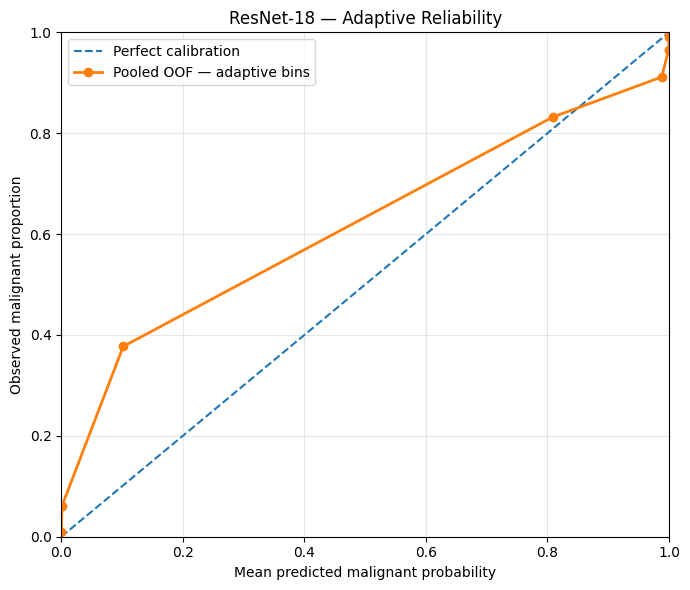


REPAIRED ADAPTIVE ECE SUMMARY


,fold,patients,images,equal_width_ece,adaptive_ece
0,1,17,372,0.074696,0.079137
1,2,16,431,0.099174,0.077761
2,3,16,330,0.037631,0.035072
3,pooled,49,1133,0.056472,0.052456



STAGE 4 ADAPTIVE ECE REPAIR
Pooled adaptive ECE: 0.052456

PASS: Original adaptive ECE values reproduced.
PASS: Missing reliability bins CSV restored.
PASS: Missing adaptive summary CSV restored.
PASS: Missing adaptive reliability figure restored.
PASS: All three files are in the Stage 4 directory.


In [15]:

# ============================================================
# Repair missing adaptive ECE artifacts
# No model training or bootstrap reruns required
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path("/content/breast-histology-calibration")

analysis_dir = (
    REPO_ROOT /
    "results" /
    "formal_development" /
    "resnet18" /
    "cross_fold_analysis"
)

assert analysis_dir.is_dir()

# ------------------------------------------------------------
# 1. Load previously verified OOF predictions
# ------------------------------------------------------------

oof_path = (
    analysis_dir /
    "resnet18_combined_oof_predictions.csv"
)

assert oof_path.is_file(), (
    "Verified OOF predictions are missing."
)

oof_repair = pd.read_csv(
    oof_path,
    dtype={"patient_id": str}
)

assert len(oof_repair) == 1133
assert oof_repair["patient_id"].nunique() == 49
assert oof_repair["filename"].is_unique

# ------------------------------------------------------------
# 2. Reconstruct adaptive reliability bins
# ------------------------------------------------------------

def rebuild_adaptive_bins(df, n_bins=10):

    y = df["label"].to_numpy(dtype=int)
    p = df["probability"].to_numpy(dtype=float)

    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()

    order = np.argsort(p, kind="stable")
    groups = np.array_split(order, n_bins)

    rows = []

    for i, indices in enumerate(groups, start=1):

        probabilities = p[indices]
        outcomes = y[indices]

        mean_p = float(probabilities.mean())
        observed = float(outcomes.mean())
        gap = abs(mean_p - observed)

        rows.append({
            "bin": i,
            "count": len(indices),
            "minimum_probability": float(
                probabilities.min()
            ),
            "maximum_probability": float(
                probabilities.max()
            ),
            "mean_probability": mean_p,
            "observed_malignancy_rate": observed,
            "absolute_gap": gap,
            "ece_contribution": (
                len(indices) / len(df) * gap
            )
        })

    return pd.DataFrame(rows)


pooled_adaptive = rebuild_adaptive_bins(
    oof_repair
)

pooled_ece = float(
    pooled_adaptive["ece_contribution"].sum()
)

# Verify against previously reported result
assert np.isclose(
    pooled_ece,
    0.052456,
    atol=1e-6
), f"Adaptive ECE mismatch: {pooled_ece}"

# ------------------------------------------------------------
# 3. Regenerate summary for each fold
# ------------------------------------------------------------

original_ece = {
    1: 0.074696,
    2: 0.099174,
    3: 0.037631
}

expected_adaptive = {
    1: 0.079137,
    2: 0.077761,
    3: 0.035072
}

rows = []

for fold in [1, 2, 3]:

    df = oof_repair.loc[
        oof_repair["validation_fold"] == fold
    ]

    bins = rebuild_adaptive_bins(df)

    adaptive_ece = float(
        bins["ece_contribution"].sum()
    )

    assert np.isclose(
        adaptive_ece,
        expected_adaptive[fold],
        atol=1e-6
    ), f"Fold {fold} adaptive ECE mismatch"

    rows.append({
        "fold": fold,
        "patients": df["patient_id"].nunique(),
        "images": len(df),
        "equal_width_ece": original_ece[fold],
        "adaptive_ece": adaptive_ece
    })

rows.append({
    "fold": "pooled",
    "patients": 49,
    "images": 1133,
    "equal_width_ece": 0.056472,
    "adaptive_ece": pooled_ece
})

adaptive_summary = pd.DataFrame(rows)

# ------------------------------------------------------------
# 4. Save both missing CSV files
# ------------------------------------------------------------

bins_path = (
    analysis_dir /
    "resnet18_pooled_adaptive_reliability_bins.csv"
)

summary_path = (
    analysis_dir /
    "resnet18_adaptive_ece_summary.csv"
)

pooled_adaptive.to_csv(
    bins_path,
    index=False
)

adaptive_summary.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 5. Regenerate adaptive reliability figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.plot(
    pooled_adaptive["mean_probability"],
    pooled_adaptive["observed_malignancy_rate"],
    marker="o",
    linewidth=2,
    label="Pooled OOF — adaptive bins"
)

ax.set(
    xlabel="Mean predicted malignant probability",
    ylabel="Observed malignant proportion",
    title="ResNet-18 — Adaptive Reliability",
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

figure_path = (
    analysis_dir /
    "resnet18_pooled_adaptive_reliability.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. Verify all repaired files
# ------------------------------------------------------------

for path in [
    bins_path,
    summary_path,
    figure_path
]:
    assert path.is_file(), f"Missing: {path}"

assert pooled_adaptive["count"].sum() == 1133

print("\nREPAIRED ADAPTIVE ECE SUMMARY")
display(adaptive_summary.round(6))

print("\n" + "=" * 60)
print("STAGE 4 ADAPTIVE ECE REPAIR")
print("=" * 60)

print("Pooled adaptive ECE:", round(pooled_ece, 6))

print("\nPASS: Original adaptive ECE values reproduced.")
print("PASS: Missing reliability bins CSV restored.")
print("PASS: Missing adaptive summary CSV restored.")
print("PASS: Missing adaptive reliability figure restored.")
print("PASS: All three files are in the Stage 4 directory.")
